# ANÁLISE DO DESENVOLVIMENTO HUMANO E ECONÔMICO GLOBAL

### Python para Ciência de Dados

### **Grupo:** André Marcus Ribeiro Beiral, Gabriel Moreira Oliveira, Leandro Carmo Mendes e Thiago André Leite Patente

## 1. Introdução

### Tema do projeto
O tema central deste projeto é a Análise do Desenvolvimento Humano e Econômico Global com Base no Dataset Gapminder entregue pela atividade. Este estudo propõe a realização de uma Análise Exploratória de Dados (AED) para investigar os fatores socioeconômicos que moldam o bem-estar e a qualidade de vida das populações ao redor do mundo.

### Objetivos da análise
O objetivo principal é analisar o desenvolvimento humano e econômico de diferentes países ao longo das décadas. Com isso, a análise busca:
* Compreender as tendências globais, observando a evolução da expectativa de vida e do PIB per capita ao longo do tempo.
* Identificar padrões regionais e históricos, bem como as disparidades entre continentes e países.
* Explorar as relações e correlações entre riqueza média, expectativa de vida e outras questões populacionais.
* Visualizar o progresso global e destacar as resultados por meio de representações gráficas.

### Contexto da base de dados Gapminder
O conjunto de dados Gapminder é uma coleção com alguns indicadores socioeconômicos e de saúde desenvolvida a partir do trabalho da Fundação Gapminder. Criada pelo médico e estatístico sueco Hans Rosling, a organização tem o objetivo de promover uma visão do desenvolvimento global estritamente baseada em dados. 

A base contém informações de mais de 140 países, cobrindo o período histórico de 1952 a 2007 em intervalos de cinco anos. Os principais indicadores presentes são a expectativa de vida ao nascer (lifeExp), o Produto Interno Bruto per capita ajustado pela paridade do poder de compra (gdpPercap) e a população total (pop).

### Etapas realizadas no notebook

O desenvolvimento do projeto será organizado nas seguintes etapas:

1. **Introdução e importação de bibliotecas:** Realiza a introdução do projeto e as importações principais usadas para o projeto.
2. **Coleta, limpeza e tratamento dos dados:** Faz a leitura dos arquivos necessarios, trata os valores, fazendo a limpeza, transformações e organização das informações.
3. **Funções de Visualização e Análise Gráfica:** Desenvolvimento de funções para facilitar a construção e personalização das visualizações dos dados.
4. **Interpretação das Visualizações:** Perguntas a serem respondidas com base nos dados e nas visualizações gráficas contruida pelo grupo.
5. **Síntese dos Principais Insights:** Fazer um resumo dos principais pontos descobertos pelas análises, destacando padrões, tendências, anomalias e correlações entre os dados.
6. **Conclusão e Reflexão:** Refletir sobre o processo de análise e o aprendizado obtido, apresentando as considerações finais do trabalho.

### Importação das bibliotecas

In [1]:
%pip install pandas numpy matplotlib seaborn scipy openpyxl charset-normalizer

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Importar as bibliotecas que serão utilizadas pelo grupo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import csv
from charset_normalizer import from_bytes #Para detectar encoding e separador dos arquivos automaticamente
import urllib.request as ur   #Para aceitar base de dados que venham de URL
from pathlib import Path
import sys
import openpyxl 


INICIO = (
    Path(__file__).resolve().parent
    if "__file__" in globals()
    else Path.cwd().resolve()
)

# Procura a raiz do projeto na pasta inicial e nas pastas superiores.
PROJETO = next(
    (pasta for pasta in [INICIO, *INICIO.parents]
     if (pasta / "Notebook" / "util").is_dir() and (pasta / "data" / "Turismo").is_dir()),
    None,
)

if PROJETO is None:
    raise FileNotFoundError(
        "Não encontrei a raiz do projeto. "
    )

sys.path.insert(0, str(PROJETO / "Notebook"))

from util import (
    ler_tabela_sidra_horizontal,
    ler_csv_flexivel,
    padronizar_serie_por_codigo,
    resumo_duplicados,
    remover_duplicados,
    resumo_ausentes,
    verificar_cobertura,
    filtrar_anos,
    juntar_por_uf_ano,
    variacao_entre_anos,
    indice_base,
    tabela_contingencia,
    teste_robustez,
    grafico_dispersao,
    grafico_total_por_ano,
    grafico_indice_ufs,
    salvar_dataframe,
    salvar_figura,

    ler_titulo_ipeadata,
    identificar_arquivo_ipeadata,
    ler_ipeadata_por_uf,
    ler_ipeadata_serie_anual,
    juntar_indicador,
    variacao_indicador,
    tabela_contingencia_indicador,
    teste_robustez_indicador,
    resumo_choque_indicador,
    grafico_dispersao_indicador,
    grafico_indices_duplos,

     achar_aba, achar_coluna, 
     ler_brent, 
     brent_anual, 
     ler_tabela_anual,
    ler_rodoviario, 
    total_oficial_rodoviario, 
    quedas_bruscas, 
    ranking_ufs,
    juntar_series_anuais, 
    variacoes_anuais, 
    tabela_contingencia_sinais,
    teste_robustez_series, 
    grafico_brent_anual,
    grafico_indices_brent,
    grafico_dispersao_anos, 
    grafico_barras_uf,
    ler_voos,
    ler_tarifa,
    ler_custos
)

import util

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)



# Mantemos os caminhos relativos à pasta do projeto.
ARQ_TURISMO = PROJETO / "data" / "Turismo" / "Tabela 7266.xlsx"
ARQ_HOMICIDIOS = (
    PROJETO / "data" / "Turismo" / "Taxa de homicídios registrados_estados.csv"
)

ARQUIVOS_IPEA = sorted((PROJETO / "data" / "Turismo").glob("ipeadata*.csv"))


SAIDA = PROJETO / "data" / "Turismo" / "saida"
SAIDA.mkdir(parents=True, exist_ok=True)

ANOS_ANALISE_SEGURANCA = [2019, 2020, 2021, 2023, 2024]
ANOS_PANDEMIA = [2020, 2021]

PAR_PRINCIPAL_SEGURANCA = (2023, 2024)
PAR_LONGO_SEGURANCA = (2019, 2024)

PAR_PRINCIPAL_PIB = (2019, 2023)
PAR_RECUPERACAO_PIB = (2021, 2023)
PAR_CHOQUE_PIB = (2019, 2020)

DADOS = PROJETO / "data" / "Turismo"
ARQ_BRENT = next(DADOS.glob("Dados Históricos - Petróleo Brent Futuros.csv"))
ARQ_ROD = DADOS / "ROD_1_5_4_1_1.xlsx"
ARQ_ANUARIO = next(DADOS.glob("anuario_2025 versão final.xlsx"))

# Apenas cenários exploratórios de sensibilidade.
# Nenhuma UF é retirada da base principal.
CENARIOS = {
    "Todas as UFs": [],
    "Sem Roraima": ["RR"],
    "Sem Roraima e Amapá": ["RR", "AP"],
}

CHAVES = ["cod_ibge", "ano"]



---

## 2. Coleta, Limpeza e Análise Exploratória (AED)

**Objetivo:** preparar os dados, tratando inconsistências e identificando padrões iniciais. Esta seção está organizada por fonte de dados:
- **2.1 Gapminder:** coleta, exploração inicial, limpeza e transformação.
- **2.2 Bases externas (Banco Mundial):** preparação dos indicadores externos e junção com o Gapminder limpo.
- **2.3 Saúde:** preparação das bases complementares e integração com o Gapminder.
- **2.4 Turismo:** coleta, limpeza, transformação e integração das bases de turismo.
- **2.5 Educação e Transporte:** preparação de indicadores de escolaridade, gasto em educação, infraestrutura e qualidade das rodovias, utilizando o Gapminder já tratado na subseção 2.1.


### 2.1 Gapminder

#### 2.1.1 Coleta de Dados

O primeiro passo é carregar a base Gapminder e registrar sua origem. Confiram se o arquivo foi disponibilizado junto com o trabalho e anotem a fonte utilizada.

In [3]:
# Informar o caminho correto do arquivo disponibilizado para a atividade
df = pd.read_csv('../data/gapminder_full.csv')

df.head()


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106


In [4]:
df.shape

(1736, 6)

#### 2.1.2 Exploração Inicial dos Dados

Antes de tratar os dados, verificar a estrutura do DataFrame e entender os itens em cada colunas.

In [5]:
# Consultar estatísticas descritivas

df.info()

df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 1736 entries, 0 to 1735
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1736 non-null   str    
 1   year       1736 non-null   int64  
 2   pop        1736 non-null   float64
 3   continent  1736 non-null   str    
 4   lifeExp    1736 non-null   float64
 5   gdpPercap  1736 non-null   float64
dtypes: float64(3), int64(1), str(2)
memory usage: 81.5 KB


,year,pop,lifeExp,gdpPercap
count,1736.00,1.736000e+03,1736.00,1736.00
mean,1979.67,3.156800e+07,59.51,7240.16
std,17.30,1.172888e+08,12.96,9839.87
min,1952.00,6.001100e+04,23.60,241.17
25%,1967.00,2.818694e+06,48.24,1202.06
50%,1982.00,7.150606e+06,60.81,3534.77
75%,1997.00,1.977102e+07,70.94,9380.25
max,2007.00,1.318683e+09,82.60,113523.13


In [6]:
# Verificar os países, continentes e anos presentes na base
print('Quantidade de países:', df['country'].nunique())
print('Continentes:', df['continent'].unique())
print('Anos:', df['year'].unique())

Quantidade de países: 142
Continentes: <StringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
Anos: [1952 1957 1962 1967 1972 1977 1982 1987 1992 1997 2002 2007]


In [7]:
# Quantidade de países em cada continente
df.groupby('continent')['country'].nunique()

continent
Africa      52
Americas    25
Asia        33
Europe      30
Oceania      2
Name: country, dtype: int64

In [8]:
# (se cada país aparecesse só uma vez, seriam 142 linhas por ano)
df['year'].value_counts().sort_index()

year
1952    143
1957    143
1962    144
1967    144
1972    144
1977    143
1982    143
1987    146
1992    144
1997    147
2002    147
2007    148
Name: count, dtype: int64

**Anotações**
- **Colunas disponíveis:** `country` (país), `year` (ano), `pop` (população), `continent` (continente), `lifeExp` (expectativa de vida) e `gdpPercap` (PIB per capita). São 6 colunas e 1.736 linhas.
- **Período coberto:** de 1952 a 2007, de 5 em 5 anos (12 anos no total).
- **Países e continentes:** 142 países em 5 continentes. A Oceania tem só 2 países, então a média dela deve ser vista com cuidado.
- **O que verificar antes da limpeza:**
  - Cada ano tem entre 143 e 148 linhas, mas o esperado era 142 (um por país). Isso indica que possivelmente existem linhas **duplicadas**.
  - A coluna `pop` está como número decimal (`float64`), mas população é uma contagem de pessoas.

#### 2.1.3 Limpeza de Dados

A atividade solicita excluir os dados ausentes e eliminar registros duplicados. Antes e depois da limpeza, registrem a quantidade de linhas e as decisões tomadas.

In [9]:
# Verificar a quantidade de valores ausentes por coluna | Limpeza abaixo
print('Linhas antes da limpeza:', len(df))
df.isna().sum()

df = df.dropna()
print('Linhas após a limpeza dos valores nulos:', len(df))

Linhas antes da limpeza: 1736
Linhas após a limpeza dos valores nulos: 1736


In [10]:
# Verificar a quantidade de registros duplicados
print(f'Linhas duplicadas: {df.duplicated().sum()}')
print('Abaixo há exmeplos de linhas duplicadas. É possivel verificar essas linhas no arquivo completo do "gapminder_full.csv"')

df[df.duplicated()].head(10)

Linhas duplicadas: 32
Abaixo há exmeplos de linhas duplicadas. É possivel verificar essas linhas no arquivo completo do "gapminder_full.csv"


,country,year,pop,continent,lifeExp,gdpPercap
72,Afghanistan,1997,2.222742e+07,Asia,41.763,635.341351
145,Bolivia,1987,6.156369e+06,Americas,57.251,2753.691490
146,Bolivia,1992,6.893451e+06,Americas,59.957,2961.699694
147,Bolivia,1997,7.693188e+06,Americas,62.050,3326.143191
148,Bolivia,2002,8.445134e+06,Americas,63.883,3413.262690
149,Bolivia,2007,9.119152e+06,Americas,65.554,3822.137084
161,Belgium,2007,1.039223e+07,Europe,79.441,33692.605080
207,Burkina Faso,1987,7.586551e+06,Africa,49.557,912.063142
232,Cambodia,1987,8.371791e+06,Asia,53.914,683.895573
345,China,1997,1.230075e+09,Asia,70.426,2289.234136


In [11]:
# Eliminar registros duplicados e corrigindo os indices conforme ensinado
print('Linhas antes da limpeza:', len(df))
df = df.drop_duplicates()

print('Linhas após a limpeza dos duplicados:', len(df))
df = df.reset_index(drop=True)
df_gapminder = df.copy()

Linhas antes da limpeza: 1736
Linhas após a limpeza dos duplicados: 1704


In [12]:
# Conferir a base após a limpeza

print('Linhas depois da limpeza:', len(df))
print('Duplicados restantes:', df.duplicated().sum())
print('Ausentes restantes:', df.isna().sum().sum())
df['year'].value_counts().sort_index()

Linhas depois da limpeza: 1704
Duplicados restantes: 0
Ausentes restantes: 0


year
1952    142
1957    142
1962    142
1967    142
1972    142
1977    142
1982    142
1987    142
1992    142
1997    142
2002    142
2007    142
Name: count, dtype: int64

**Decisões de tratamento**
- **Valores ausentes:** nenhum foi encontrado. Mantendo a mesma quantidade de linhas antes e após a limpeza.
- **Duplicados:** foram encontradas e removidas (32 linhas duplicadas).
- **Registros que restaram:** de 1.736 para 1.704 linhas, que é 142 países × 12 anos. Da forma que era esperado na etapa 2

#### 2.1.4 Transformação e Preparação dos Dados

Avaliando se é necessário ajustar tipos de dados, nomes de colunas ou outras tarefas para facilitar as análises.

In [13]:
# Vê quais dados poderm ser alterados e converte a população para inteiros
df.info()

df['pop'] = df['pop'].round().astype('int64')
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   year       1704 non-null   int64  
 2   pop        1704 non-null   float64
 3   continent  1704 non-null   str    
 4   lifeExp    1704 non-null   float64
 5   gdpPercap  1704 non-null   float64
dtypes: float64(3), int64(1), str(2)
memory usage: 80.0 KB


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,Asia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710
3,Afghanistan,1967,11537966,Asia,34.020,836.197138
4,Afghanistan,1972,13079460,Asia,36.088,739.981106


In [14]:
# Cria uma base de dados limpa que vai ser utilizada para fazer as análises
df.to_csv('../data/gapminder_limpo.csv', index=False)

### 2.2 World Bank

Para responder perguntas sobre inflação, comércio, desemprego e diferença de expectativa de vida entre homens e mulheres, será utilizado bases do "Banco Mundial (World Development Indicators)", baixadas em https://data.worldbank.org.

Aqui vai ser feito a preparação dos dados para comn=binar com o gapMinder que limpamos:
1. Ler os arquivos baixados.
2. Arrumar o formato da tabela (uma linha por país e ano).
3. Conferir se os nomes dos países batem com os do Gapminder.
4. Juntar com o `df` (Gapminder limpo) usando `country` e `year`.
5. Ver quantos dados ausentes sobraram.

#### 2.2.1 Economia (André)

Bases externas que será usada para analise de perguntas relacionadas a economia:

| Nome da coluna | Indicador do Banco Mundial | Unidade |
|---|---|---|
| `inflacao` | Inflação, preços ao consumidor | % ao ano |
| `comercio` | Comércio (exportações + importações) | % do PIB |
| `cresc_pib` | Crescimento do PIB per capita | % ao ano |
| `desemprego` | Desemprego total (estimativa modelada da OIT) | % da força de trabalho |
| `vida_f` | Expectativa de vida ao nascer, mulheres | anos |
| `vida_m` | Expectativa de vida ao nascer, homens | anos |

In [15]:
# Organizando os caminhos para os arquivos, já que serão usados em algumas analises.

pasta = '../data/Economia/'

arquivos_economia = {
    'inflacao':   'API_FP.CPI.TOTL.ZG_DS2_en_csv_v2_1323.csv',
    'comercio':   'API_NE.TRD.GNFS.ZS_DS2_en_csv_v2_1202.csv',
    'cresc_pib':  'API_NY.GDP.PCAP.KD.ZG_DS2_en_csv_v2_6324.csv',
    'desemprego': 'API_SL.UEM.TOTL.ZS_DS2_en_csv_v2_1675.csv',
    'vida_f':     'API_SP.DYN.LE00.FE.IN_DS2_en_csv_v2_7315.csv',
    'vida_m':     'API_SP.DYN.LE00.MA.IN_DS2_en_csv_v2_3426.csv',
}

***Padronizando e lendo os arquivos***

O Gapminder e as fontes de dados vindo do WorldBank possuem uma estrutura diferente, então vai ser criado uma função simples, para não repetir o mesmo código seis vezes.
O 'melt' é usado para padronizar as colunas de anos em linhas, para facilitar a leitura, já os arquivos são diferentes

In [16]:
def ler_indicador(arquivo, nome_coluna):

    tabela = pd.read_csv(pasta + arquivo, skiprows=4)

    # Colunas que não iremos usar
    tabela = tabela.drop(columns=['Country Code', 'Indicator Name', 'Indicator Code', 'Unnamed: 70'],
                         errors='ignore')


    tabela = tabela.melt(id_vars='Country Name', var_name='year', value_name=nome_coluna)


    tabela = tabela.rename(columns={'Country Name': 'country'})
    tabela['year'] = tabela['year'].astype(int)

    return tabela

***Junta os indicadores***
Juntando os indicadores para estarem em uma tabela

In [17]:
# Começa vazia e vai juntando um indicador por vez
wb_economia = None

for nome, arquivo in arquivos_economia.items():
    tabela = ler_indicador(arquivo, nome)

    if wb_economia is None:
        wb_economia = tabela
    else:
        wb_economia = wb_economia.merge(tabela, on=['country', 'year'], how='outer')

print('Linhas e colunas:', wb_economia.shape)
wb_economia.head()

Linhas e colunas: (17556, 8)


,country,year,inflacao,comercio,cresc_pib,desemprego,vida_f,vida_m
0,Afghanistan,1960,NaN,NaN,NaN,NaN,33.549,32.136
1,Afghanistan,1961,NaN,NaN,NaN,NaN,34.043,32.626
2,Afghanistan,1962,NaN,NaN,NaN,NaN,34.502,33.098
3,Afghanistan,1963,NaN,NaN,NaN,NaN,34.945,33.543
4,Afghanistan,1964,NaN,NaN,NaN,NaN,35.428,34.004


Como tem uma descrepancia no nome dos paises entre essas duas fontes, vamos verificar e modificar as que conseguimos

In [18]:
# Países do Gapminder que não aparecem no WorldBank
paises_gapminder = set(df['country'].unique())
paises_wb = set(wb_economia['country'].unique())

nao_encontrados = sorted(paises_gapminder - paises_wb)
print('Quantidade:', len(nao_encontrados))
print(nao_encontrados)

Quantidade: 19
['Congo Dem. Rep.', 'Congo Rep.', 'Czech Republic', 'Egypt', 'Gambia', 'Hong Kong China', 'Iran', 'Korea Dem. Rep.', 'Korea Rep.', 'Puerto Rico', 'Reunion', 'Somalia', 'Swaziland', 'Syria', 'Taiwan', 'Turkey', 'Venezuela', 'Vietnam', 'Yemen Rep.']


In [19]:
# Corrigindo o nome de paises do World Bank para o nome no Gapminder
correcao_nomes = {
    'Congo, Dem. Rep.': 'Congo Dem. Rep.',
    'Congo, Rep.': 'Congo Rep.',
    'Czechia': 'Czech Republic',
    'Egypt, Arab Rep.': 'Egypt',
    'Gambia, The': 'Gambia',
    'Hong Kong SAR, China': 'Hong Kong China',
    'Iran, Islamic Rep.': 'Iran',
    "Korea, Dem. People's Rep.": 'Korea Dem. Rep.',
    'Korea, Rep.': 'Korea Rep.',
    'Puerto Rico (US)': 'Puerto Rico',
    'Somalia, Fed. Rep.': 'Somalia',
    'Eswatini': 'Swaziland',
    'Syrian Arab Republic': 'Syria',
    'Turkiye': 'Turkey',
    'Venezuela, RB': 'Venezuela',
    'Viet Nam': 'Vietnam',
    'Yemen, Rep.': 'Yemen Rep.',
}

wb_economia['country'] = wb_economia['country'].replace(correcao_nomes)

# Conferindo de novo quais países continuam sem correspondência
paises_wb = set(wb_economia['country'].unique())
print('Ainda não encontrados:', sorted(paises_gapminder - paises_wb))

Ainda não encontrados: ['Reunion', 'Taiwan']


In [20]:
# Junta o Gapminder limpo com os indicadores do WB depois remove ausentes
df_economia = df.merge(wb_economia, on=['country', 'year'], how='left')

print('Linhas antes:', len(df))
print('Linhas depois:', len(df_economia))
print('Duplicados em país/ano:', df_economia.duplicated(['country', 'year']).sum())

df_economia.head()



Linhas antes: 1704
Linhas depois: 1704
Duplicados em país/ano: 0


,country,year,pop,continent,lifeExp,gdpPercap,inflacao,comercio,cresc_pib,desemprego,vida_f,vida_m
0,Afghanistan,1952,8425333,Asia,28.801,779.445314,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1957,9240934,Asia,30.332,820.853030,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1962,10267083,Asia,31.997,853.100710,NaN,NaN,NaN,NaN,34.502,33.098
3,Afghanistan,1967,11537966,Asia,34.020,836.197138,NaN,NaN,NaN,NaN,36.851,35.324
4,Afghanistan,1972,13079460,Asia,36.088,739.981106,NaN,NaN,NaN,NaN,39.255,37.681


In [21]:
df_economia.isna().sum()
colunas_wb = list(arquivos_economia.keys())

df_economia.groupby('year')[colunas_wb].count()

,inflacao,comercio,cresc_pib,desemprego,vida_f,vida_m
year,,,,,,
1952,0,0,0,0,0,0
1957,0,0,0,0,0,0
1962,62,59,100,0,139,139
1967,78,70,104,0,139,139
1972,84,92,112,0,139,139
1977,88,95,114,0,139,139
1982,93,101,122,0,139,139
1987,103,103,124,0,139,139
1992,111,114,133,140,140,140


### 2.3 Saúde (Leandro)

Nesta parte eu trago quatro bases de dados novas para cruzar com a expectativa de vida e o PIB
per capita do Gapminder. Com elas eu respondo cinco perguntas:

1. Países que gastam mais em saúde per capita têm maior expectativa de vida, mesmo quando o PIB per capita é parecido?
2. A mortalidade infantil explica melhor as diferenças de expectativa de vida entre países ricos e pobres do que o PIB per capita?
3. A taxa de obesidade cresce junto com o PIB per capita?
4. Países com mais médicos por mil habitantes têm maior expectativa de vida, mesmo descontando o efeito do PIB per capita?
5. Países que gastam mais em saúde por pessoa têm menor mortalidade infantil?


#### 2.3.1 Coleta de Dados

**#Importa bases de dados**


In [22]:
# Substitua a URL abaixo pela URL 'raw' do seu arquivo no GitHub
url_github =['../data/gapminder_limpo.csv',
              '../data/Saude/gasto_saude_per_capita.csv',
              '../data/Saude/medicos_por_1000_habitantes.csv',
              '../data/Saude/mortalidade_infantil.csv',
              '../data/Saude/taxa_obesidade.csv']


**#Detecta o tipo de Encoding e Separador de CSVs**


In [23]:
def configuraçoes_csv(caminho_arquivo):
    """
    Descobre o encoding e o separador de qualquer CSV de forma rápida e certeira.
    Aceita tanto arquivos locais quanto links da internet (ex: GitHub).
    Retorna: (encoding, separador).
    """

    # 1. Verifica se é um link da internet ou arquivo local
    if caminho_arquivo.startswith('http://') or caminho_arquivo.startswith('https://'):   # Verifica se começa com um dos termos
        # Se for link, faz uma requisição HTTP e lê os primeiros 20.000 bytes
        req = ur.Request(
            caminho_arquivo,
            headers={'User-Agent': 'Mozilla/5.0'} # Simula um cabeçalho real na requisição como se fosse um usuário acessando pelo Mozila
        )
        with ur.urlopen(req) as f:   # Abre a conexão com o servidor através da requisição anterior criada
            amostra_binaria = f.read(20000)   #Lê e armazena os primeiros 20000 bytes em amostra_binária
                                              #NOTA: não usamos open(caminho_arquivo, "rb") pq na internet tudo já está em byte
    else:
        # Se for arquivo local, abre normalmente
        with open(caminho_arquivo, 'rb') as f:    #Aqui usamos o 'rb' pois arquivos locais não costuman estar em binário pois nós não conseguiriamos ler.
            amostra_binaria = f.read(20000)

    amostra_binaria = amostra_binaria.replace(b'\r\n', b'\n')
    
    # 2. Descobre o encoding com quase 100% de precisão
    resultado = from_bytes(amostra_binaria).best()  # Analisa a amostra binária
    encoding = resultado.encoding   # Armazena o nome do encoding detectado
    texto_amostra = str(resultado)    # Converte em texto legível novamente

    # 3. Descobre o separador (.csv, .txt, etc)
    dialeto = csv.Sniffer().sniff(texto_amostra)    #"Fareja" em nossa amostra qual o separador mais aparece e
    separador = dialeto.delimiter

    return caminho_arquivo,encoding, separador

**#Cria um único DataFrame**

In [24]:
def cria_dataframe(caminho_arquivo,encoding,separador):
    df=pd.read_csv(caminho_arquivo, encoding=encoding, sep=separador)
    return df


**#Cria múltiplos DataFrames recebendo lista de URLs ou CSVs**

In [25]:
def carrega_multiplos_dataframes(lista_caminhos):
    """
    Recebe uma lista de URLs ou caminhos locais e retorna uma lista de DataFrames carregados
    automaticamente usando as configurações detectadas para cada um deles.

    **Exemplo de entrada:**
    lista caminhos= [url1, url2, url3, ...] ou [caminho1, caminho2, caminho3, ...]

    **Exemplo de saída:**
    dataframes= [df1, df2, df3, ...]
    """
    dataframes = []   #cria uma lista vazia para nosso append ir add oq precisa
    for caminho in lista_caminhos:
        # 1. Detecta as configurações do arquivo atual
        config = configuraçoes_csv(caminho)
        # 2. Cria o DataFrame correspondente
        df = cria_dataframe(*config)#garante que cada termo da tupla seja descompactado e utilizado na função
        # 3. Adiciona o DataFrame à lista
        dataframes.append(df)
    return dataframes

# Exemplo de uso prático:
# lista_de_fontes = [url_github]  # Você pode colocar quantos links ou caminhos quiser aqui
# meus_dfs = carregar_multiplos_dataframes(lista_de_fontes)
# meus_dfs[0].head()  # Acessa o primeiro DataFrame gerado

**#Apresenta um DICIONÁRIO de nomes para cada Dataframe na lista**

In [26]:
nomes = ['gapminder', 'saude', 'medicos', 'mortalidade', 'obesidade'] #Cria uma lista de nomes para nossas bases de dados
dataframes_copia = carrega_multiplos_dataframes(url_github).copy() #Copia nossa lista de tabelas para comecarmos o tratamento de dados
df_brutos = dict(zip(nomes, dataframes_copia)) #Cria Dicionários e nomeia as tabelas com os nomes da lista acima


**#Função Superior para aplicar outras funções em cada um dos Dataframes de uma lista de tabelas**


In [27]:
def aplicar_funcoes(dicionario, funcao, decisor):
  """
  Aplica uma função a todas as tabelas de um dicionário {nome: tabela}.

  Parâmetros:
    dicionario : dicionário {nome: DataFrame} a processar.
    funcao     : função a ser aplicada em cada tabela.
    decisor    : 1 → transformar (sobrescreve as tabelas com o resultado da função);
                 0 → visualizar/investigar (apenas executa, etiquetando pelo nome; não altera);
                 2 → coletar (não altera o original; devolve um dicionário novo {nome: resultado}).

  Retorno:
    decisor=1 → dicionário com as tabelas transformadas;
    decisor=0 → o dicionário original (inalterado);
    decisor=2 → dicionário novo {nome: resultado da função}.
  """
  if decisor not in (0, 1, 2):
    raise ValueError("decisor deve ser 0 (visualizar), 1 (transformar) ou 2 (coletar)")

  if decisor == 1:                                   # TRANSFORMAR
    dic_alterado = dicionario.copy()
    for nome in dic_alterado:
        dic_alterado[nome] = funcao(dic_alterado[nome])
    return dic_alterado

  elif decisor == 2:                                 # COLETAR
    resultados = {}
    for nome, tabela in dicionario.items():
        resultados[nome] = funcao(tabela)
    return resultados

  else:                                              # VISUALIZAR (decisor == 0)
    for nome, tabela in dicionario.items():
        print(f'\n===== {nome} =====')
        funcao(tabela)
    return dicionario

#### 2.3.2 Limpeza de Dados

Confiro valores duplicados e ausentes. Removo os duplicados; os ausentes eu deixo como estão aqui,
porque cada indicador tem anos diferentes — na hora de cada análise eu uso só as colunas necessárias
(as funções de gráfico já descartam os valores vazios).

#### 2.3.2.1 Limpeza de Dados(Base saude Per Capita)

**#Exploracao inicial**

Aqui entendemos a estrutura da tabela:

1. Entity: País
2. Code: Cóidigo do país
3. Year: o Ano do dado
4. Current health expenditure (Current international $): Em média, esse país gasta com a saúde de cada cidadão o equivalente ao que X dólares comprariam de saúde dentro dos Estados Unidos (uma forma de equiparar as moedas)

Aqui conhecemos um pouco da estrutura da tabela

In [28]:
df_brutos['saude'].tail(10).round(1)

,Entity,Code,Year,"Current health expenditure per capita, PPP (current international $)"
4864,Zimbabwe,ZWE,2014,207.7
4865,Zimbabwe,ZWE,2015,197.2
4866,Zimbabwe,ZWE,2016,203.0
4867,Zimbabwe,ZWE,2017,149.8
4868,Zimbabwe,ZWE,2018,114.4
4869,Zimbabwe,ZWE,2019,90.0
4870,Zimbabwe,ZWE,2020,103.8
4871,Zimbabwe,ZWE,2021,85.1
4872,Zimbabwe,ZWE,2022,119.0
4873,Zimbabwe,ZWE,2023,103.1


Aqui entendemos quantidade de nulos
e o tipo de dado de cada coluna

In [29]:
df_brutos['saude'].info()

<class 'pandas.DataFrame'>
RangeIndex: 4874 entries, 0 to 4873
Data columns (total 4 columns):
 #   Column                                                                Non-Null Count  Dtype  
---  ------                                                                --------------  -----  
 0   Entity                                                                4874 non-null   str    
 1   Code                                                                  4874 non-null   str    
 2   Year                                                                  4874 non-null   int64  
 3   Current health expenditure per capita, PPP (current international $)  4874 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 152.4 KB


Aqui Vizualizamos estatisticamente a distribuicao dos valores dentro dessa tabela

In [30]:
#Analize estatistica da tabela como um todo
df_brutos['saude'].describe().round(1)

,Year,"Current health expenditure per capita, PPP (current international $)"
count,4874.0,4874.0
mean,2011.7,1323.0
std,7.0,1790.9
min,2000.0,6.1
25%,2006.0,176.2
50%,2012.0,599.1
75%,2018.0,1701.9
max,2024.0,13473.2


Aqui Verificamos a quantidade de nulos e duplicados da base de dados para entendermos se faz necessaria uma limpeza ou não.

In [31]:
qtd_nulos = df_brutos['saude'].isna().sum()
print('Quantidade de nulos por coluna:')
print(qtd_nulos)

Quantidade de nulos por coluna:
Entity                                                                  0
Code                                                                    0
Year                                                                    0
Current health expenditure per capita, PPP (current international $)    0
dtype: int64


In [32]:
qtd_duplicados = df_brutos['saude'].duplicated().sum()
print('Quantidade de duplicados:', qtd_duplicados)

Quantidade de duplicados: 0


Aqui visualizamos as linhas duplicadas (se houver)

In [33]:
df_duplicados = df_brutos['saude'].duplicated(keep=False)
print('Linhas duplicadas:')
display(df_brutos['saude'][df_duplicados])

Linhas duplicadas:


,Entity,Code,Year,"Current health expenditure per capita, PPP (current international $)"


Por fim, vemos quantos valores únicos existem em cada coluna

In [34]:
df_brutos['saude'].nunique()

Entity                                                                   206
Code                                                                     206
Year                                                                      25
Current health expenditure per capita, PPP (current international $)    4874
dtype: int64

#### 2.3.2.2 Limpeza de Dados (Base Mortalidade Infantil)

**#Exploracao inicial**

Aqui entendemos a estrutura da tabela:

1. Entity: País
2. Code: Código do país
3. Year: o Ano do dado
4. Under-five mortality rate: a quantidade de crianças que morrem antes de completar 5 anos a cada 1.000 nascidas vivas naquele país e ano

Aqui conhecemos um pouco da estrutura da tabela

In [35]:
df_brutos['mortalidade'].tail(10).round(1)

,Entity,Code,Year,Under-five mortality rate (selected)
17056,Zimbabwe,ZWE,2015,5.9
17057,Zimbabwe,ZWE,2016,5.8
17058,Zimbabwe,ZWE,2017,5.7
17059,Zimbabwe,ZWE,2018,5.6
17060,Zimbabwe,ZWE,2019,5.9
17061,Zimbabwe,ZWE,2020,6.2
17062,Zimbabwe,ZWE,2021,6.2
17063,Zimbabwe,ZWE,2022,6.4
17064,Zimbabwe,ZWE,2023,6.4
17065,Zimbabwe,ZWE,2024,6.5


Aqui entendemos quantidade de nulos
e o tipo de dado de cada coluna

In [36]:
df_brutos['mortalidade'].info()

<class 'pandas.DataFrame'>
RangeIndex: 17066 entries, 0 to 17065
Data columns (total 4 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Entity                                17066 non-null  str    
 1   Code                                  17066 non-null  str    
 2   Year                                  17066 non-null  int64  
 3   Under-five mortality rate (selected)  17066 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 533.4 KB


Aqui Vizualizamos estatisticamente a distribuicao dos valores dentro dessa tabela

In [37]:
#Analize estatistica da tabela como um todo
df_brutos['mortalidade'].describe().round(1)

,Year,Under-five mortality rate (selected)
count,17066.0,17066.0
mean,1975.1,10.7
std,41.4,10.8
min,1751.0,0.1
25%,1960.0,2.1
50%,1984.0,6.5
75%,2004.0,16.6
max,2024.0,78.1


Aqui Verificamos a quantidade de nulos e duplicados da base de dados para entendermos se faz necessaria uma limpeza ou não.

In [38]:
qtd_nulos = df_brutos['mortalidade'].isna().sum()
print('Quantidade de nulos por coluna:')
print(qtd_nulos)

Quantidade de nulos por coluna:
Entity                                  0
Code                                    0
Year                                    0
Under-five mortality rate (selected)    0
dtype: int64


In [39]:
qtd_duplicados = df_brutos['mortalidade'].duplicated().sum()
print('Quantidade de duplicados:', qtd_duplicados)

Quantidade de duplicados: 0


Aqui visualizamos as linhas duplicadas (se houver)

In [40]:
df_duplicados = df_brutos['mortalidade'].duplicated(keep=False)
print('Linhas duplicadas:')
display(df_brutos['mortalidade'][df_duplicados])

Linhas duplicadas:


,Entity,Code,Year,Under-five mortality rate (selected)


Por fim, vemos quantos valores únicos existem em cada coluna

In [41]:
df_brutos['mortalidade'].nunique()

Entity                                   213
Code                                     213
Year                                     274
Under-five mortality rate (selected)    3340
dtype: int64

#### 2.3.2.3 Limpeza de Dados (Base Obesidade)

**#Exploracao inicial**

Aqui entendemos a estrutura da tabela:

1. Entity: País
2. Code: Código do país
3. Year: o Ano do dado
4. Obesity among adults (%): a porcentagem de adultos (18 anos ou mais) com obesidade (IMC maior ou igual a 30) naquele país e ano
5. World region according to OWID: a região/continente do país, segundo o Our World in Data

Aqui conhecemos um pouco da estrutura da tabela

In [42]:
df_brutos['obesidade'].tail(10).round(1)

,Entity,Code,Year,"Obesity among adults, BMI >= 30 kg/m2 (crude estimate) (%) - Sex: both sexes - Age group: 18+ years of age",World region according to OWID
9260,Zimbabwe,ZWE,2015,9.7,Africa
9261,Zimbabwe,ZWE,2016,10.1,Africa
9262,Zimbabwe,ZWE,2017,10.5,Africa
9263,Zimbabwe,ZWE,2018,10.9,Africa
9264,Zimbabwe,ZWE,2019,11.3,Africa
9265,Zimbabwe,ZWE,2020,11.6,Africa
9266,Zimbabwe,ZWE,2021,12.0,Africa
9267,Zimbabwe,ZWE,2022,12.4,Africa
9268,Zimbabwe,ZWE,2023,12.7,Africa
9269,Zimbabwe,ZWE,2024,13.1,Africa


Aqui entendemos quantidade de nulos
e o tipo de dado de cada coluna

In [43]:
df_brutos['obesidade'].info()

<class 'pandas.DataFrame'>
RangeIndex: 9270 entries, 0 to 9269
Data columns (total 5 columns):
 #   Column                                                                                                       Non-Null Count  Dtype  
---  ------                                                                                                       --------------  -----  
 0   Entity                                                                                                       9270 non-null   str    
 1   Code                                                                                                         9270 non-null   str    
 2   Year                                                                                                         9270 non-null   int64  
 3   Obesity among adults, BMI >= 30 kg/m2 (crude estimate) (%) - Sex: both sexes - Age group: 18+  years of age  9270 non-null   float64
 4   World region according to OWID                                          

Aqui Vizualizamos estatisticamente a distribuicao dos valores dentro dessa tabela

In [44]:
#Analize estatistica da tabela como um todo
df_brutos['obesidade'].describe().round(1)

,Year,"Obesity among adults, BMI >= 30 kg/m2 (crude estimate) (%) - Sex: both sexes - Age group: 18+ years of age"
count,9270.0,9270.0
mean,2002.0,15.8
std,13.0,13.2
min,1980.0,0.1
25%,1991.0,5.9
50%,2002.0,13.3
75%,2013.0,22.3
max,2024.0,75.8


Aqui Verificamos a quantidade de nulos e duplicados da base de dados para entendermos se faz necessaria uma limpeza ou não.

In [45]:
qtd_nulos = df_brutos['obesidade'].isna().sum()
print('Quantidade de nulos por coluna:')
print(qtd_nulos)

Quantidade de nulos por coluna:
Entity                                                                                                           0
Code                                                                                                             0
Year                                                                                                             0
Obesity among adults, BMI >= 30 kg/m2 (crude estimate) (%) - Sex: both sexes - Age group: 18+  years of age      0
World region according to OWID                                                                                 315
dtype: int64


In [46]:
qtd_duplicados = df_brutos['obesidade'].duplicated().sum()
print('Quantidade de duplicados:', qtd_duplicados)

Quantidade de duplicados: 0


Aqui visualizamos as linhas duplicadas (se houver)

In [47]:
df_duplicados = df_brutos['obesidade'].duplicated(keep=False)
print('Linhas duplicadas:')
display(df_brutos['obesidade'][df_duplicados])

Linhas duplicadas:


,Entity,Code,Year,"Obesity among adults, BMI >= 30 kg/m2 (crude estimate) (%) - Sex: both sexes - Age group: 18+ years of age",World region according to OWID


Por fim, vemos quantos valores únicos existem em cada coluna

In [48]:
df_brutos['obesidade'].nunique()

Entity                                                                                                          206
Code                                                                                                            206
Year                                                                                                             45
Obesity among adults, BMI >= 30 kg/m2 (crude estimate) (%) - Sex: both sexes - Age group: 18+  years of age    9269
World region according to OWID                                                                                    6
dtype: int64

#### 2.3.2.4 Limpeza de Dados (Base Médicos)

**#Exploracao inicial**

Aqui entendemos a estrutura da tabela:

1. Entity: País
2. Code: Código do país
3. Year: o Ano do dado
4. Physicians (per 1,000 people): a quantidade de médicos para cada 1.000 habitantes naquele país e ano

Aqui conhecemos um pouco da estrutura da tabela

In [49]:
df_brutos['medicos'].tail(10).round(1)

,Entity,Code,Year,"Physicians (per 1,000 people)"
5395,Zimbabwe,ZWE,2014,0.1
5396,Zimbabwe,ZWE,2015,0.2
5397,Zimbabwe,ZWE,2016,0.2
5398,Zimbabwe,ZWE,2017,0.2
5399,Zimbabwe,ZWE,2018,0.2
5400,Zimbabwe,ZWE,2019,0.1
5401,Zimbabwe,ZWE,2020,0.1
5402,Zimbabwe,ZWE,2021,0.1
5403,Zimbabwe,ZWE,2022,0.1
5404,Zimbabwe,ZWE,2023,0.1


Aqui entendemos quantidade de nulos
e o tipo de dado de cada coluna

In [50]:
df_brutos['medicos'].info()

<class 'pandas.DataFrame'>
RangeIndex: 5405 entries, 0 to 5404
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Entity                         5405 non-null   str    
 1   Code                           5405 non-null   str    
 2   Year                           5405 non-null   int64  
 3   Physicians (per 1,000 people)  5405 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 169.0 KB


Aqui Vizualizamos estatisticamente a distribuicao dos valores dentro dessa tabela

In [51]:
#Analize estatistica da tabela como um todo
df_brutos['medicos'].describe().round(1)

,Year,"Physicians (per 1,000 people)"
count,5405.0,5405.0
mean,1998.5,1.7
std,17.1,1.5
min,1960.0,0.0
25%,1987.0,0.4
50%,2001.0,1.4
75%,2013.0,2.8
max,2023.0,9.5


Aqui Verificamos a quantidade de nulos e duplicados da base de dados para entendermos se faz necessaria uma limpeza ou não.

In [52]:
qtd_nulos = df_brutos['medicos'].isna().sum()
print('Quantidade de nulos por coluna:')
print(qtd_nulos)

Quantidade de nulos por coluna:
Entity                           0
Code                             0
Year                             0
Physicians (per 1,000 people)    0
dtype: int64


In [53]:
qtd_duplicados = df_brutos['medicos'].duplicated().sum()
print('Quantidade de duplicados:', qtd_duplicados)

Quantidade de duplicados: 0


Aqui visualizamos as linhas duplicadas (se houver)

In [54]:
df_duplicados = df_brutos['medicos'].duplicated(keep=False)
print('Linhas duplicadas:')
display(df_brutos['medicos'][df_duplicados])

Linhas duplicadas:


,Entity,Code,Year,"Physicians (per 1,000 people)"


Por fim, vemos quantos valores únicos existem em cada coluna

In [55]:
df_brutos['medicos'].nunique()

Entity                            221
Code                              221
Year                               64
Physicians (per 1,000 people)    2767
dtype: int64

#### 2.3.2.5 Limpeza efetiva de todas as bases (gerando df_limpos)
Aqui aplico a limpeza em todas as bases de uma vez com a função aplicar_funcoes, criando o dicionário df_limpos.

In [56]:
# aplicar_funcoes (decisor=1) aplica a função em TODAS as tabelas e devolve o dicionário inteiro
df_limpos = aplicar_funcoes(df_brutos, lambda df: df.dropna(), 1)              # remove nulos
df_limpos = aplicar_funcoes(df_limpos, lambda df: df.drop_duplicates(), 1)     # remove duplicados
df_limpos = aplicar_funcoes(df_limpos, lambda df: df.reset_index(drop=True), 1)  # corrige o index

# Confere o resultado (df_brutos continua intacto)
for nome, tabela in df_limpos.items():
    print(f"{nome:15s}: {tabela.shape[0]} linhas | nulos: {int(tabela.isna().sum().sum())} | duplicados: {int(tabela.duplicated().sum())}")

gapminder      : 1704 linhas | nulos: 0 | duplicados: 0
saude          : 4874 linhas | nulos: 0 | duplicados: 0
medicos        : 5405 linhas | nulos: 0 | duplicados: 0
mortalidade    : 17066 linhas | nulos: 0 | duplicados: 0
obesidade      : 8955 linhas | nulos: 0 | duplicados: 0


#### 2.3.2.6 Padronização de dados entre todas as bases (gerando df_limpos_padronizados)


Aqui nós realizamos a padronizacao dos nomes dos paises em todas as bases de dados vinculadas as analizes da area de saude desse topico.

In [57]:
"""
   Aqui nós juntamos as tabelas pelo codigo do pais,
   e removemos linhas duplicadas, e ao fim refizemos o index
"""

# Lista das tabelas de saúde que você deseja extrair os códigos
tabelas_saude = [df_limpos['saude'], df_limpos['medicos'], df_limpos['mortalidade'], df_limpos['obesidade']]

# Filtra apenas as colunas 'Entity' e 'Code', junta todas e remove as duplicadas
codigos_paises = pd.concat([df[['Entity', 'Code']] for df in tabelas_saude]).drop_duplicates().reset_index(drop=True)

# Exibe o resultado
display(codigos_paises)

,Entity,Code
0,Afghanistan,AFG
1,Albania,ALB
2,Algeria,DZA
3,Andorra,AND
4,Angola,AGO
...,...,...
232,Oceania,OWID_OCE
233,South America,OWID_SAM
234,Taiwan,TWN
235,Turks and Caicos Islands,TCA


Após vizualizar a tabela dos códigos percebemos que alguns códigos não sao de paises e em sua maioria possuem mais de 3 digitos, sendo assim iremos criar outra tabela desses codigos para vizualizarmos se faz sentido permanecerem ali em nossa tabela de codigos de paises oficial.

In [58]:
# Filtra as linhas onde a coluna 'Code' possui comprimento maior que 3
codigos_longos = codigos_paises[codigos_paises['Code'].str.len() > 3]

# Exibe o resultado formatado
display(codigos_longos)

,Entity,Code
50,East Asia and Pacific (WB),WB_EAP
60,Europe and Central Asia (WB),WB_ECA
61,European Union (27),OWID_EU27
77,High-income countries,OWID_HIC
97,Latin America and Caribbean (WB),WB_LAC
105,Low-income countries,OWID_LIC
106,Lower-middle-income countries,OWID_LMC
119,"Middle East, North Africa, Afghanistan and Pak...",WB_MENAP
135,North America (WB),WB_NA
170,South Asia (WB),WB_SA


após verificarmos os nomes, achammos melhor realizarmos o drop desses dados para nao sujar nossa lista oficial de paises e codigos

In [59]:
codigos_paises = codigos_paises[codigos_paises['Code'].str.len() <= 3].reset_index(drop=True)
display(codigos_paises)

,Entity,Code
0,Afghanistan,AFG
1,Albania,ALB
2,Algeria,DZA
3,Andorra,AND
4,Angola,AGO
...,...,...
211,Montserrat,MSR
212,Niue,NIU
213,Taiwan,TWN
214,Turks and Caicos Islands,TCA


In [60]:
#verifica quais sao os nomes unicos de paises presentes na coluna country e armazena em paises_gapminder
paises_gapminder = set(df_limpos['gapminder']['country'].unique())

# Encontra a diferença entre
nao_encontrados_saude = sorted(paises_gapminder - set(codigos_paises['Entity'].unique()))

print('Quantidade de países do Gapminder não encontrados na base de saúde:', len(nao_encontrados_saude))
print(nao_encontrados_saude)

Quantidade de países do Gapminder não encontrados na base de saúde: 11
['Congo Dem. Rep.', 'Congo Rep.', 'Czech Republic', 'Hong Kong China', 'Korea Dem. Rep.', 'Korea Rep.', 'Reunion', 'Slovak Republic', 'Swaziland', 'West Bank and Gaza', 'Yemen Rep.']


Seguinte como detectamos quais os nomes de paises nao possuem o codigo procuramos para cada um desses paises qual é o seu codigo oficial de 3 digitos segundo a ISO, e montamos o dicionario abaixo para acrescentarmos esse dicionario a nossa tabela de codigo dos paises padrao:

In [61]:
mapa_codigos = {
    'Congo Dem. Rep.':    'COD',
    'Congo Rep.':         'COG',
    'Czech Republic':     'CZE',
    'Hong Kong China':    'HKG',
    'Korea Dem. Rep.':    'PRK',
    'Korea Rep.':         'KOR',
    'Reunion':            'REU',
    'Slovak Republic':    'SVK',
    'Swaziland':          'SWZ',
    'West Bank and Gaza': 'PSE',
    'Yemen Rep.':         'YEM',
}
#Aqui transformamos o dicionário em um Dataframe
df_mapa_curto = pd.DataFrame(list(mapa_codigos.items()), columns=['Entity', 'Code'])
#Em seguida concatenamos os 11 nomes que faltavam a nossa lista de paises e codigo
codigos_paises = pd.concat([codigos_paises, df_mapa_curto], ignore_index=True).reset_index(drop=True)
print(codigos_paises)

                 Entity Code
0           Afghanistan  AFG
1               Albania  ALB
2               Algeria  DZA
3               Andorra  AND
4                Angola  AGO
..                  ...  ...
222             Reunion  REU
223     Slovak Republic  SVK
224           Swaziland  SWZ
225  West Bank and Gaza  PSE
226          Yemen Rep.  YEM

[227 rows x 2 columns]


In [62]:
# Confiro que agora TODOS os países do Gapminder têm um código (não sobrou nenhum sem correspondência)
ainda_sem_codigo = sorted(set(df_limpos['gapminder']['country'].unique()) - set(codigos_paises['Entity'].unique()))
print('Países do Gapminder ainda sem código:', len(ainda_sem_codigo))
print(ainda_sem_codigo)

Países do Gapminder ainda sem código: 0
[]


#### 2.3.3 Integração de Dados

Alguns países têm o nome escrito de forma diferente nas bases de saúde e no Gapminder.Iremos colocar os nomes e codigos todos tendo coomo padrao nosso dataframe criado de codigo dos paises. O detalhe é que antes precisamos acrescentar esse codigo ao gapminder que ainda não o possui.


In [63]:
gap = df_limpos['gapminder']
gap = gap.merge(codigos_paises[['Entity', 'Code']],   # tabela onde vou buscar o código
                left_on='country',                    # define qual coluna vamos pegar da tabela a esquerda como key (gap)
                right_on='Entity',                    # define qual coluna vamos pegar da tabela a direita como key (codigos_paises)
                how ='left'                           # mantém todas as linhas do Gapminder
                )

gap = gap.drop(columns='Entity')                      # remove a coluna repetida de entity ja que fizemos o merge completo entre as tabelas
print(gap.shape)
gap.head()

(1704, 7)


,country,year,pop,continent,lifeExp,gdpPercap,Code
0,Afghanistan,1952,8425333,Asia,28.801,779.445314,AFG
1,Afghanistan,1957,9240934,Asia,30.332,820.853030,AFG
2,Afghanistan,1962,10267083,Asia,31.997,853.100710,AFG
3,Afghanistan,1967,11537966,Asia,34.020,836.197138,AFG
4,Afghanistan,1972,13079460,Asia,36.088,739.981106,AFG


Aqui criamos o df_limpo e padronizado para conseguirmos seguir com nossa integracao

In [64]:
df_limpos_padronizados = df_limpos.copy()

df_limpos_padronizados['gapminder'] = gap

for nome, tabela in df_limpos_padronizados.items():
    print(f"Tabela: {nome:<12} | Colunas: {list(tabela.columns)}")

Tabela: gapminder    | Colunas: ['country', 'year', 'pop', 'continent', 'lifeExp', 'gdpPercap', 'Code']
Tabela: saude        | Colunas: ['Entity', 'Code', 'Year', 'Current health expenditure per capita, PPP (current international $)']
Tabela: medicos      | Colunas: ['Entity', 'Code', 'Year', 'Physicians (per 1,000 people)']
Tabela: mortalidade  | Colunas: ['Entity', 'Code', 'Year', 'Under-five mortality rate (selected)']
Tabela: obesidade    | Colunas: ['Entity', 'Code', 'Year', 'Obesity among adults, BMI >= 30 kg/m2 (crude estimate) (%) - Sex: both sexes - Age group: 18+  years of age', 'World region according to OWID']


In [65]:
# Junto as 4 bases de saúde numa tabela só (gasto, mortalidade, obesidade e médicos),
# usando o Code do país + o ano como chave.
mapa_colunas = {'saude': 'gasto_saude', 'mortalidade': 'mortalidade', 'obesidade': 'obesidade', 'medicos': 'medicos'}

saude_unificada = None
for nome_base, nome_coluna in mapa_colunas.items():
    tabela = df_limpos_padronizados[nome_base].copy()
    coluna_valor = tabela.columns[3]                       # a 4ª coluna é o indicador (valor)
    tabela = tabela[['Code', 'Year', coluna_valor]].rename(columns={'Year': 'year', coluna_valor: nome_coluna})
    # na 1ª volta começa a tabela; nas próximas vai juntando cada indicador na mesma tabela
    if saude_unificada is None:
        saude_unificada = tabela
    else:
        saude_unificada = saude_unificada.merge(tabela, on=['Code', 'year'], how='outer')
    print(f"  depois de juntar '{nome_base}':", list(saude_unificada.columns))

# Agora junto o Gapminder (já com Code) com a tabela que tem as 4 bases de saúde
df_limpo_padronizado_unificado = df_limpos_padronizados['gapminder'].merge(saude_unificada, on=['Code', 'year'], how='left')
print('Linhas:', len(df_limpo_padronizado_unificado), '| Colunas:', list(df_limpo_padronizado_unificado.columns))
df_limpo_padronizado_unificado.head()

  depois de juntar 'saude': ['Code', 'year', 'gasto_saude']
  depois de juntar 'mortalidade': ['Code', 'year', 'gasto_saude', 'mortalidade']
  depois de juntar 'obesidade': ['Code', 'year', 'gasto_saude', 'mortalidade', 'obesidade']
  depois de juntar 'medicos': ['Code', 'year', 'gasto_saude', 'mortalidade', 'obesidade', 'medicos']
Linhas: 1704 | Colunas: ['country', 'year', 'pop', 'continent', 'lifeExp', 'gdpPercap', 'Code', 'gasto_saude', 'mortalidade', 'obesidade', 'medicos']


,country,year,pop,continent,lifeExp,gdpPercap,Code,gasto_saude,mortalidade,obesidade,medicos
0,Afghanistan,1952,8425333,Asia,28.801,779.445314,AFG,NaN,NaN,NaN,NaN
1,Afghanistan,1957,9240934,Asia,30.332,820.853030,AFG,NaN,36.82,NaN,NaN
2,Afghanistan,1962,10267083,Asia,31.997,853.100710,AFG,NaN,34.02,NaN,NaN
3,Afghanistan,1967,11537966,Asia,34.020,836.197138,AFG,NaN,31.48,NaN,NaN
4,Afghanistan,1972,13079460,Asia,36.088,739.981106,AFG,NaN,33.79,NaN,NaN


Como todas as minhas perguntas comparam os países num mesmo período, uso o ano de **2007** (o último
do Gapminder). Também crio uma coluna de **faixa de PIB** (Baixo, Médio, Alto), para conseguir
responder as perguntas que pedem para comparar países "com PIB parecido".

In [66]:
# Filtro o ano de referência
dados_saude = df_limpo_padronizado_unificado[df_limpo_padronizado_unificado['year'] == 2007].copy()

print('Países em 2007:', len(dados_saude))
print(dados_saude[['gasto_saude', 'mortalidade', 'obesidade', 'medicos']].notna().sum())

Países em 2007: 142
gasto_saude    133
mortalidade    139
obesidade      139
medicos         83
dtype: int64


In [67]:
# Crio faixas de PIB (3 grupos de tamanho parecido), para as perguntas 1 e 4
corte_baixo, corte_alto = dados_saude['gdpPercap'].quantile([0.33, 0.66])

def faixa_de_pib(pib):
    if pib <= corte_baixo:
        return '1. PIB Baixo'
    elif pib <= corte_alto:
        return '2. PIB Médio'
    else:
        return '3. PIB Alto'

dados_saude['faixa_pib'] = dados_saude['gdpPercap'].apply(faixa_de_pib)
dados_saude['faixa_pib'].value_counts()

faixa_pib
3. PIB Alto     48
1. PIB Baixo    47
2. PIB Médio    47
Name: count, dtype: int64

### 2.4 Turismo (Thiago)

Nesta parte eu trago 8 bases de dados novas para responder questões envolvendo questões sobre o turismo nacional.

1) Existe alguma correlação entre turismo e segurança
2) Variação do volume de viagens nacionais conforme evolução do PIB per capita.
3) Qual é o impacto do preço do petróleo nos setores de transporte aéreo e rodoviário?


### 2.4.1 Existe alguma correlação entre turismo e segurança?

Esta análise utiliza duas bases de dados complementares:

- Viagens: [Tabela 7266.xlsx](../data/Turismo/Tabela%207266.xlsx) — reúne informações sobre viagens nacionais por motivo pessoal, organizadas por Unidade da Federação de destino, entre 2019 e 2024. Essa base será utilizada nas perguntas 1 e 2.
- Segurança: [Taxa de homicídios registrados_estados.csv](../data/Turismo/Taxa%20de%20homic%C3%ADdios%20registrados_estados.csv) — contém as taxas de homicídios por Unidade da Federação e período. Essa base será utilizada somente na pergunta 1.

#### 2.4.1.1 Coleta de Dados

O primeiro passo é carregar a base da tabela 7266 e do arquivo de homicidio e registrar sua origem. 

In [68]:
# Informar o caminho correto do arquivo disponibilizado para a atividade, como a tabela é toda construída horizontal, então foi criada uma função para esse caso.
turismo_bruto_seguranca = ler_tabela_sidra_horizontal(
    ARQ_TURISMO,
    aba="Tabela",
    nome_valor="viagens_mil",
)

# A tabela de homicídio  
homic_csv_seguranca = ler_csv_flexivel(ARQ_HOMICIDIOS)



#### 2.4.1.2 Exploração Inicial dos Dados

Antes de tratar os dados, verificar a estrutura do DataFrame e entender os itens em cada colunas.
Verificamos as primeiras linhas, nomes das colunas, tipos,
quantidade de registros e estatísticas descritivas.

In [69]:
print("\nInformações das viagens:")
turismo_bruto_seguranca.info()

print("\nInformações dos homicídios:")
homic_csv_seguranca.info()

# Visualizar informações gerais do DataFrame
print("Primeiras linhas das viagens:")
print(turismo_bruto_seguranca.head())

print("\nPrimeiras linhas dos homicídios:")
print(homic_csv_seguranca.head())


# Consultar estatísticas descritivas
print("Estatísticas das viagens por ano:")
print(
    turismo_bruto_seguranca.groupby("ano")["viagens_mil"]
    .describe()
    .round(1)
)
print("\nAnos das viagens:")
print(sorted(turismo_bruto_seguranca["ano"].unique()))

print("\nUFs identificadas:")
print(sorted(turismo_bruto_seguranca["uf"].unique()))


Informações das viagens:
<class 'pandas.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   cod_ibge     135 non-null    int64  
 1   uf           135 non-null    str    
 2   estado       135 non-null    str    
 3   ano          135 non-null    int64  
 4   viagens_mil  135 non-null    float64
dtypes: float64(1), int64(2), str(2)
memory usage: 5.4 KB

Informações dos homicídios:
<class 'pandas.DataFrame'>
RangeIndex: 675 entries, 0 to 674
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Período    675 non-null    str    
 1   Região ID  675 non-null    int64  
 2   Valor      675 non-null    float64
dtypes: float64(1), int64(1), str(1)
memory usage: 15.9 KB
Primeiras linhas das viagens:
   cod_ibge  uf    estado   ano  viagens_mil
0        11  RO  Rondônia  2019         93.0
1        12  AC      Acre  2

Com essas informações ja temos um panorama no o que espera para preparação dos dados.

#### 2.4.1.3 Limpeza de Dados

Primeiro deve padronizar os CSV:
- Região ID → cod_ibge.
- Período → ano.
- Valor → taxa_homicidios.

Depois, deve verificar dados ausentes e duplicados.
Não pode importar valores: médias artificiais poderiam alterar as variações e as associações investigadas.

In [70]:
# padronizar taxa por estado/federação
homic_bruto_seguranca = padronizar_serie_por_codigo(
    homic_csv_seguranca,
    nome_valor="taxa_homicidios",
    col_codigo="Região ID",
    col_periodo="Período",
    col_valor="Valor",
)
print(homic_bruto_seguranca.head())


   cod_ibge  uf    estado   ano  taxa_homicidios
0        11  RO  Rondônia  2000            33.85
1        12  AC      Acre  2000            18.05
2        13  AM  Amazonas  2000            19.36
3        14  RR   Roraima  2000            38.26
4        15  PA      Pará  2000            12.41


In [71]:
# Verificar a quantidade de registros duplicados
print("Diagnóstico de duplicados:")
for nome, df in {
    "Viagens": turismo_bruto_seguranca,
    "Homicídios": homic_bruto_seguranca,
}.items():
    duplicados = resumo_duplicados(df, CHAVES)
    print(f"\n{nome}: {len(duplicados)} linhas com chaves repetidas")
    if len(duplicados):
        print(duplicados)

print("\nDiagnóstico de ausentes — viagens:")
print(resumo_ausentes(turismo_bruto_seguranca))

print("\nDiagnóstico de ausentes — homicídios:")
print(resumo_ausentes(homic_bruto_seguranca))


Diagnóstico de duplicados:

Viagens: 0 linhas com chaves repetidas

Homicídios: 0 linhas com chaves repetidas

Diagnóstico de ausentes — viagens:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []

Diagnóstico de ausentes — homicídios:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []


In [72]:
# Remover primeiro registros completamente idênticos.
# Se a mesma UF/ano tiver registros diferentes, deve interromper  a análise
# em vez de escolher arbitrariamente qual valor manter.
turismo_sem_identicos_seguranca = turismo_bruto_seguranca.drop_duplicates()
homic_sem_identicos_seguranca = homic_bruto_seguranca.drop_duplicates()

for nome, df in {
    "Viagens": turismo_sem_identicos_seguranca,
    "Homicídios": homic_sem_identicos_seguranca,
}.items():
    conflitos = resumo_duplicados(df, CHAVES)
    if len(conflitos):
        print(conflitos)
        raise ValueError(
            f"{nome}: conferir registros conflitantes por UF e ano."
        )

turismo_limpo_seguranca = remover_duplicados(turismo_sem_identicos_seguranca, CHAVES)
homic_limpo_seguranca = remover_duplicados(homic_sem_identicos_seguranca, CHAVES)

# Excluímos apenas linhas com ausência nas colunas necessárias.
turismo_limpo_seguranca = turismo_limpo_seguranca.dropna(
    subset=CHAVES + ["uf", "estado", "viagens_mil"]
).copy()

homic_limpo_seguranca = homic_limpo_seguranca.dropna(
    subset=CHAVES + ["taxa_homicidios"]
).copy()

auditoria_seguranca = pd.DataFrame([
    {
        "base": "Viagens",
        "linhas_antes": len(turismo_bruto_seguranca),
        "linhas_depois": len(turismo_limpo_seguranca),
        "linhas_removidas": len(turismo_bruto_seguranca) - len(turismo_limpo_seguranca),
    },
    {
        "base": "Homicídios",
        "linhas_antes": len(homic_bruto_seguranca),
        "linhas_depois": len(homic_limpo_seguranca),
        "linhas_removidas": len(homic_bruto_seguranca) - len(homic_limpo_seguranca),
    },
])
# com isso já temos quase tudo pronto para começa a fazer a analise
print(auditoria_seguranca)

         base  linhas_antes  linhas_depois  linhas_removidas
0     Viagens           135            135                 0
1  Homicídios           675            675                 0


#### 2.4.1.4  Transformação e Preparação dos Dados


- Selecionar os anos disponíveis nas duas fontes.
- Padronizar tipos numéricos.
- Conferir a cobertura.
- Integrar por código IBGE e ano.
- Preparar agrupamentos nacionais e comparações temporais.

-Não usamos a posição das linhas para relacionar as UFs.

**Decisões de tratamento**
 - Na execução apresentada, não foram encontrados ausentes ou duplicados.
   Portanto, a limpeza não exigiu excluir registros.

 - Uma ausência futura não será preenchida artificialmente. Também será
   necessário verificar se ela compromete a cobertura por UF e ano.

In [73]:
# Realizar aqui as transformações necessárias, se houver
turismo_seguranca = filtrar_anos(turismo_limpo_seguranca, ANOS_ANALISE_SEGURANCA).copy()
homic_seguranca = filtrar_anos(homic_limpo_seguranca, ANOS_ANALISE_SEGURANCA).copy()

# juntando os dados com base no cod ibge que é o código da federação
for df in [turismo_seguranca, homic_seguranca]:
    df["cod_ibge"] = pd.to_numeric(
        df["cod_ibge"], errors="raise"
    ).astype(int)
    df["ano"] = pd.to_numeric(
        df["ano"], errors="raise"
    ).astype(int)

## tratanto os números
turismo_seguranca["viagens_mil"] = pd.to_numeric(
    turismo_seguranca["viagens_mil"], errors="raise"
)
homic_seguranca["taxa_homicidios"] = pd.to_numeric(
    homic_seguranca["taxa_homicidios"], errors="raise"
)
## tratando se há número negativo
if turismo_seguranca["viagens_mil"].lt(0).any():
    raise ValueError("Há valores negativos nas viagens.")

if homic_seguranca["taxa_homicidios"].lt(0).any():
    raise ValueError("Há valores negativos nas taxas.")

print("Cobertura — viagens:")
print(verificar_cobertura(turismo_seguranca))

print("\nCobertura — homicídios:")
print(verificar_cobertura(homic_seguranca))

# %%
# Conferência independente das chaves antes da junção.
chaves_esperadas_seguranca = pd.MultiIndex.from_product(
    [turismo_seguranca["cod_ibge"].unique(), ANOS_ANALISE_SEGURANCA],
    names=CHAVES,
)

# tratando o código da federação
if turismo_seguranca["cod_ibge"].nunique() != 27:
    raise ValueError("A base de viagens deve conter 27 UFs.")

for nome, df in {"Viagens": turismo_seguranca, "Homicídios": homic_seguranca}.items():
    chaves_observadas = pd.MultiIndex.from_frame(df[CHAVES])
    if (
        len(chaves_esperadas_seguranca.difference(chaves_observadas))
        or len(chaves_observadas.difference(chaves_esperadas_seguranca))
    ):
        raise ValueError(f"{nome}: cobertura incompleta ou inesperada.")

# junção uf por ano
base_seguranca = juntar_por_uf_ano(turismo_seguranca, homic_seguranca)
base_seguranca = base_seguranca.sort_values(["ano", "cod_ibge"]).reset_index(drop=True)

# caso há um número maior ou menor de federação
if len(base_seguranca) != 27 * len(ANOS_ANALISE_SEGURANCA):
    raise ValueError("Quantidade inesperada de registros após a junção.")

# caso tenha federação duplicada
if base_seguranca.duplicated(CHAVES).any():
    raise ValueError("A junção produziu chaves duplicadas.")
# Caso alguma federação na junção tenha número nulos
if base_seguranca[["viagens_mil", "taxa_homicidios"]].isna().any().any():
    raise ValueError("A base integrada contém valores ausentes.")

print(base_seguranca.head(10))

# %%
# Agrupamento: soma das estimativas estaduais de viagens.
total_seguranca = base_seguranca.groupby("ano")["viagens_mil"].sum().to_frame()
total_seguranca["variacao_vs_2019_pct"] = (
    (total_seguranca["viagens_mil"] / total_seguranca.loc[2019, "viagens_mil"] - 1) * 100
).round(1)

var_principal_seguranca = variacao_entre_anos(base_seguranca, *PAR_PRINCIPAL_SEGURANCA)
var_longo_seguranca = variacao_entre_anos(base_seguranca, *PAR_LONGO_SEGURANCA)

# Separando a Pandemia pois ela é um evento bem atipico cujo merece uma analise separada pois seus dados influencia na analise 
comparacoes_pandemia_seguranca = {
    ano: variacao_entre_anos(base_seguranca, 2019, ano)
    for ano in ANOS_PANDEMIA
}

indice_seguranca = indice_base(base_seguranca, "viagens_mil", ano_base=2019)

print(total_seguranca)



Cobertura — viagens:
      ufs  completo
ano                
2019   27      True
2020   27      True
2021   27      True
2023   27      True
2024   27      True

Cobertura — homicídios:
      ufs  completo
ano                
2019   27      True
2020   27      True
2021   27      True
2023   27      True
2024   27      True
   cod_ibge  uf     estado   ano  viagens_mil  taxa_homicidios
0        11  RO   Rondônia  2019         93.0            26.10
1        12  AC       Acre  2019         40.0            37.88
2        13  AM   Amazonas  2019        162.0            39.08
3        14  RR    Roraima  2019         25.0            37.86
4        15  PA       Pará  2019        773.0            40.51
5        16  AP      Amapá  2019         45.0            46.31
6        17  TO  Tocantins  2019        175.0            29.90
7        21  MA   Maranhão  2019        439.0            24.53
8        22  PI      Piauí  2019        508.0            17.14
9        23  CE      Ceará  2019        748.

### 2.4.2 Variação do volume de viagens nacionais conforme evolução do PIB per capita

**Pergunta:** Como o volume de viagens nacionais varia conforme a evolução do PIB per capita? (item **2)** da seção 2.4)

Bases usadas nesta parte:

| Base | O que contém | Uso |
|---|---|---|
| [`Tabela 7266.xlsx`](../data/Turismo/Tabela%207266.xlsx) | Viagens por motivos pessoais de 2019 a 2024, separadas por unidade da federação | Itens **1)** e **2)** |
| [`ipeadata[02-11-2026-07-17].csv`](../data/Turismo/ipeadata%5B02-11-2026-07-17%5D.csv) | PIB per capita por unidade da federação | Somente o item **2)** |
| [`ipeadata[02-11-2026-07-21].csv`](../data/Turismo/ipeadata%5B02-11-2026-07-21%5D.csv) | Taxa de inflação | Somente o item **2)** |





#### 2.4.2.1 Coleta de Dados

Carregamos a Tabela 7266 da PNAD Contínua (viagens por UF de destino) e dois arquivos do Ipeadata.
Os arquivos do Ipeadata têm nomes genéricos; por isso, **identificamos cada um pelo título
da primeira linha**,  e não pelo nome do arquivo.

Isso ocorre devido os arquivos exportados da base de ipeadata não terem diferenciação pelo nome do arquivo logo precisa analisa o título para descobri se o arquivo é do pib per capita por estado ou se é a taxa de inflação.


In [74]:
identificados = {}

for arq in ARQUIVOS_IPEA:
    tipo = identificar_arquivo_ipeadata(arq)
    print(f"{arq.name} → {tipo}")
    print(f"   Título: {ler_titulo_ipeadata(arq)}\n")

    if tipo == "desconhecido":
        continue
    if tipo in identificados:
        raise ValueError(f"Mais de um arquivo identificado como '{tipo}'.")
    identificados[tipo] = arq

ARQ_PIB = identificados["pib_per_capita"]
ARQ_INFLACAO = identificados["inflacao"]


turismo_bruto_pib = ler_tabela_sidra_horizontal(
    ARQ_TURISMO,
    aba="Tabela",
    nome_valor="viagens_mil",
)

pib_bruto = ler_ipeadata_por_uf(ARQ_PIB, nome_valor="pib_pc_mil")
inflacao = ler_ipeadata_serie_anual(ARQ_INFLACAO, nome_valor="ipc_fipe_pct")

ipeadata[02-11-2026-07-17].csv → pib_per_capita
   Título: PIB Estadual per capita - preços de mercado (preços de 2010)

ipeadata[02-11-2026-07-21].csv → inflacao
   Título: Data;IPC (FIPE) - taxa de inflação - (% a.a.) - Fundação Instituto de Pesquisas Econômicas (Fipe) - FIPE_FIPE0001



#### 2.4.2.2 Exploração Inicial dos Dados

Verificamos a estrutura, os tipos, a quantidade de registros, os anos disponíveis e as estatísticas descritivas.

In [75]:
print("Informações das viagens:")
turismo_bruto_pib.info()

print("\nInformações do PIB per capita:")
pib_bruto.info()

print("\nPrimeiras linhas do PIB per capita:")
print(pib_bruto.head())

print("\nEstatísticas do PIB per capita (R$ mil de 2010) por ano:")
print(pib_bruto.groupby("ano")["pib_pc_mil"].describe().round(2))

print("\nAnos — viagens:", sorted(turismo_bruto_pib["ano"].unique()))
print("Anos — PIB per capita:", sorted(pib_bruto["ano"].unique()))

print("\nInflação IPC-FIPE (% a.a.) — apenas contexto:")
print(inflacao.query("2019 <= ano <= 2024").round(2).to_string(index=False))

Informações das viagens:
<class 'pandas.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   cod_ibge     135 non-null    int64  
 1   uf           135 non-null    str    
 2   estado       135 non-null    str    
 3   ano          135 non-null    int64  
 4   viagens_mil  135 non-null    float64
dtypes: float64(1), int64(2), str(2)
memory usage: 5.4 KB

Informações do PIB per capita:
<class 'pandas.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   uf          135 non-null    str    
 1   cod_ibge    135 non-null    int64  
 2   estado      135 non-null    str    
 3   ano         135 non-null    int64  
 4   pib_pc_mil  135 non-null    float64
dtypes: float64(1), int64(2), str(2)
memory usage: 5.4 KB

Primeiras linhas do PIB per capita:
   uf  cod_ibge    esta

**Analise do resultado**
- O arquivo `ipeadata[02-11-2026-07-17].csv` é o **PIB Estadual per capita — preços de mercado (preços de 2010)**.
  Ele já tem as colunas Sigla, Código (IBGE) e Estado e cobre de 2019 a 2023.
- O arquivo `ipeadata[02-11-2026-07-21].csv` é a **taxa de inflação do IPC-FIPE (% a.a.)**, de 1940 a 2025.
- Como o PIB per capita já está **a preços de 2010**, ou seja, já descontada a inflação, **não o corrigimos de novo**.
  Uma nova correção descontaria a inflação duas vezes.
- O IPC-FIPE mede os preços ao consumidor do município de São Paulo. Por isso, é usado apenas como contexto.
- Anos em comum entre viagens e PIB: **2019, 2020, 2021 e 2023**. Faltam 2022 nas viagens e 2024 no PIB.

#### 2.4.2.3 Limpeza de Dados

Verificamos registros duplicados e dados ausentes nas duas bases.
Não imputamos valores: médias artificiais poderiam alterar as variações e as associações investigadas.

In [76]:
# verificação de valores duplicados
print("Diagnóstico de duplicados:")
for nome, df in {"Viagens": turismo_bruto_pib, "PIB per capita": pib_bruto}.items():
    duplicados = resumo_duplicados(df, CHAVES)
    print(f"\n{nome}: {len(duplicados)} linhas com chaves repetidas")
    if len(duplicados):
        print(duplicados)

print("\nDiagnóstico de ausentes — viagens:")
print(resumo_ausentes(turismo_bruto_pib))

print("\nDiagnóstico de ausentes — PIB per capita:")
print(resumo_ausentes(pib_bruto))


Diagnóstico de duplicados:

Viagens: 0 linhas com chaves repetidas

PIB per capita: 0 linhas com chaves repetidas

Diagnóstico de ausentes — viagens:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []

Diagnóstico de ausentes — PIB per capita:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []


In [77]:
## tratamento de valores duplicados
turismo_sem_identicos_pib = turismo_bruto_pib.drop_duplicates()
pib_sem_identicos = pib_bruto.drop_duplicates()

for nome, df in {"Viagens": turismo_sem_identicos_pib,
                 "PIB per capita": pib_sem_identicos}.items():
    conflitos = resumo_duplicados(df, CHAVES)
    if len(conflitos):
        print(conflitos)
        raise ValueError(f"{nome}: conferir registros conflitantes por UF e ano.")

turismo_limpo_pib = remover_duplicados(turismo_sem_identicos_pib, CHAVES)
pib_limpo = remover_duplicados(pib_sem_identicos, CHAVES)

turismo_limpo_pib = turismo_limpo_pib.dropna(
    subset=CHAVES + ["uf", "estado", "viagens_mil"]
).copy()
pib_limpo = pib_limpo.dropna(subset=CHAVES + ["uf", "pib_pc_mil"]).copy()

auditoria_pib = pd.DataFrame([
    {"base": "Viagens", "linhas_antes": len(turismo_bruto_pib),
     "linhas_depois": len(turismo_limpo_pib)},
    {"base": "PIB per capita", "linhas_antes": len(pib_bruto),
     "linhas_depois": len(pib_limpo)},
])
auditoria_pib["linhas_removidas"] = auditoria_pib["linhas_antes"] - auditoria_pib["linhas_depois"]
print(auditoria_pib)

             base  linhas_antes  linhas_depois  linhas_removidas
0         Viagens           135            135                 0
1  PIB per capita           135            135                 0


**Decisões de tratamento**
 
- Se aparecer uma ausência no futuro, ela não será preenchida com médias ou interpolações.
  Também será preciso verificar se ela compromete a cobertura por UF e ano.


- A primeira linha (título) foi ignorada na leitura e usada apenas para identificar o arquivo.
- Removemos a coluna vazia `Unnamed`, criada pelo `;` no fim de cada linha.
- Removemos o caractere invisível (BOM) do início do arquivo.
- Convertemos a vírgula decimal para o padrão numérico do Python.
- Passamos a tabela do formato largo (um ano por coluna) para o formato longo (uma linha por UF e ano).

- Os valores já estão a preços de 2010.
  Corrigi-los de novo descontaria a inflação duas vezes .

- A série mede a inflação do município de São Paulo e não foi
  usada para deflacionar o PIB. Por ser uma série nacional, sem UF, ela não entra na junção.

- Faltam 2022 nas viagens e 2024 no PIB.
  Esses anos não foram estimados nem interpolados; a seleção dos anos em comum é feita na etapa 4.

- RR e AP aparecem só nos cenários de sensibilidade.

#### 2.4.2.4  Transformação e Preparação dos Dados


- Selecionar os anos disponíveis nas duas fontes.
- Padronizar os tipos numéricos e conferir a cobertura.
- Integrar por código IBGE e ano, sem usar a posição das linhas.
- Conferir se a sigla da UF coincide nas duas bases.
- Calcular as variações entre os pares de anos analisados.

In [78]:
# anos preparados
ANOS_ANALISE_PIB = sorted(set(turismo_limpo_pib["ano"]) & set(pib_limpo["ano"]))
print("Anos em comum:", ANOS_ANALISE_PIB)

if ANOS_ANALISE_PIB != [2019, 2020, 2021, 2023]:
    raise ValueError("Anos em comum diferentes do esperado; revisar as fontes.")

turismo_pib = filtrar_anos(turismo_limpo_pib, ANOS_ANALISE_PIB).copy()
pib_filtrado = filtrar_anos(pib_limpo, ANOS_ANALISE_PIB).copy()

for df in [turismo_pib, pib_filtrado]:
    df["cod_ibge"] = pd.to_numeric(df["cod_ibge"], errors="raise").astype(int)
    df["ano"] = pd.to_numeric(df["ano"], errors="raise").astype(int)

## validação dos valores negativos
if turismo_pib["viagens_mil"].lt(0).any() or pib_filtrado["pib_pc_mil"].le(0).any():
    raise ValueError("Valores inválidos (negativos ou zero) encontrados.")

print("Cobertura — viagens:")
print(verificar_cobertura(turismo_pib))
print("\nCobertura — PIB per capita:")
print(verificar_cobertura(pib_filtrado))

## juntar os dados de turismo com pib
base_pib = juntar_indicador(turismo_pib, pib_filtrado, "pib_pc_mil")

## validacao das federações
if len(base_pib) != 27 * len(ANOS_ANALISE_PIB):
    raise ValueError("Quantidade inesperada de registros após a junção.")
## validacao de duplicacao
if base_pib.duplicated(CHAVES).any():
    raise ValueError("A junção produziu chaves duplicadas.")
## validacao de valor nulo
if base_pib[["viagens_mil", "pib_pc_mil"]].isna().any().any():
    raise ValueError("A base integrada contém valores ausentes.")

print(base_pib.head(10))

# Resumo anual: soma das viagens e MEDIANA do PIB per capita
# (valores per capita não podem ser somados entre UFs).
resumo_anual_pib = base_pib.groupby("ano").agg(
    viagens_mil=("viagens_mil", "sum"),
    pib_pc_mediana=("pib_pc_mil", "median"),
)
resumo_anual_pib["viagens_vs_2019_pct"] = (
    (resumo_anual_pib["viagens_mil"] / resumo_anual_pib.loc[2019, "viagens_mil"] - 1) * 100
).round(1)
resumo_anual_pib["pib_mediana_vs_2019_pct"] = (
    (resumo_anual_pib["pib_pc_mediana"] / resumo_anual_pib.loc[2019, "pib_pc_mediana"] - 1) * 100
).round(1)

var_principal_pib = variacao_indicador(base_pib, *PAR_PRINCIPAL_PIB, "pib_pc_mil", "pib")
var_recuperacao_pib = variacao_indicador(base_pib, *PAR_RECUPERACAO_PIB, "pib_pc_mil", "pib")
var_choque_pib = variacao_indicador(base_pib, *PAR_CHOQUE_PIB, "pib_pc_mil", "pib")

print(resumo_anual_pib.round(2))

Anos em comum: [2019, 2020, 2021, 2023]
Cobertura — viagens:
      ufs  completo
ano                
2019   27      True
2020   27      True
2021   27      True
2023   27      True

Cobertura — PIB per capita:
      ufs  completo
ano                
2019   27      True
2020   27      True
2021   27      True
2023   27      True
   cod_ibge  uf     estado   ano  viagens_mil  pib_pc_mil
0        11  RO   Rondônia  2019         93.0   14.887911
1        12  AC       Acre  2019         40.0    9.957677
2        13  AM   Amazonas  2019        162.0   14.665748
3        14  RR    Roraima  2019         25.0   13.256649
4        15  PA       Pará  2019        773.0   11.671955
5        16  AP      Amapá  2019         45.0   11.624067
6        17  TO  Tocantins  2019        175.0   14.058978
7        21  MA   Maranhão  2019        439.0    7.730163
8        22  PI      Piauí  2019        508.0    9.083923
9        23  CE      Ceará  2019        748.0   10.064295
      viagens_mil  pib_pc_median


**Atenção às unidades:** valores de PIB per capita estaduais não podem ser somados.
Para obter um PIB per capita nacional, seriam necessários o PIB e a população de cada UF.
Por isso, para o resumo anual deve-se usa a mediana entre as UFs.

### 2.4.3 Impacto do preço do petróleo no transporte aéreo e rodoviário

**Pergunta:** Qual é o impacto do preço do petróleo (Brent) nos setores de transporte aéreo e rodoviário?

Bases usadas nesta parte:

| Base | O que contém | Uso |
|---|---|---|
| anuario_2025 versão final | Anuário do setor aéreo brasileiro. É usado 3 abas: **Fig 2.1**: Mostrar número de voos internacionais e nacionais no Brasil; **Fig 6.1**: Mostrar tarifa média doméstica real; **Fig 7.8**: Mostrar dados de Custos e despesas de voo anuais por empresa | Transporte aéreo |
| ROD_1_5_4_1_1 | Passageiros em viagens rodoviárias interestaduais, por UF de origem e ano | Transporte rodoviário |
| Dados Históricos - Petróleo Brent Futuros | Preço diário do Brent, resumido em média por ano | Preço do petróleo |


#### 2.4.3.1 Coleta de Dados

Carregando as três bases (Anuário, rodoviário e Brent) e registrando a origem de cada uma. No Anuário, cada aba é localizada pelo número da figura (Fig 2.1, 6.1 e 7.8).

In [79]:
print("Brent:", ARQ_BRENT.name)
print("Rodoviário:", ARQ_ROD.name)
print("Anuário:", ARQ_ANUARIO.name)
print("Abas do Anuário:", pd.ExcelFile(ARQ_ANUARIO).sheet_names[:40])

brent = ler_brent(ARQ_BRENT)
brent_ano = brent_anual(brent)

voos_bruto = ler_voos(ARQ_ANUARIO, achar_aba(ARQ_ANUARIO, "Fig 2.1"))
tarifa_bruto = ler_tarifa(ARQ_ANUARIO, achar_aba(ARQ_ANUARIO, "Fig 6.1"))
custos_bruto = ler_custos(ARQ_ANUARIO, achar_aba(ARQ_ANUARIO, "Fig 7.8"))

rodov_bruto = ler_rodoviario(ARQ_ROD)

Brent: Dados Históricos - Petróleo Brent Futuros.csv
Rodoviário: ROD_1_5_4_1_1.xlsx
Anuário: anuario_2025 versão final.xlsx
Abas do Anuário: ['indice', 'Fig 1.1', 'Fig 1.2', 'Fig 1.3', 'Fig 1.4', 'Fig 1.5', 'Fig 1.6', 'Tab 1.1', 'Tab 1.2', 'Tab 1.3', 'Fig 2.1', 'Fig 2.2', 'Fig 2.3', 'Fig 2.4', 'Fig 2.5', 'Fig 2.6', 'Fig 2.7', 'Fig 2.8', 'Fig 2.9', 'Fig 2.10', 'Fig 2.11', 'Fig 2.12', 'Fig 2.13', 'Fig 2.14', 'Fig 2.15', 'Fig 2.16', 'Fig 2.17', 'Fig 2.18', 'Fig 2.19', 'Fig 2.20', 'Fig 2.21', 'Fig 2.22', 'Fig 2.23', 'Fig 2.24', 'Fig 2.25', 'Fig 2.26', 'Fig 2.27', 'Fig 2.28', 'Fig 2.29', 'Fig 2.30']
Aba 'Fig 2.1': anos 2016–2025; colunas: ['voos_dom', 'voos_int']
Aba 'Fig 6.1': anos 2016–2025
Aba 'Fig 7.8': anos 2021–2025; empresas: ['absa', 'azul', 'gol', 'latam', 'sideral']


#### 2.4.3.2 Exploração Inicial dos Dados

Verificamos estrutura, tipos, anos disponíveis, **lacunas na série do Brent** e anos parciais.

In [80]:
print("Informações do Brent:")
brent.info()
print("\nResumo anual do Brent (média dos fechamentos):")
print(brent_ano.round(2).to_string(index=False))

anos_brent = sorted(brent_ano["ano"])
faltam = sorted(set(range(min(anos_brent), max(anos_brent) + 1)) - set(anos_brent))
print("\nAnos sem nenhum dado no Brent:", faltam)
print("Anos parciais do Brent:", brent_ano.query("parcial")["ano"].tolist())

print("\nVoos (Fig 2.1):");        print(voos_bruto.head())
print("\nTarifa (Fig 6.1):");      print(tarifa_bruto.head())
print("\nCustos (Fig 7.8):");      print(custos_bruto.head())

print("\nRodoviário — passageiros por ano (soma das UFs):")
print(rodov_bruto.groupby("ano")["passageiros"].sum())
print("Anos — voos:", sorted(voos_bruto["ano"]))
print("Anos — tarifa:", sorted(tarifa_bruto["ano"]))
print("Anos — custos:", sorted(custos_bruto["ano"]))
print("Anos — rodoviário:", sorted(rodov_bruto["ano"].unique()))

Informações do Brent:
<class 'pandas.DataFrame'>
RangeIndex: 4349 entries, 0 to 4348
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   data        4349 non-null   datetime64[us]
 1   fechamento  4349 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 68.1 KB

Resumo anual do Brent (média dos fechamentos):
 ano  brent_media  brent_min  brent_max  dias primeira_data ultima_data  parcial
2010        80.34      69.55      94.75   259    2010-01-04  2010-12-31    False
2011       110.91      93.33     126.65   258    2011-01-03  2011-12-30    False
2012       111.68      89.23     126.22   258    2012-01-03  2012-12-31    False
2013       108.70      97.69     118.90   258    2013-01-02  2013-12-31    False
2014        99.49      57.33     115.06   259    2014-01-01  2014-12-31    False
2015        53.60      36.11      67.77   258    2015-01-02  2015-12-31    False
2016        45.1

C:\Users\Notebook\AppData\Local\Temp\ipykernel_14124\1291157872.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(brent_ano.round(2).to_string(index=False))


#### 2.4.3.3 Limpeza de Dados

Verificamos duplicados, ausentes, a coerência do total rodoviário e quedas bruscas por UF.
Não imputamos valores: médias ou interpolações criariam variações que não existem nos dados.

In [81]:
## definindo as bases
bases = {
    "Brent": (brent, ["data"]),
    "Voos": (voos_bruto, ["ano"]),
    "Tarifa": (tarifa_bruto, ["ano"]),
    "Custos": (custos_bruto, ["ano"]),
    "Rodoviário": (rodov_bruto, ["uf", "ano"]),
}

print("Diagnóstico de duplicados:")
for nome, (df, chaves) in bases.items():
    dup = resumo_duplicados(df, chaves)
    print(f"\n{nome}: {len(dup)} linhas com chaves repetidas")
    if len(dup):
        print(dup)

print("\nDiagnóstico de ausentes:")
for nome, (df, _) in bases.items():
    print(f"\n{nome}:")
    print(resumo_ausentes(df))


limpas, auditoria = {}, []
for nome, (df, chaves) in bases.items():
    sem_identicos = df.drop_duplicates()
    conflitos = resumo_duplicados(sem_identicos, chaves)
    if len(conflitos):
        print(conflitos)
        raise ValueError(f"{nome}: conferir registros conflitantes.")
    limpa = remover_duplicados(sem_identicos, chaves).dropna(subset=chaves).copy()
    limpas[nome] = limpa
    auditoria.append({"base": nome, "linhas_antes": len(df),
                      "linhas_depois": len(limpa)})

auditoria = pd.DataFrame(auditoria)
auditoria["linhas_removidas"] = auditoria["linhas_antes"] - auditoria["linhas_depois"]
print(auditoria)

brent_limpo = limpas["Brent"]
voos_limpo, tarifa_limpo = limpas["Voos"], limpas["Tarifa"]
custos_limpo, rodov_limpo = limpas["Custos"], limpas["Rodoviário"]


conferencia = pd.DataFrame({
    "soma_ufs": rodov_limpo.groupby("ano")["passageiros"].sum(),
    "total_oficial": total_oficial_rodoviario(ARQ_ROD),
})
conferencia["diferenca"] = conferencia["soma_ufs"] - conferencia["total_oficial"]
print(conferencia)

print("\nQuedas anuais de 60% ou mais por UF (possível quebra de cobertura):")
print(quedas_bruscas(rodov_limpo, limite_pct=-60).to_string(index=False))

print("\nUFs com valor zero em algum ano (serviço inexistente, não ausência):")
print(rodov_limpo.query("passageiros == 0").groupby("uf")["ano"].apply(list))

Diagnóstico de duplicados:

Brent: 0 linhas com chaves repetidas

Voos: 0 linhas com chaves repetidas

Tarifa: 0 linhas com chaves repetidas

Custos: 0 linhas com chaves repetidas

Rodoviário: 0 linhas com chaves repetidas

Diagnóstico de ausentes:

Brent:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []

Voos:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []

Tarifa:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []

Custos:
         ausentes  percentual
sideral         2        40.0

Rodoviário:
Empty DataFrame
Columns: [ausentes, percentual]
Index: []
         base  linhas_antes  linhas_depois  linhas_removidas
0       Brent          4349           4349                 0
1        Voos            10             10                 0
2      Tarifa            10             10                 0
3      Custos             5              5                 0
4  Rodoviário           156            156                 0
        soma_ufs  total_oficial  diferenca
2013

**Decisões de tratamento**

- Registrar o resultado da auditoria. Sem duplicados ou ausentes, nenhum registro é excluído.
- Ausências (por exemplo, Sideral a partir de 2024) não são preenchidas.
- A Média dos fechamentos do ano. O número de dias e a marca de ano parcial acompanham cada ano.
- Os anos sem dados não são estimados nem interpolados. Só entram anos com dados nas duas fontes.
- Zeros (AC e RR) indicam ausência de linhas interestaduais e são mantidos. Não há linha interestaduais ou não foram registradas ou o transporte desses 2 estados são via fluvial
  Quedas bruscas em 2018 (CE, PE, PI, MA) são **sinalizadas**, pois podem indicar mudança de cobertura, não de demanda.
- O total soma só as empresas com dados em todos os anos, para não misturar composições diferentes.

#### 2.4.3.4 Transformação e Preparação dos Dados

- Padronizar as colunas do Anuário e selecionar as séries de interesse.
- Integrar por ano com o Brent, mantendo apenas os anos em comum e a marca de ano parcial.
- Calcular as variações anuais (e não os níveis), para evitar correlação espúria por tendência.
- Criar o custo por voo como alternativa que não depende da escala da empresa.

In [82]:

voos = voos_limpo.copy()
voos["voos_total"] = voos["voos_dom"] + voos["voos_int"]

tarifa = tarifa_limpo.copy()

empresas = [c for c in custos_limpo.columns if c != "ano"]
empresas_completas = [c for c in empresas if custos_limpo[c].notna().all()]
print("Empresas nos custos:", empresas)
print("Empresas com dados em todos os anos (entram no total):", empresas_completas)

custos = custos_limpo.copy()
custos["custo_total"] = custos[empresas_completas].sum(axis=1)

aereo = voos.merge(tarifa, on="ano").merge(custos, on="ano")
aereo["custo_por_voo"] = aereo["custo_total"] / aereo["voos_total"]

COLS_AEREO = ["voos_dom", "voos_int", "voos_total",
              "tarifa_real", "custo_total", "custo_por_voo"]
base_aereo = juntar_series_anuais(brent_ano, aereo, COLS_AEREO + empresas)
var_aereo = variacoes_anuais(base_aereo, ["brent_media"] + COLS_AEREO)

voos_tarifa = voos.merge(tarifa, on="ano")
base_voos = juntar_series_anuais(brent_ano, voos_tarifa,
                                 ["voos_dom", "voos_int", "voos_total", "tarifa_real"])
var_voos = variacoes_anuais(base_voos, ["brent_media", "voos_dom", "voos_int",
                                        "voos_total", "tarifa_real"])

# --- Rodoviário
rod_total = (rodov_limpo.groupby("ano")["passageiros"].sum()
             .rename("passageiros").reset_index())
base_rod = juntar_series_anuais(brent_ano, rod_total, ["passageiros"])
var_rod = variacoes_anuais(base_rod, ["brent_media", "passageiros"])


ANOS_PARCIAIS = brent_ano.query("parcial")["ano"].tolist()

print("Anos em comum — aéreo:", base_aereo["ano"].tolist())
print("Anos em comum — rodoviário:", base_rod["ano"].tolist())
if len(base_aereo) < 3 or len(base_rod) < 3:
    print("ATENÇÃO: menos de 3 anos em comum; correlações não são calculáveis.")

print("\nBase aérea:")
print(base_aereo[["ano", "brent_media", "dias", "parcial"] + COLS_AEREO].round(2))
print("\nBase rodoviária:")
print(base_rod.round(2))



Empresas nos custos: ['absa', 'azul', 'gol', 'latam', 'sideral']
Empresas com dados em todos os anos (entram no total): ['absa', 'azul', 'gol', 'latam']
Anos em comum — aéreo: [2021, 2022, 2023, 2024, 2025]
Anos em comum — rodoviário: [2013, 2014, 2015, 2016, 2017, 2018]

Base aérea:
    ano  brent_media  dias  parcial  voos_dom  voos_int  voos_total  tarifa_real   custo_total  custo_por_voo
0  2021        70.95   259    False    545321     47723      593044       597.59  3.574032e+10       60265.88
1  2022        99.04   258    False    730543     94393      824936       727.01  5.387745e+10       65311.07
2  2023        82.17   257    False    789303    122508      911811       698.29  5.854757e+10       64210.20
3  2024        79.86   259    False    784235    142366      926601       670.12  6.670545e+10       71989.40
4  2025        68.03   258    False    796646    162351      958997       647.67  7.136844e+10       74419.88

Base rodoviária:
    ano  brent_media  dias  parcial  


**Atenção às unidades:**  o Brent está em dólar; a tarifa é real, em reais; e os custos podem estar em valores nominais.
O Brent é apenas um *proxy* do custo do combustível de aviação (QAV) e do diesel, que são os canais reais.

### 2.5 Educação e Transporte

Esta parte responde às quatro perguntas da análise de Educação e Transporte a partir de bases secundárias. O recorte é descritivo: importar, limpar, unir e visualizar. Não há modelagem causal.

**Perguntas**

**13.** Como o PIB se relaciona com o nível de escolaridade do país?

**14.** Países com maior gasto público em educação (% do PIB) apresentam maior longevidade?

**15.** Como a qualidade da infraestrutura de transporte se relaciona com o nível de escolaridade por país?

**16.** Quais regiões brasileiras apresentam pior qualidade de estrada, e qual dimensão da via apresenta maior percentual de trechos em condição ruim ou péssima?

**Fontes utilizadas**

| Pergunta | Arquivo | Origem | Papel |
| --- | --- | --- | --- |
| 13, 14 e 15 | `gapminder_full.csv` já carregado na subseção 2.1 | Gapminder | PIB per capita, expectativa de vida, população e continente |
| 13 e 15 | `mean-years-of-schooling-long-run.csv` | Our World in Data | Média de anos de escolaridade |
| 14 | `government-spending-on-education-as-a-share-of-gdp.csv` | Our World in Data | Gasto público em educação (% do PIB) |
| 15 | `API_LP.LPI.INFR.XQ_DS2_en_csv_v2_5744.csv` | Banco Mundial | Nota de qualidade da infraestrutura de transporte (LPI, 1 a 5) |
| 16 | `qualidade_rodovias.xlsx` | CNT — Pesquisa de Rodovias | Estado geral, pavimento, sinalização e geometria por trecho/UF |

A pergunta 15 utiliza a nota de qualidade da infraestrutura do Logistics Performance Index (LPI), pois não há, entre os arquivos disponíveis, uma série de investimento em transporte em percentual do PIB.

A pergunta 16 não possui uma base de perda de carga. A análise fica restrita à qualidade das rodovias por região, e a geometria é comparada às demais dimensões disponíveis.

#### 2.5.1 Coleta de Dados

Os arquivos da Our World in Data já vêm no formato longo (país, ano, valor). O arquivo do Banco Mundial vem no formato largo (um ano por coluna) e tem quatro linhas de cabeçalho institucional. A planilha da CNT tem uma aba com um trecho de rodovia por linha.

A pasta `Educacao_Transporte` deve ficar dentro da pasta `data` do projeto. O Gapminder não será carregado novamente: será utilizado o DataFrame `df`, já coletado e tratado na subseção 2.1.

In [83]:
PASTA_EDU_TRANSPORTE = PROJETO / "data" / "Educacao_Transporte"

df_esc = pd.read_csv(PASTA_EDU_TRANSPORTE / "mean-years-of-schooling-long-run.csv")
df_gasto = pd.read_csv(PASTA_EDU_TRANSPORTE / "government-spending-on-education-as-a-share-of-gdp.csv")
df_lpi = pd.read_csv(
    PASTA_EDU_TRANSPORTE / "API_LP.LPI.INFR.XQ_DS2_en_csv_v2_5744.csv",
    skiprows=4,
)
df_rodovias = pd.read_excel(PASTA_EDU_TRANSPORTE / "qualidade_rodovias.xlsx")

print("Escolaridade (OWID):", df_esc.shape)
print("Gasto em educação (OWID):", df_gasto.shape)
print("LPI infraestrutura (Banco Mundial):", df_lpi.shape)
print("Rodovias CNT:", df_rodovias.shape)

c:\VIRTUALENVS\PUC\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Escolaridade (OWID): (3699, 4)
Gasto em educação (OWID): (5205, 4)
LPI infraestrutura (Banco Mundial): (266, 71)
Rodovias CNT: (1291, 8)


Amostra de cada base, para conferir colunas e o formato antes de qualquer transformação.

In [84]:
display(df_esc.head())
display(df_gasto.head())
display(df_lpi.iloc[:5, :8])
display(df_rodovias.head())

,Entity,Code,Year,Average years of schooling
0,Afghanistan,AFG,1870,0.01
1,Afghanistan,AFG,1875,0.01
2,Afghanistan,AFG,1880,0.01
3,Afghanistan,AFG,1885,0.01
4,Afghanistan,AFG,1890,0.01


,Entity,Code,Year,Total across all levels of education
0,Afghanistan,AFG,2010,3.47945
1,Afghanistan,AFG,2011,3.46201
2,Afghanistan,AFG,2012,2.60421
3,Afghanistan,AFG,2013,3.45446
4,Afghanistan,AFG,2014,3.69522


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963
0,Aruba,ABW,Logistics performance index: Quality of trade ...,LP.LPI.INFR.XQ,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Logistics performance index: Quality of trade ...,LP.LPI.INFR.XQ,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,Logistics performance index: Quality of trade ...,LP.LPI.INFR.XQ,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,Logistics performance index: Quality of trade ...,LP.LPI.INFR.XQ,NaN,NaN,NaN,NaN
4,Angola,AGO,Logistics performance index: Quality of trade ...,LP.LPI.INFR.XQ,NaN,NaN,NaN,NaN


,Rodovia,UF,Extensão,Estado Geral,Pavimento,Sinalização,Geometria,Em obra
0,AC-010,AC,58.0,Péssimo,Ruim,Péssimo,Péssimo,NaN
1,AC-010,AC,9.0,Ruim,Ruim,Regular,Péssimo,Sim
2,AC-040,AC,12.0,Ruim,Ruim,Regular,Ruim,NaN
3,AC-040,AC,10.0,Ruim,Ruim,Regular,Regular,Sim
4,AC-307,AC,12.0,Péssimo,Regular,Péssimo,Péssimo,NaN


#### 2.5.2 Padronização de nomes de países

O Gapminder já foi carregado, limpo e preparado na subseção 2.1. Nesta parte, são padronizados os nomes das fontes complementares para permitir a integração por país. Para as perguntas 6 e 7, é utilizado o recorte do Gapminder de 2007.

In [85]:
NOME_PARA_GAPMINDER = {
    "Czechia": "Czech Republic",
    "Democratic Republic of Congo": "Congo Dem. Rep.",
    "Congo": "Congo Rep.",
    "Congo, Dem. Rep.": "Congo Dem. Rep.",
    "Congo, Rep.": "Congo Rep.",
    "Eswatini": "Swaziland",
    "Hong Kong": "Hong Kong China",
    "Hong Kong SAR, China": "Hong Kong China",
    "South Korea": "Korea Rep.",
    "Korea, Rep.": "Korea Rep.",
    "Korea, Dem. People's Rep.": "Korea Dem. Rep.",
    "Yemen": "Yemen Rep.",
    "Yemen, Rep.": "Yemen Rep.",
    "Egypt, Arab Rep.": "Egypt",
    "Gambia, The": "Gambia",
    "Iran, Islamic Rep.": "Iran",
    "Syrian Arab Republic": "Syria",
    "Venezuela, RB": "Venezuela",
    "Viet Nam": "Vietnam",
    "Turkiye": "Turkey",
    "Slovakia": "Slovak Republic",
    "Somalia, Fed. Rep.": "Somalia",
}


def padroniza_pais(serie):
    return serie.replace(NOME_PARA_GAPMINDER)


def correlacoes(df, x, y):
    pearson = df[x].corr(df[y])
    # Spearman = Pearson das posições de ranking (não exige SciPy)
    spearman = df[x].rank().corr(df[y].rank())
    print(f"Pearson:  {pearson:.3f}")
    print(f"Spearman: {spearman:.3f}")
    print(f"N:        {len(df)}")
    return pearson, spearman


def paises_sem_dado(df, coluna):
    faltantes = sorted(df.loc[df[coluna].isna(), "country"].unique())
    print(f"Países do Gapminder sem {coluna}: {len(faltantes)}")
    if faltantes:
        print(", ".join(faltantes))
    return faltantes


In [86]:
df_gap_2007 = df_gapminder.loc[df_gapminder["year"].eq(2007)].copy()

#### 2.5.3 Tratamento e integração

Nesta etapa, os indicadores complementares são preparados e integrados ao Gapminder, e a base da CNT é tratada para a análise da qualidade das rodovias. Os códigos a seguir padronizam os países, selecionam os anos de referência, combinam as fontes e verificam a disponibilidade das informações.

Para relacionar o PIB per capita com a escolaridade, o código seleciona os dados de escolaridade de 2005, padroniza os nomes dos países e integra esse indicador ao recorte do Gapminder de 2007. Em seguida, identifica os países sem informação e prepara a base completa utilizada na análise.

In [87]:
df_esc_2005 = df_esc.query("Year == 2005").copy()
df_esc_2005["country"] = padroniza_pais(df_esc_2005["Entity"])
df_esc_2005 = df_esc_2005.rename(
    columns={"Average years of schooling": "anos_escolaridade"}
)

df_q6 = df_gap_2007.merge(
    df_esc_2005[["country", "anos_escolaridade"]],
    on="country",
    how="left",
)

print("Linhas após o left join:", len(df_q6))
print("Nulos em anos_escolaridade:", int(df_q6["anos_escolaridade"].isna().sum()))
paises_sem_dado(df_q6, "anos_escolaridade")

df_q6_ok = df_q6.dropna(subset=["anos_escolaridade"]).copy()
print()
print("Países na análise:", len(df_q6_ok))
display(df_q6_ok[["country", "continent", "gdpPercap", "anos_escolaridade"]].head())


Linhas após o left join: 142
Nulos em anos_escolaridade: 39
Países do Gapminder sem anos_escolaridade: 39
Angola, Bahrain, Bosnia and Herzegovina, Botswana, Burkina Faso, Burundi, Central African Republic, Chad, Comoros, Congo Rep., Croatia, Djibouti, Equatorial Guinea, Eritrea, Ethiopia, Gabon, Guinea, Guinea-Bissau, Israel, Korea Dem. Rep., Lebanon, Madagascar, Mauritania, Mongolia, Montenegro, Namibia, Nigeria, Oman, Puerto Rico, Rwanda, Sao Tome and Principe, Saudi Arabia, Singapore, Slovak Republic, Slovenia, Somalia, Tanzania, Vietnam, West Bank and Gaza

Países na análise: 103


,country,continent,gdpPercap,anos_escolaridade
0,Afghanistan,Asia,974.580338,3.32
1,Albania,Europe,5937.029526,10.24
2,Algeria,Africa,6223.367465,6.43
4,Argentina,Americas,12779.379640,9.57
5,Australia,Oceania,34435.367440,11.71


Para comparar o gasto público em educação com a longevidade, o código seleciona os dados de gasto de 2007, padroniza os nomes dos países e integra o percentual do PIB às informações de expectativa de vida e população do Gapminder. Depois, verifica os valores ausentes e prepara a base para a análise.

In [88]:
df_gasto_2007 = df_gasto.query("Year == 2007").copy()
df_gasto_2007["country"] = padroniza_pais(df_gasto_2007["Entity"])
df_gasto_2007 = df_gasto_2007.rename(
    columns={"Total across all levels of education": "gasto_educ_pct_pib"}
)

df_q7 = df_gap_2007.merge(
    df_gasto_2007[["country", "gasto_educ_pct_pib"]],
    on="country",
    how="left",
)

print("Nulos em gasto_educ_pct_pib:", int(df_q7["gasto_educ_pct_pib"].isna().sum()))
paises_sem_dado(df_q7, "gasto_educ_pct_pib")

df_q7_ok = df_q7.dropna(subset=["gasto_educ_pct_pib"]).copy()
print()
print("Países na análise:", len(df_q7_ok))
display(df_q7_ok[["country", "continent", "gasto_educ_pct_pib", "lifeExp", "pop"]].head())
display(df_q7_ok[["gasto_educ_pct_pib", "lifeExp"]].describe().round(2))


Nulos em gasto_educ_pct_pib: 64
Países do Gapminder sem gasto_educ_pct_pib: 64
Afghanistan, Algeria, Angola, Australia, Belgium, Bosnia and Herzegovina, Burundi, Chad, China, Comoros, Congo Dem. Rep., Congo Rep., Ecuador, Equatorial Guinea, Eritrea, France, Gabon, Germany, Greece, Guinea, Guinea-Bissau, Haiti, Honduras, India, Iraq, Jordan, Kenya, Korea Dem. Rep., Korea Rep., Kuwait, Lesotho, Liberia, Libya, Malawi, Mali, Mauritania, Montenegro, Morocco, Mozambique, Myanmar, Namibia, New Zealand, Nicaragua, Nigeria, Oman, Panama, Puerto Rico, Reunion, Saudi Arabia, Senegal, Somalia, Sri Lanka, Sudan, Swaziland, Taiwan, Trinidad and Tobago, Turkey, Uganda, United States, Uruguay, Vietnam, West Bank and Gaza, Yemen Rep., Zimbabwe

Países na análise: 78


,country,continent,gasto_educ_pct_pib,lifeExp,pop
1,Albania,Europe,3.14639,76.423,3600523.0
4,Argentina,Americas,4.46261,75.320,40301927.0
6,Austria,Europe,5.17918,79.829,8199783.0
7,Bahrain,Asia,2.57500,75.635,708573.0
8,Bangladesh,Asia,2.20222,64.062,150448339.0


,gasto_educ_pct_pib,lifeExp
count,78.00,78.00
mean,4.20,69.47
std,1.81,10.93
min,0.82,42.38
25%,3.02,63.85
50%,4.06,72.68
75%,4.92,78.23
max,11.87,82.60


Para relacionar a infraestrutura de transporte à escolaridade, o código transforma o indicador LPI do Banco Mundial do formato largo para o formato longo, seleciona o ano de 2010 e padroniza os nomes dos países. No final faz a integração o LPI à escolaridade e ao continente, remove registros incompletos e classifica a infraestrutura em três faixas.

In [89]:
colunas_ano = [c for c in df_lpi.columns if str(c).isdigit()]

df_lpi_longo = df_lpi.melt(
    id_vars=["Country Name", "Country Code"],
    value_vars=colunas_ano,
    var_name="year",
    value_name="lpi_infra",
)
df_lpi_longo["year"] = df_lpi_longo["year"].astype(int)
df_lpi_longo["country"] = padroniza_pais(df_lpi_longo["Country Name"])

df_lpi_2010 = (
    df_lpi_longo.query("year == 2010")
    .dropna(subset=["lpi_infra"])
    .drop_duplicates(subset=["country"], keep="first")
)

df_esc_2010 = df_esc.query("Year == 2010").copy()
df_esc_2010["country"] = padroniza_pais(df_esc_2010["Entity"])
df_esc_2010 = df_esc_2010.rename(
    columns={"Average years of schooling": "anos_escolaridade"}
)

df_q8 = (
    df_gap_2007[["country", "continent"]]
    .merge(df_lpi_2010[["country", "lpi_infra"]], on="country", how="left")
    .merge(df_esc_2010[["country", "anos_escolaridade"]], on="country", how="left")
)

print("Nulos em lpi_infra:", int(df_q8["lpi_infra"].isna().sum()))
print("Nulos em anos_escolaridade:", int(df_q8["anos_escolaridade"].isna().sum()))

df_q8_ok = df_q8.dropna(subset=["lpi_infra", "anos_escolaridade"]).copy()
print("Países na análise:", len(df_q8_ok))

limites = df_q8_ok["lpi_infra"].quantile([0, 1 / 3, 2 / 3, 1]).to_numpy()
print("Limites das faixas (quantis):", np.round(limites, 3))

df_q8_ok["faixa_infra"] = pd.cut(
    df_q8_ok["lpi_infra"],
    bins=limites,
    labels=["Baixo", "Médio", "Alto"],
    include_lowest=True,
)

display(
    df_q8_ok.groupby("faixa_infra", observed=True)["anos_escolaridade"]
    .agg(["count", "median", "mean"])
    .round(2)
)


Nulos em lpi_infra: 16
Nulos em anos_escolaridade: 39
Países na análise: 95
Limites das faixas (quantis): [1.61  2.303 3.047 4.34 ]


,count,median,mean
faixa_infra,,,
Baixo,32,6.44,6.64
Médio,31,8.06,7.87
Alto,32,11.58,11.05


Na base da CNT, o código remove registros sem UF ou extensão, associa cada estado à sua região e calcula o percentual da extensão rodoviária em condição ruim ou péssima. Os resultados são apresentados por região e para o Brasil, considerando a extensão dos trechos como peso.

In [90]:
UF_REGIAO = {
    "AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte",
    "RO": "Norte", "RR": "Norte", "TO": "Norte",
    "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste",
    "PB": "Nordeste", "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste",
    "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
    "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}

print("Linhas originais:", len(df_rodovias))
print("Nulos por coluna:")
print(df_rodovias.isnull().sum())

df_rod = df_rodovias.dropna(subset=["UF", "Extensão"]).copy()
df_rod["regiao"] = df_rod["UF"].map(UF_REGIAO)
print()
print("Linhas após remover rodapé/nulos:", len(df_rod))
print("Extensão total (km):", df_rod["Extensão"].sum())
print("UFs sem região:", df_rod["regiao"].isna().sum())
print()
print("Estado geral dos trechos (contagem de linhas, ainda não ponderada):")
print(df_rod["Estado Geral"].value_counts(dropna=False))


Linhas originais: 1291
Nulos por coluna:
Rodovia           1
UF                2
Extensão          2
Estado Geral      2
Pavimento         5
Sinalização       2
Geometria         2
Em obra         856
dtype: int64

Linhas após remover rodapé/nulos: 1289
Extensão total (km): 121805.0
UFs sem região: 0

Estado geral dos trechos (contagem de linhas, ainda não ponderada):
Estado Geral
Regular    616
Bom        339
Ruim       228
Ótimo       57
Péssimo     49
Name: count, dtype: int64


In [91]:
CATEGORIAS_RUINS = ["Ruim", "Péssimo"]
DIMENSOES = ["Estado Geral", "Pavimento", "Sinalização", "Geometria"]


def percentual_ruim(df, coluna):
    validos = df.dropna(subset=[coluna, "Extensão", "regiao"])
    total = validos.groupby("regiao")["Extensão"].sum()
    ruim = (
        validos[validos[coluna].isin(CATEGORIAS_RUINS)]
        .groupby("regiao")["Extensão"]
        .sum()
    )
    return (ruim.reindex(total.index).fillna(0) / total * 100)


tabela_regiao = pd.DataFrame({col: percentual_ruim(df_rod, col) for col in DIMENSOES})
tabela_regiao["extensao_km"] = df_rod.groupby("regiao")["Extensão"].sum()
tabela_regiao = tabela_regiao.sort_values("Estado Geral", ascending=False)

print("Percentual da extensão em Ruim ou Péssimo, por região")
display(tabela_regiao.round(2))

print()
print("Brasil (extensão ponderada)")
for col in DIMENSOES:
    validos = df_rod.dropna(subset=[col, "Extensão"])
    pct = (
        validos.loc[validos[col].isin(CATEGORIAS_RUINS), "Extensão"].sum()
        / validos["Extensão"].sum()
        * 100
    )
    print(f"  {col}: {pct:.2f}%")


Percentual da extensão em Ruim ou Péssimo, por região


,Estado Geral,Pavimento,Sinalização,Geometria,extensao_km
regiao,,,,,
Norte,26.39,31.31,18.48,36.39,14863.0
Nordeste,14.36,17.28,18.47,23.79,32697.0
Sudeste,11.07,15.37,1.35,24.88,32219.0
Sul,9.34,9.61,6.73,25.15,20379.0
Centro-Oeste,3.35,14.50,2.25,11.72,21647.0



Brasil (extensão ponderada)
  Estado Geral: 12.16%
  Pavimento: 16.71%
  Sinalização: 9.10%
  Geometria: 23.70%


---

## 3. Funções de Visualização e Análise Gráfica

**Objetivo:** criar funções reutilizáveis para gerar gráficos e apoiar as análises, evitando repetir o mesmo código várias vezes.


| Função | Tipo de gráfico | Quando usar |
|---|---|---|
| `grafico_linha` | Linhas | Mostrar a evolução no tempo; com `hue`, compara grupos (ex.: continentes) |
| `grafico_barras` | Barras | Comparar categorias e fazer rankings (média, soma ou mediana por grupo) |
| `grafico_dispersao` | Dispersão | Ver a relação entre duas variáveis; aceita cor por grupo, tamanho por coluna, escala logarítmica e linha de tendência |
| `grafico_histograma` | Histograma | Ver a distribuição de uma variável (onde os valores se concentram) |
| `grafico_boxplot` | Boxplot | Comparar a distribuição entre grupos e identificar valores extremos |
| `grafico_correlacao` | Mapa de calor | Ver a correlação entre várias colunas de uma vez (de -1 a 1) |


In [92]:
# Função para criar um gráfico de linhas
def grafico_linha(dados, x, y, titulo, xlabel, ylabel, figsize=(8, 5)):
    dados_grafico = dados[[x, y]].dropna().sort_values(x)

    plt.figure(figsize=figsize)
    plt.plot(dados_grafico[x], dados_grafico[y], marker='o')
    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=45)
    plt.grid()
    plt.tight_layout()
    plt.show()

In [93]:
# Função para criar um gráfico de barras
def grafico_barras(dados, x, y, titulo, xlabel, ylabel, horizontal=False, figsize=(8, 5)):
    dados_grafico = dados[[x, y]].dropna()

    plt.figure(figsize=figsize)

    if horizontal:
        plt.barh(dados_grafico[x], dados_grafico[y])
    else:
        plt.bar(dados_grafico[x], dados_grafico[y])
        plt.xticks(rotation=45)

    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

In [94]:
# Função para criar um gráfico de dispersão
def grafico_dispersao(dados, x, y, titulo, xlabel, ylabel, figsize=(8, 5), hue=None):
    colunas = [x, y]
    if hue != None:
        colunas.append(hue)

    dados_grafico = dados[colunas].dropna()

    plt.figure(figsize=figsize)

    if hue == None:
        plt.scatter(dados_grafico[x], dados_grafico[y])
    else:
        for grupo in dados_grafico[hue].unique():
            dados_grupo = dados_grafico[dados_grafico[hue] == grupo]
            plt.scatter(
                dados_grupo[x],
                dados_grupo[y],
                label=grupo
            )

        plt.legend(title='Continente' if hue == 'continent' else hue)

    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid()
    plt.tight_layout()
    plt.show()

In [95]:
# Função para mostrar os 10 países que mais se destacam em um gráfico de dispersão
def tabela_destaques_dispersao(dados, x, y, coluna_destaque=None, titulo='10 países em destaque', quantidade=10):
    if coluna_destaque == None:
        coluna_destaque = y

    colunas = ['country']
    if 'continent' in dados.columns:
        colunas.append('continent')
    colunas.extend([x, y])
    colunas = list(dict.fromkeys(colunas))

    tabela = dados[colunas].dropna(subset=[x, y, coluna_destaque])
    tabela = tabela.sort_values(coluna_destaque, ascending=False).head(quantidade)

    print(titulo)
    return tabela.round(2).reset_index(drop=True)

In [96]:
# Função para criar um histograma
def grafico_histograma(dados, coluna, titulo, xlabel, bins=15, figsize=(8, 5)):
    valores = dados[coluna].dropna()

    plt.figure(figsize=figsize)
    plt.hist(valores, bins=bins, edgecolor='black')
    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel('Quantidade de registros')
    plt.tight_layout()
    plt.show()

In [97]:
# Função para criar um boxplot
def grafico_boxplot(dados, coluna, titulo, ylabel, figsize=(8, 5)):
    valores = dados[coluna].dropna()

    plt.figure(figsize=figsize)
    plt.boxplot(valores)
    plt.title(titulo)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

In [98]:
def grafico_correlacao(dados, colunas, ano=None, metodo='pearson', titulo='', figsize=(6, 5)):
    d = dados if ano is None else dados[dados['year'] == ano]
    d = d[colunas].dropna()

    plt.figure(figsize=figsize)
    sns.heatmap(d.corr(method=metodo), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
    plt.title(titulo, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

---

## 4. Interpretação das Visualizações

Foram criadas 16 perguntas para podermos inverstigar e analisar. Para cada análise, temos código, tabela ou gráfico e uma interpretação da análise feita pelo grupo.



#### Análise 1 — Inflação e crescimento do PIB per capita (Economia – André)
**Pergunta:** Países com maiores taxas de inflação apresentam diferenças no crescimento do PIB per capita em comparação com países com inflação mais estável?

**Visualização escolhida:** Gráficos de barras. Primeiro calculamos a média de inflação e de crescimento do PIB per capita de cada país (de 1962 a 2007, só países com pelo menos 5 anos de dados). Depois comparamos os 10 países de maior inflação com os 10 de menor inflação, usando a mediana do crescimento, porque poucos países com valores extremos distorcem a média.



In [99]:
inf = df_economia.dropna(subset=['inflacao', 'cresc_pib'])
por_pais = inf.groupby('country')[['inflacao', 'cresc_pib']].mean()

anos = inf.groupby('country')['year'].count()
por_pais['anos'] = anos
por_pais = por_pais[por_pais['anos'] >= 5]

# Seleciona os 10 países com maior e menor inflação média
maiores = por_pais.sort_values('inflacao', ascending=False).head(10).round(2)
menores = por_pais.sort_values('inflacao').head(10).round(2)

print('países analisados:', len(por_pais), ' países')
print('10 países com maior inflação média:')
print(maiores)
print()
print('10 países com menor inflação média:')
print(menores)

países analisados: 99  países
10 países com maior inflação média:
                 inflacao  cresc_pib  anos
country                                   
Congo Dem. Rep.    512.58      -3.04     9
Bulgaria           233.32       0.33     5
Brazil             216.64       1.09     6
Zambia              54.01       0.56     5
Uruguay             42.78       0.28    10
Turkey              33.67       3.88    10
Indonesia           30.58       2.67    10
Peru                29.60       2.50    10
Sudan               29.13       3.75    10
Chile               28.50       2.66     8

10 países com menor inflação média:
                          inflacao  cresc_pib  anos
country                                            
Chad                         -1.46       1.06     5
Equatorial Guinea            -0.81      38.57     5
Central African Republic      1.70      -0.44     6
Singapore                     1.94       5.87    10
Saudi Arabia                  2.41      -2.23     9
Panama           

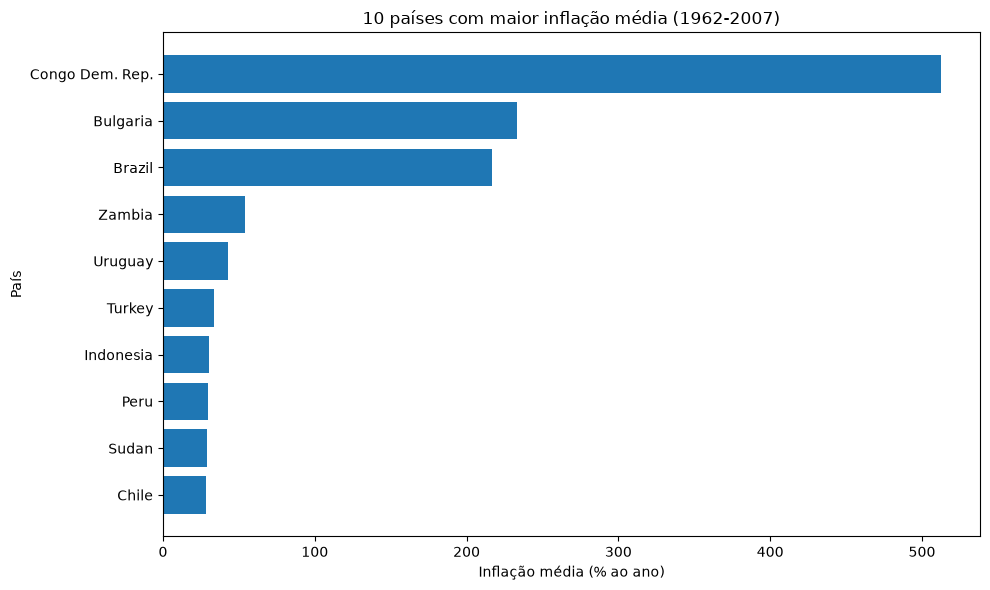

In [100]:
grafico_maiores = maiores.reset_index().sort_values('inflacao')


grafico_barras(
    dados=grafico_maiores,
    x='country',
    y='inflacao',
    titulo='10 países com maior inflação média (1962-2007)',
    xlabel='Inflação média (% ao ano)',
    ylabel='País',
    horizontal=True,
    figsize=(10, 6)
)

            grupo  cresc_pib
0  Maior inflação       1.80
1  Menor inflação       2.48


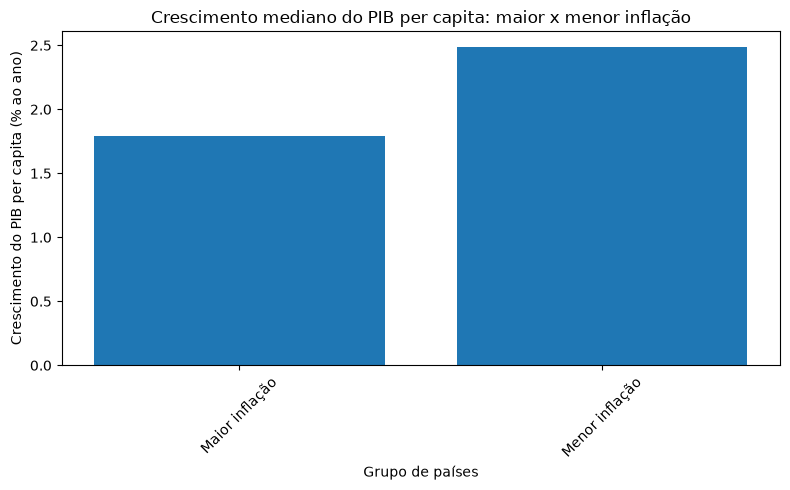

In [101]:
# Identificar o grupo de cada país e os junta
maiores['grupo'] = 'Maior inflação'
menores['grupo'] = 'Menor inflação'

grupos = pd.concat([maiores, menores])

# Calcula a mediana do crescimento do PIB dos grupos
resultado = grupos.groupby('grupo')['cresc_pib'].median().reset_index()
print(resultado.round(2))

# Gráfico 2: compara o crescimento do PIB entre os grupos
grafico_barras(
    dados=resultado,
    x='grupo',
    y='cresc_pib',
    titulo='Crescimento mediano do PIB per capita: maior x menor inflação',
    xlabel='Grupo de países',
    ylabel='Crescimento do PIB per capita (% ao ano)'
)

**Interpretação do grupo:**

Entre os 10 países com maior inflação média, o crescimento mediano do PIB per capita foi de 1,80% ao ano ao longo do periodo analisado (1962 - 2007). Entre os 10 com menor inflação, foi de 2,48%. O grupo de menor inflação apresentou crescimento um pouco maior, mas valores extremos e a quantidade diferente de anos disponíveis também influenciam o resultado, porém com base nos dados disponiveis esse aumento do PIB entre paises com maior e menor inflação estão próximos da faixa visualizada.

#### Análise 2 — Comércio internacional e PIB per capita (Economia – André)
**Pergunta:** Países com maior participação do comércio internacional em suas economias apresentam maior PIB per capita?

**Visualização escolhida:** Gráfico de dispersão entre comércio (% do PIB) e PIB per capita em 2007, com cor por continente. O PIB per capita está em escala logarítmica, porque poucos países têm valores muito altos. Foi usado um único ano (2007) para comparar os países na mesma época.


In [102]:
comercio_df = df_economia.copy()
comercio_df.loc[comercio_df['comercio'] == 0, 'comercio'] = np.nan

# Seleciona os dados de 2007
dados_comercio = comercio_df[comercio_df['year'] == 2007].copy()
dados_comercio = dados_comercio.dropna(subset=['comercio', 'gdpPercap'])

print('Países utilizados:', len(dados_comercio))

correlacao = dados_comercio['comercio'].corr(dados_comercio['gdpPercap'])
print('Correlação entre comércio e PIB per capita:', round(correlacao, 2))

Países utilizados: 125
Correlação entre comércio e PIB per capita: 0.35


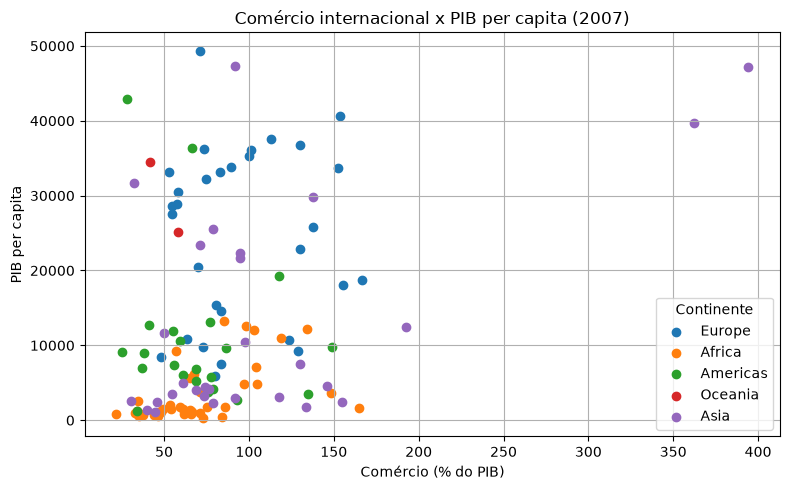

In [103]:
grafico_dispersao(
    dados=dados_comercio,
    x='comercio',
    y='gdpPercap',
    titulo='Comércio internacional x PIB per capita (2007)',
    xlabel='Comércio (% do PIB)',
    ylabel='PIB per capita',
    hue='continent'
)

In [104]:
# Tabela: 10 países com maior PIB per capita no gráfico
tabela_destaques_dispersao(
    dados=dados_comercio,
    x='comercio',
    y='gdpPercap',
    coluna_destaque='gdpPercap',
    titulo='10 países com maior PIB per capita (2007)'
)

10 países com maior PIB per capita (2007)


,country,continent,comercio,gdpPercap
0,Norway,Europe,71.17,49357.19
1,Kuwait,Asia,91.73,47306.99
2,Singapore,Asia,394.29,47143.18
3,United States,Americas,28.01,42951.65
4,Ireland,Europe,153.40,40676.00
5,Hong Kong China,Asia,362.15,39724.98
6,Switzerland,Europe,112.71,37506.42
7,Netherlands,Europe,129.80,36797.93
8,Canada,Americas,66.28,36319.24
9,Iceland,Europe,73.62,36180.79


**Interpretação do grupo:**
Foram analisados 125 países no periodo do ano de 2007. A correlação entre comércio internacional e PIB per capita foi de 0,35, indicando uma relação positiva moderada: países com maior participação do comércio tendem a apresentar PIB per capita mais alto. Porém, há diferenças entre países e continentes, portanto o comércio, sozinho, não explica o nível de renda.

#### Análise 3 — Desemprego, crescimento e nível de renda (Economia – André)
**Pergunta:** Países com maiores taxas de desemprego apresentam menor crescimento do PIB per capita ou diferenças nos níveis de renda entre países?

**Visualização escolhida:** Dois gráficos de dispersão com os dados de 2007: desemprego x crescimento do PIB per capita, e desemprego x PIB per capita (em escala logarítmica). A base de desemprego só tem os anos de 1992, 1997, 2002 e 2007, então conferimos a correlação em cada um deles.


In [105]:
# Selecionar os dados de 2007
dados_desemprego = df_economia[df_economia['year'] == 2007].copy()
dados_desemprego = dados_desemprego.dropna(
    subset=['desemprego', 'cresc_pib', 'gdpPercap']
)

print('Países utilizados:', len(dados_desemprego))

# Calcula as relações entre os indicadores de desemprego, crescimento do PIB e PIB per capita
correlacao_crescimento = dados_desemprego['desemprego'].corr(dados_desemprego['cresc_pib'])
correlacao_renda = dados_desemprego['desemprego'].corr(dados_desemprego['gdpPercap'])

print('Correlação entre desemprego e crescimento do PIB:', round(correlacao_crescimento, 2))
print('Correlação entre desemprego e PIB per capita:', round(correlacao_renda, 2))

Países utilizados: 138
Correlação entre desemprego e crescimento do PIB: 0.04
Correlação entre desemprego e PIB per capita: -0.15


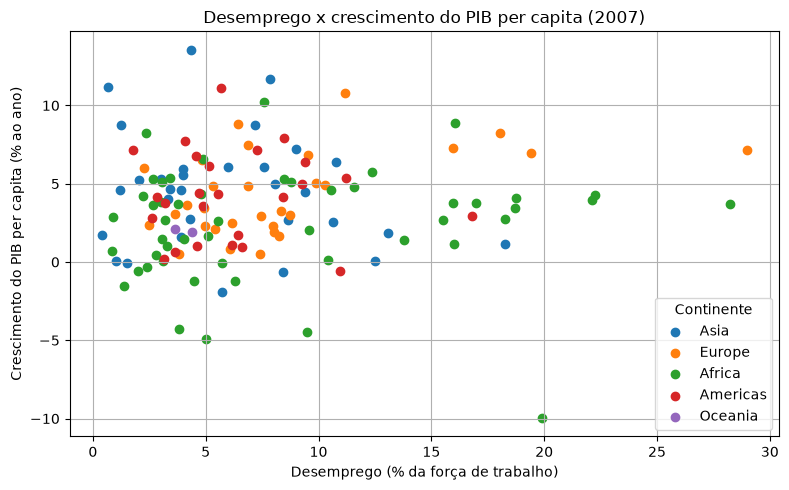

In [106]:
# desemprego e crescimento do PIB per capita
grafico_dispersao(
    dados=dados_desemprego,
    x='desemprego',
    y='cresc_pib',
    titulo='Desemprego x crescimento do PIB per capita (2007)',
    xlabel='Desemprego (% da força de trabalho)',
    ylabel='Crescimento do PIB per capita (% ao ano)',
    hue='continent'
)

In [107]:
# 10 países com maiores taxas de desemprego
tabela_destaques_dispersao(
    dados=dados_desemprego,
    x='desemprego',
    y='cresc_pib',
    coluna_destaque='desemprego',
    titulo='10 países com maior taxa de desemprego (2007)'
)

10 países com maior taxa de desemprego (2007)


,country,continent,desemprego,cresc_pib
0,Bosnia and Herzegovina,Europe,28.98,7.17
1,Swaziland,Africa,28.24,3.72
2,South Africa,Africa,22.26,4.25
3,Namibia,Africa,22.12,3.98
4,Congo Rep.,Africa,19.91,-9.97
5,Montenegro,Europe,19.40,6.99
6,Libya,Africa,18.77,4.07
7,Somalia,Africa,18.69,3.42
8,West Bank and Gaza,Asia,18.28,1.17
9,Gabon,Africa,18.26,2.75


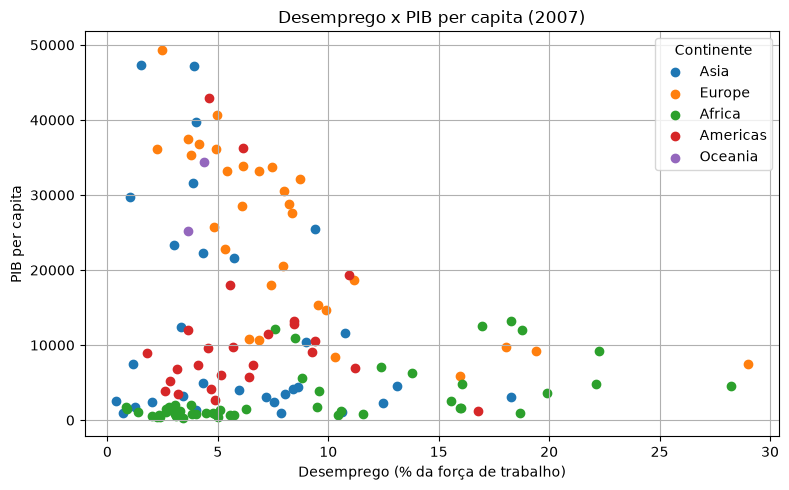

In [108]:
# desemprego e PIB per capita
grafico_dispersao(
    dados=dados_desemprego,
    x='desemprego',
    y='gdpPercap',
    titulo='Desemprego x PIB per capita (2007)',
    xlabel='Desemprego (% da força de trabalho)',
    ylabel='PIB per capita',
    hue='continent'
)

In [109]:
# os mesmos países com maior desemprego e seus níveis de renda
# Assim é possível comparar desemprego e PIB per capita.
tabela_destaques_dispersao(
    dados=dados_desemprego,
    x='desemprego',
    y='gdpPercap',
    coluna_destaque='desemprego',
    titulo='PIB per capita dos 10 países com maior desemprego (2007)'
)

PIB per capita dos 10 países com maior desemprego (2007)


,country,continent,desemprego,gdpPercap
0,Bosnia and Herzegovina,Europe,28.98,7446.30
1,Swaziland,Africa,28.24,4513.48
2,South Africa,Africa,22.26,9269.66
3,Namibia,Africa,22.12,4811.06
4,Congo Rep.,Africa,19.91,3632.56
5,Montenegro,Europe,19.40,9253.90
6,Libya,Africa,18.77,12057.50
7,Somalia,Africa,18.69,926.14
8,West Bank and Gaza,Asia,18.28,3025.35
9,Gabon,Africa,18.26,13206.48


**Interpretação do grupo:**

Foram analisados 138 países em 2007. A correlação entre desemprego e crescimento do PIB per capita foi de 0,04, o que é muito baixo, quase nada. Já entre desemprego e PIB per capita foi de -0,15, uma relação negativa fraca. Assim, os dados não mostram uma associação linear relevante entre desemprego e crescimento, nem uma relação forte com o nível de renda.

#### Análise 4 — Diferença de expectativa de vida entre mulheres e homens e PIB per capita (Economia – André)
**Pergunta:** A diferença de expectativa de vida entre homens e mulheres aumenta ou diminui conforme o PIB per capita cresce?

**Visualização escolhida:** Um gráfico de dispersão compara o PIB per capita médio com a diferença média de expectativa de vida de cada país. Também mostramos a evolução média da expectativa de vida feminina e masculina nos anos disponíveis. Foram considerados apenas os anos em que Gapminder e os dois indicadores do Banco Mundial possuem dados, mantendo países com informações em todos esses anos para a comparação principal.

In [110]:
dados_vida = df_economia.dropna(subset=['gdpPercap', 'vida_f', 'vida_m']).copy()
dados_vida = dados_vida[dados_vida['gdpPercap'] > 0]

# Diferença positiva significa que a expectativa de vida feminina é maior.
dados_vida['dif_vida'] = dados_vida['vida_f'] - dados_vida['vida_m']

anos_disponiveis = sorted(dados_vida['year'].unique())
print('Anos utilizados na análise:', anos_disponiveis)
print('Total de anos:', len(anos_disponiveis))
print('Quantidade de países com dados em cada ano:')
display(
    dados_vida.groupby('year')['country']
    .nunique()
    .reset_index(name='quantidade_paises')
)

# Calcula a média dos indicadores para cada país ao longo dos anos disponíveis.
resumo_vida = (
    dados_vida.groupby(['country', 'continent'])
    .agg(
        pib_medio=('gdpPercap', 'mean'),
        vida_f_media=('vida_f', 'mean'),
        vida_m_media=('vida_m', 'mean'),
        dif_vida_media=('dif_vida', 'mean'),
        anos_analisados=('year', 'nunique')
    )
    .reset_index()
)

resumo_vida = resumo_vida[
    resumo_vida['anos_analisados'] == len(anos_disponiveis)
].copy()

correlacao = resumo_vida['pib_medio'].corr(
    resumo_vida['dif_vida_media'],
    method='spearman'
)

print('Países com dados completos em todos os anos:', resumo_vida['country'].nunique())
print('Correlação de Spearman:', round(correlacao, 2))


Anos utilizados na análise: [np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Total de anos: 10
Quantidade de países com dados em cada ano:


,year,quantidade_paises
0,1962,139
1,1967,139
2,1972,139
3,1977,139
4,1982,139
5,1987,139
6,1992,140
7,1997,140
8,2002,140
9,2007,140


Países com dados completos em todos os anos: 139
Correlação de Spearman: 0.59


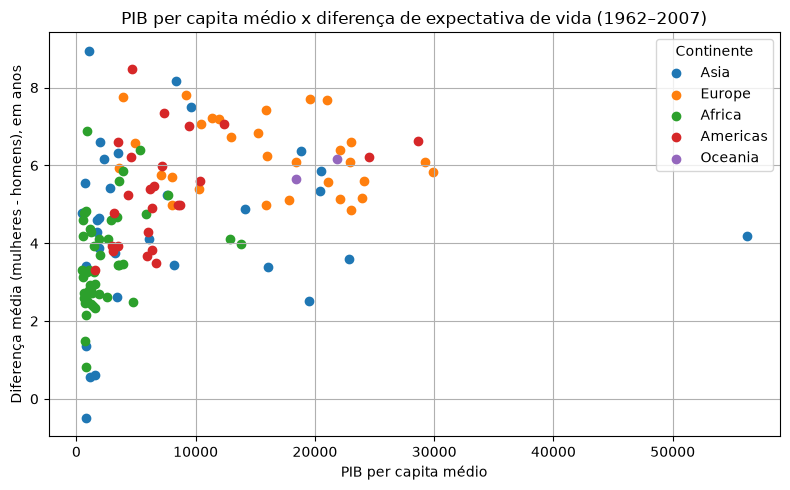

In [111]:
# Gráfico: PIB per capita médio x diferença média de expectativa de vida
# Cada ponto representa um país; as cores identificam os continentes.
grafico_dispersao(
    dados=resumo_vida,
    x='pib_medio',
    y='dif_vida_media',
    titulo='PIB per capita médio x diferença de expectativa de vida (1962–2007)',
    xlabel='PIB per capita médio',
    ylabel='Diferença média (mulheres - homens), em anos',
    hue='continent',
)




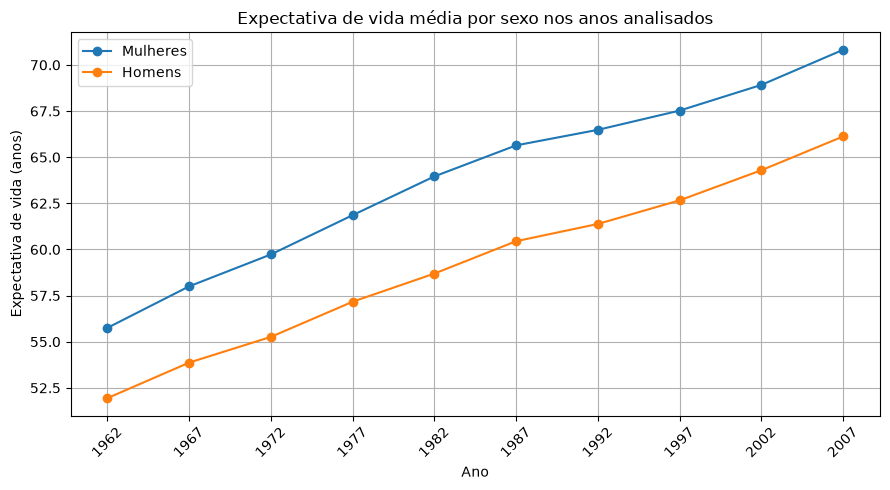

Diferença média entre mulheres e homens por ano:


,year,dif_vida
0,1962,3.81
1,1967,4.13
2,1972,4.47
3,1977,4.69
4,1982,5.26
5,1987,5.19
6,1992,5.10
7,1997,4.86
8,2002,4.62
9,2007,4.70


In [112]:
# Compara a expectativa de vida média de mulheres e homens em cada ano disponível.
vida_por_ano = (
    dados_vida.groupby('year')[['vida_f', 'vida_m', 'dif_vida']]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))
plt.plot(vida_por_ano['year'], vida_por_ano['vida_f'], marker='o', label='Mulheres')
plt.plot(vida_por_ano['year'], vida_por_ano['vida_m'], marker='o', label='Homens')
plt.title('Expectativa de vida média por sexo nos anos analisados')
plt.xlabel('Ano')
plt.ylabel('Expectativa de vida (anos)')
plt.xticks(vida_por_ano['year'], rotation=45)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

print('Diferença média entre mulheres e homens por ano:')
display(vida_por_ano[['year', 'dif_vida']].round(2))


In [113]:
print('Diferença média de expectativa de vida (mulheres − homens), em anos')
tabela_destaques_dispersao(
    dados=resumo_vida,
    x='pib_medio',
    y='dif_vida_media',
    coluna_destaque='dif_vida_media',
    titulo='10 países com maior diferença média de expectativa de vida (período analisado)'
)


Diferença média de expectativa de vida (mulheres − homens), em anos
10 países com maior diferença média de expectativa de vida (período analisado)


,country,continent,pib_medio,dif_vida_media
0,Vietnam,Asia,1093.12,8.95
1,El Salvador,Americas,4671.23,8.47
2,Iraq,Asia,8338.26,8.18
3,Poland,Europe,9223.51,7.81
4,Bosnia and Herzegovina,Europe,3948.98,7.77
5,Finland,Europe,19571.47,7.72
6,France,Europe,21031.02,7.69
7,Korea Rep.,Asia,9608.96,7.50
8,Slovenia,Europe,15881.77,7.42
9,Uruguay,Americas,7333.41,7.34


**Interpretação do grupo:**

Foram analisados 139 países com dados completos nos 10 anos disponíveis (1962 a 2007) e comparado com a fonte do World Bank (Banco Mundial). A correlação de Spearman foi de 0,59, indicando uma associação positiva moderada: países com maior PIB per capita médio tendem a apresentar uma diferença maior de expectativa de vida a favor das mulheres. A relação é uma associação e pode ser um dos indicadores que demonstra que o aumento do PIB cause essa diferença.

### Análises — Saúde (Leandro)

Aqui respondo as cinco perguntas da minha parte, reaproveitando as funções de gráfico da seção 3.
Começo com uma visão geral da correlação entre os indicadores e, em seguida, faço uma análise para
cada pergunta.

In [114]:
# Função auxiliar: correlação entre duas colunas DENTRO de cada faixa de PIB
def correlacao_por_faixa(dados, coluna_x, coluna_y):
    linhas = []
    for faixa in ['1. PIB Baixo', '2. PIB Médio', '3. PIB Alto']:
        grupo = dados[dados['faixa_pib'] == faixa]
        corr = grupo[coluna_x].corr(grupo[coluna_y])
        qtd = grupo[[coluna_x, coluna_y]].dropna().shape[0]
        linhas.append({'faixa_pib': faixa, 'correlacao': round(corr, 2), 'qtd_paises': qtd})
    return pd.DataFrame(linhas)

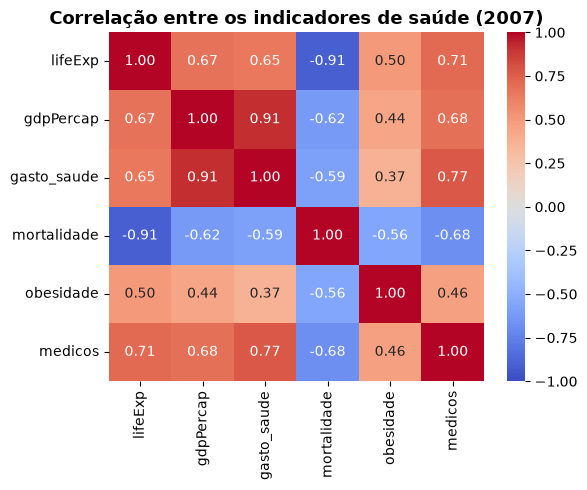

In [115]:
# Visão geral: correlação entre todos os indicadores de saúde + vida e PIB (2007)
grafico_correlacao(
    dados_saude,
    ['lifeExp', 'gdpPercap', 'gasto_saude', 'mortalidade', 'obesidade', 'medicos'],
    titulo='Correlação entre os indicadores de saúde (2007)'
)

#### Análise 5 — Gasto em saúde e expectativa de vida (Saúde – Leandro)
**Pergunta:** Países que gastam mais em saúde por pessoa vivem mais, **mesmo quando têm PIB per capita parecido**?

**Visualização escolhida:** Gráfico de dispersão entre gasto em saúde e expectativa de vida (cor por continente), em 2007, e um gráfico de barras com a correlação dentro de cada faixa de PIB. Separei os países em 3 faixas de PIB justamente para comparar países de riqueza parecida e ver se a relação se mantém.

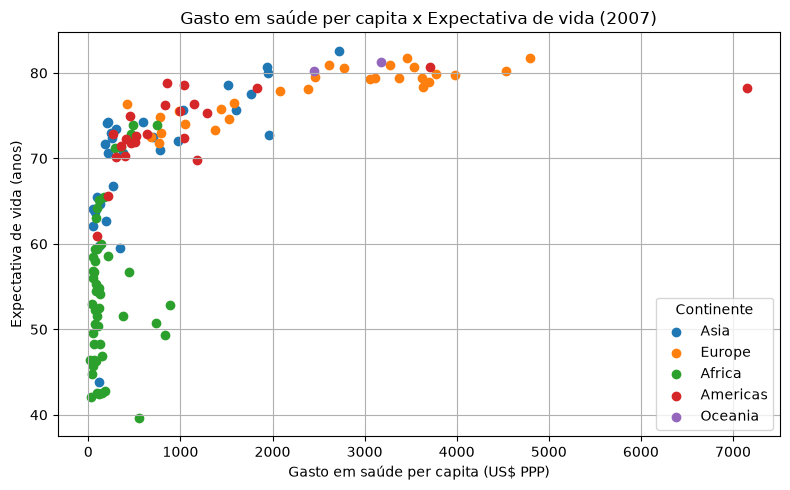

Correlação geral: 0.63


In [116]:
grafico_dispersao(
    dados_saude, x='gasto_saude', y='lifeExp',
    titulo='Gasto em saúde per capita x Expectativa de vida (2007)',
    xlabel='Gasto em saúde per capita (US$ PPP)', ylabel='Expectativa de vida (anos)',
    hue='continent'
)
print('Correlação geral:', dados_saude['gasto_saude'].corr(dados_saude['lifeExp']).round(2))

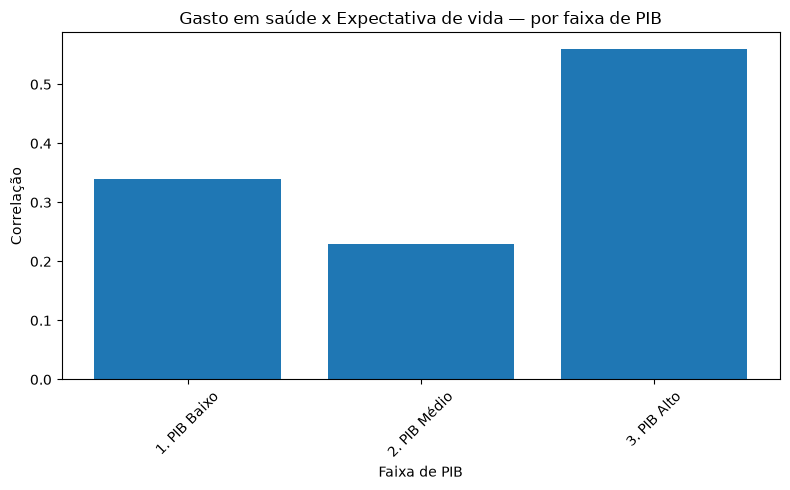

,faixa_pib,correlacao,qtd_paises
0,1. PIB Baixo,0.34,44
1,2. PIB Médio,0.23,44
2,3. PIB Alto,0.56,45


In [117]:
corr_p1 = correlacao_por_faixa(dados_saude, 'gasto_saude', 'lifeExp')
grafico_barras(
    corr_p1, x='faixa_pib', y='correlacao',
    titulo='Gasto em saúde x Expectativa de vida — por faixa de PIB',
    xlabel='Faixa de PIB', ylabel='Correlação'
)
corr_p1

**Interpretação do grupo:**

Foram analisados 133 países em 2007. A correlação geral entre gasto em saúde e expectativa de vida foi de **0,63**, uma relação positiva e moderada a forte: no geral, países que gastam mais em saúde por pessoa tendem a viver mais. Quando separo por faixa de PIB, a correlação continua positiva nas três faixas (**0,34** no PIB baixo, **0,23** no médio e **0,56** no alto), então o maior gasto em saúde está ligado a mais anos de vida **mesmo entre países de renda parecida**. A limitação é que parte desse efeito acompanha a própria riqueza do país, então não dá para dizer que é só o gasto em saúde que causa o aumento.

#### Análise 6 — Mortalidade infantil e expectativa de vida (Saúde – Leandro)
**Pergunta:** A **mortalidade infantil** explica melhor as diferenças de expectativa de vida entre os países **do que o PIB per capita**?

**Visualização escolhida:** Gráfico de dispersão entre mortalidade infantil e expectativa de vida (cor por continente) e um gráfico de barras comparando a força (valor absoluto) da correlação de cada fator com a expectativa de vida. Usei 2007 para comparar todos os países na mesma época.

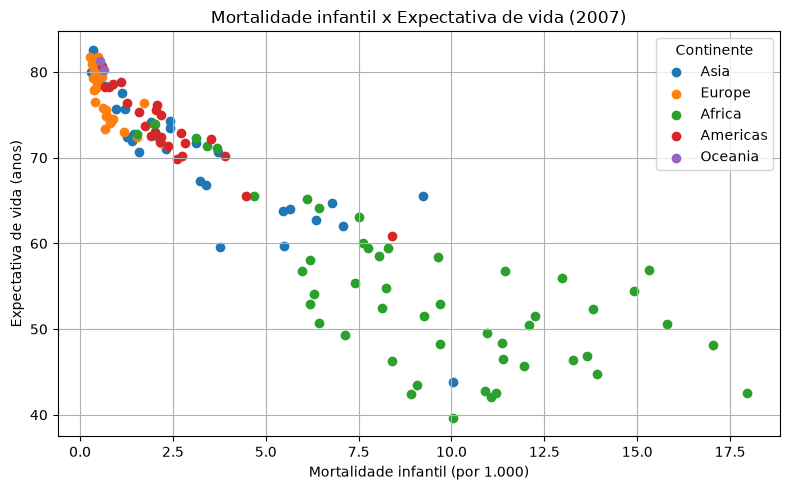

In [118]:
grafico_dispersao(
    dados_saude, x='mortalidade', y='lifeExp',
    titulo='Mortalidade infantil x Expectativa de vida (2007)',
    xlabel='Mortalidade infantil (por 1.000)', ylabel='Expectativa de vida (anos)',
    hue='continent'
)

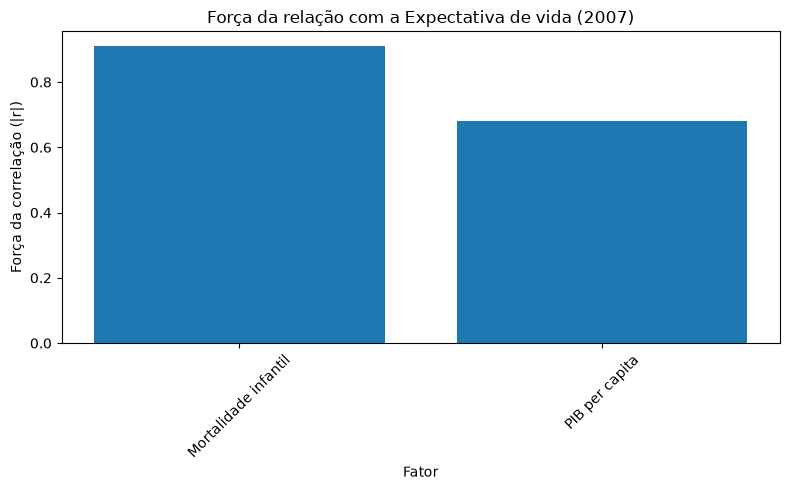

Correlação mortalidade x vida: -0.91
Correlação PIB x vida: 0.68


In [119]:
corr_mort = dados_saude['mortalidade'].corr(dados_saude['lifeExp'])
corr_pib  = dados_saude['gdpPercap'].corr(dados_saude['lifeExp'])
comparacao = pd.DataFrame({
    'fator': ['Mortalidade infantil', 'PIB per capita'],
    'forca_correlacao': [round(abs(corr_mort), 2), round(abs(corr_pib), 2)]
})
grafico_barras(
    comparacao, x='fator', y='forca_correlacao',
    titulo='Força da relação com a Expectativa de vida (2007)',
    xlabel='Fator', ylabel='Força da correlação (|r|)'
)
print('Correlação mortalidade x vida:', round(corr_mort, 2))
print('Correlação PIB x vida:', round(corr_pib, 2))

**Interpretação do grupo:**

Foram analisados 139 países em 2007. A correlação entre mortalidade infantil e expectativa de vida foi de **−0,91** (negativa e muito forte), bem mais forte em módulo que a do PIB per capita, que foi de **0,68**. Então a mortalidade infantil **explica melhor** as diferenças de expectativa de vida entre os países do que o PIB. Isso faz sentido, porque a expectativa de vida ao nascer é muito puxada para baixo quando morrem muitas crianças. Vale lembrar que os dois fatores também estão ligados entre si (países mais ricos costumam ter menos mortes infantis).

#### Análise 7 — PIB per capita e obesidade (Saúde – Leandro)
**Pergunta:** A **taxa de obesidade** cresce junto com o **PIB per capita**?

**Visualização escolhida:** Gráfico de dispersão entre PIB per capita e obesidade (cor por continente), em 2007. A dispersão ajuda a ver se os dois sobem juntos e se há países fora do padrão.

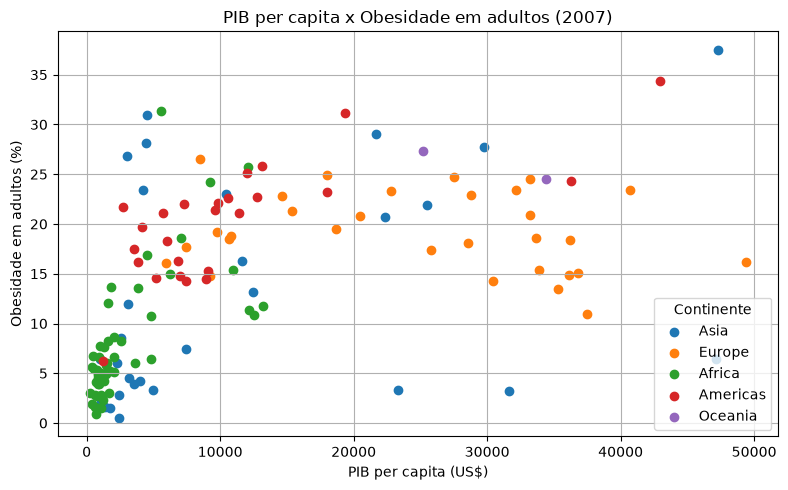

Correlação: 0.53


In [120]:
grafico_dispersao(
    dados_saude, x='gdpPercap', y='obesidade',
    titulo='PIB per capita x Obesidade em adultos (2007)',
    xlabel='PIB per capita (US$)', ylabel='Obesidade em adultos (%)',
    hue='continent'
)
print('Correlação:', dados_saude['gdpPercap'].corr(dados_saude['obesidade']).round(2))

**Interpretação do grupo:**

Foram analisados 139 países em 2007. A correlação entre PIB per capita e obesidade foi de **0,53**, uma relação positiva moderada: em média, países mais ricos têm mais obesidade. Mas a relação não é tão forte, e o gráfico mostra bastante dispersão — tem país rico com obesidade baixa (como alguns da Ásia) e país de renda média com obesidade alta. Então o PIB ajuda a explicar em parte, mas hábitos alimentares e cultura também pesam bastante.

#### Análise 8 — Médicos e expectativa de vida (Saúde – Leandro)
**Pergunta:** Países com **mais médicos por mil habitantes** têm maior expectativa de vida, **mesmo descontando o efeito do PIB per capita**?

**Visualização escolhida:** Gráfico de dispersão entre médicos e expectativa de vida (cor por continente) e um gráfico de barras com a correlação dentro de cada faixa de PIB — do mesmo jeito da Análise 5, para "descontar" o efeito da riqueza.

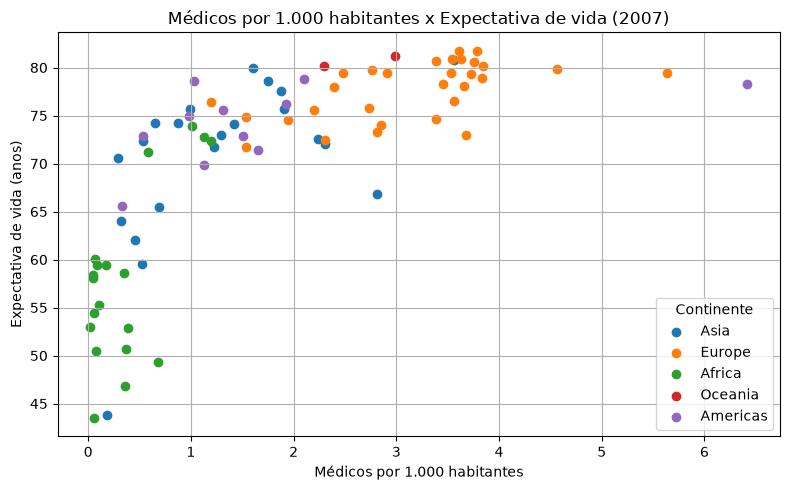

Correlação geral: 0.72


In [121]:
grafico_dispersao(
    dados_saude, x='medicos', y='lifeExp',
    titulo='Médicos por 1.000 habitantes x Expectativa de vida (2007)',
    xlabel='Médicos por 1.000 habitantes', ylabel='Expectativa de vida (anos)',
    hue='continent'
)
print('Correlação geral:', dados_saude['medicos'].corr(dados_saude['lifeExp']).round(2))

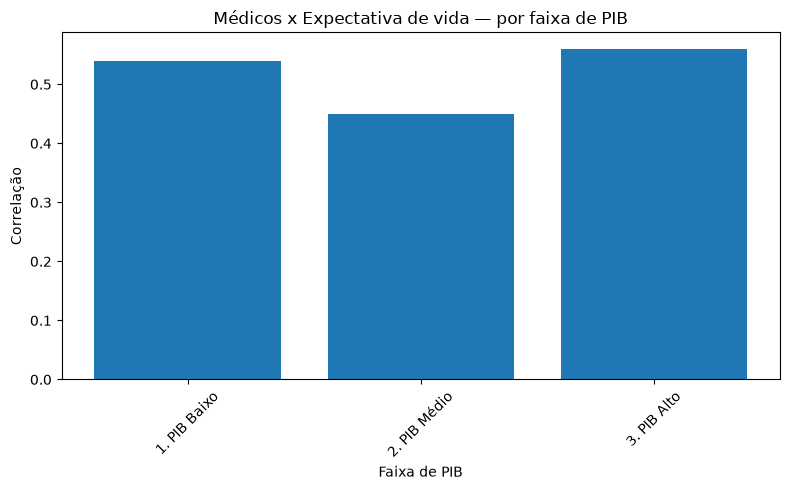

,faixa_pib,correlacao,qtd_paises
0,1. PIB Baixo,0.54,15
1,2. PIB Médio,0.45,32
2,3. PIB Alto,0.56,36


In [122]:
corr_p4 = correlacao_por_faixa(dados_saude, 'medicos', 'lifeExp')
grafico_barras(
    corr_p4, x='faixa_pib', y='correlacao',
    titulo='Médicos x Expectativa de vida — por faixa de PIB',
    xlabel='Faixa de PIB', ylabel='Correlação'
)
corr_p4

**Interpretação do grupo:**

Foram analisados 83 países em 2007 (esse indicador de médicos tem menos países com dados nesse ano, então essa análise é mais limitada que as outras). A correlação geral entre médicos e expectativa de vida foi de **0,72** (forte) e, dentro de cada faixa de PIB, continua positiva (**0,54** no PIB baixo, **0,45** no médio e **0,56** no alto). Ou seja, ter mais médicos está ligado a uma expectativa de vida maior **mesmo entre países de renda parecida**.

#### Análise 9 — Gasto em saúde e mortalidade infantil (Saúde – Leandro)
**Pergunta:** Países que gastam mais em saúde por pessoa têm **menor mortalidade infantil**?

**Visualização escolhida:** Gráfico de dispersão entre gasto em saúde per capita e mortalidade infantil (cor por continente), em 2007. A dispersão ajuda a ver se, quanto mais um país gasta, menor é a mortalidade — e quais países fogem do padrão.

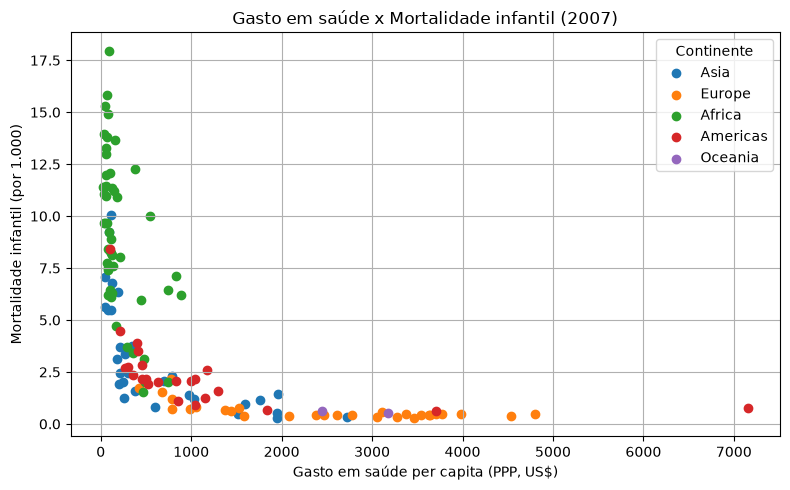

In [123]:
grafico_dispersao(
    dados_saude, x='gasto_saude', y='mortalidade',
    titulo='Gasto em saúde x Mortalidade infantil (2007)',
    xlabel='Gasto em saúde per capita (PPP, US$)', ylabel='Mortalidade infantil (por 1.000)',
    hue='continent'
)

In [124]:
corr_p5 = dados_saude['gasto_saude'].corr(dados_saude['mortalidade'])
qtd_p5 = dados_saude[['gasto_saude', 'mortalidade']].dropna().shape[0]
print('Correlação gasto em saúde x mortalidade infantil:', round(corr_p5, 2))
print('Países analisados:', qtd_p5)

Correlação gasto em saúde x mortalidade infantil: -0.59
Países analisados: 133


**Interpretação do grupo:**

Foram analisados 133 países em 2007. A correlação entre gasto em saúde per capita e mortalidade infantil foi de **−0,59** (negativa e moderada a forte): em geral, quanto mais um país gasta em saúde por pessoa, menor é a mortalidade infantil**. Isso faz sentido, porque mais recursos costumam significar mais acesso a pré-natal, vacinas e atendimento ao recém-nascido. A relação não é perfeita — há países que gastam parecido mas têm mortalidades diferentes —, o que mostra que não basta gastar, também importa como o dinheiro é usado. Mesmo assim, o investimento em saúde aparece como um fator importante para reduzir a morte de crianças.

No geral, os indicadores de saúde estão bem ligados à expectativa de vida. A mortalidade infantil
foi o fator mais forte, e tanto o gasto em saúde quanto o número de médicos continuam
importando mesmo quando comparo países de PIB parecido* ou seja, a riqueza ajuda, mas não explica
tudo sozinha. A obesidade foi a única que sobe junto com a riqueza (e mesmo assim de forma só
moderada).

#### Análise 10 — Turismo × violência (Turismo - Thiago)
**Pergunta:** Existe alguma correlação entre turismo e segurança

Os dados utilizados foram dos anos de 2023 → 2024

Os anos de 2020 e 2021 foram separados devido a pandemia que sera analisada como caso a parte.

Isso não elimina todos os fatores de confusão nem garante ausência
de efeitos posteriores da pandemia.

**Pergunta 1** — A queda dos homicídios acompanhou o aumento das viagens?

A tabela cruza o sentido das duas mudanças em cada UF.

viagens_mov  caiu  subiu  Total
taxa_mov                       
caiu           10     15     25
subiu           0      2      2
Total          10     17     27


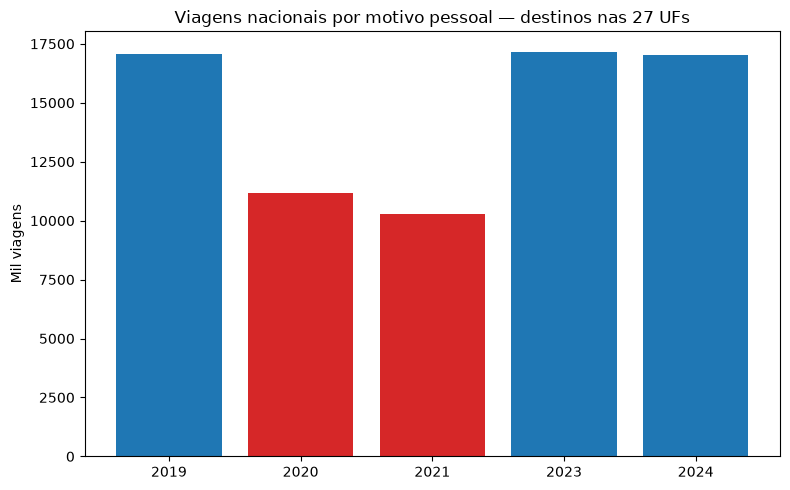

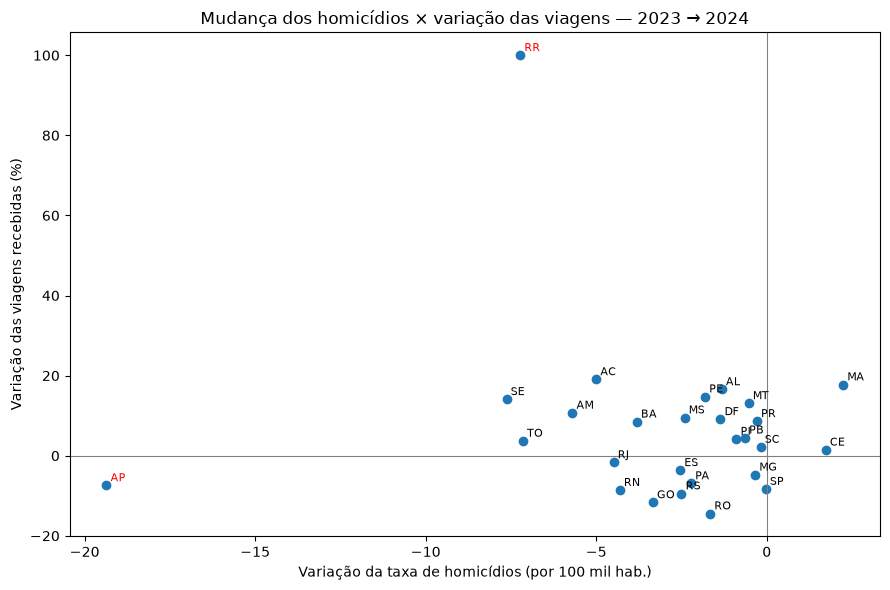

In [125]:
contingencia_principal_seguranca = tabela_contingencia(var_principal_seguranca)
print(contingencia_principal_seguranca)

fig_total = grafico_total_por_ano(
    base_seguranca,
    "viagens_mil",
    destaque=ANOS_PANDEMIA,
    titulo="Viagens nacionais por motivo pessoal — destinos nas 27 UFs",
    rotulo_y="Mil viagens",
)
plt.show()
plt.close(fig_total)

fig_disp = util.grafico_dispersao(
    var_principal_seguranca,
    "Mudança dos homicídios × variação das viagens — 2023 → 2024",
    destacar=("RR", "AP"),
)
plt.show()
plt.close(fig_disp)






**Gráficos gerados:**


- A taxa de homicídios caiu em 25 UFs.
- Nessas UFs, as viagens aumentaram em 15 e diminuíram em 10.
- Nas duas UFs com aumento da taxa, as viagens também aumentaram.

Portanto, a queda da violência não foi acompanhada de aumento das viagens em todas as UFs.

A correlação de Pearson com todas as UFs foi aproximadamente -0,109 e a de Spearman, -0,037: valores próximos de zero nessa comparação.

Nos cenários selecionados, Pearson mudou de sinal e permaneceu próximo de zero. Isso não prova a correlação mas não comprova ausência de influência da violência nas decisões individuais de viagem.

Comparação 2019 → 2024

Pearson foi aproximadamente 0,238 com todas as UFs, diferente do sinal observado na comparação principal.

O resultado descreve essa comparação específica. O intervalo inclui pandemia, recuperação e diferenças metodológicas, impedindo atribuir as mudanças exclusivamente à violência.

In [126]:

contingencia_principal_seguranca = tabela_contingencia(var_principal_seguranca)
print(contingencia_principal_seguranca)




viagens_mov  caiu  subiu  Total
taxa_mov                       
caiu           10     15     25
subiu           0      2      2
Total          10     17     27


#### Analisando o resultado de cima pode-se afirmar que:

- Em 10, as viagens também caíram.
- Em 15, as viagens subiram.

Portanto, **redução de homicídios** não foi acompanhada de aumento das viagens em todas as UFs.

#### Nas 2 UFs onde a taxa de homicídios subiu:

- Em nenhuma, as viagens caíram.
- Nas 2, as viagens subiram.

#### Independentemente do movimento dos homicídios:

- As viagens caíram em 10 UFs.
- As viagens subiram em 17 UFs.
- Foram analisadas 27 UFs.

**Detalhamento 2** — As variações apresentam associação?

Foi calculado os resultados exploratórios com as funções existentes.

Os cenários sem RR e AP avaliam sensibilidade; não representam uma
justificativa para excluir essas UFs do resultado principal.

In [127]:
robustez_seguranca = teste_robustez(var_principal_seguranca, CENARIOS)
print(robustez_seguranca)

               cenario   n  pearson  spearman  inclinacao_pct  r_critico_5pct
0         Todas as UFs  27   -0.109    -0.037          -0.555           0.359
1          Sem Roraima  26    0.150     0.061           0.362           0.365
2  Sem Roraima e Amapá  25   -0.041    -0.009          -0.166           0.371


Ao o que tudo indica as correlações estão bem abaixa de 1 o que indica que não há quase nenhuma correlação.
Não significa que a violência não influencia no turismo mas que o resultado é baixo demais para se quer responder.

**Detalhamento 3** —  O que muda na comparação 2019 → 2024?

Esta comparação é complementar, não uma confirmação independente.

Ela envolve o período da pandemia e diferenças na apresentação metodológica da fonte de viagens.

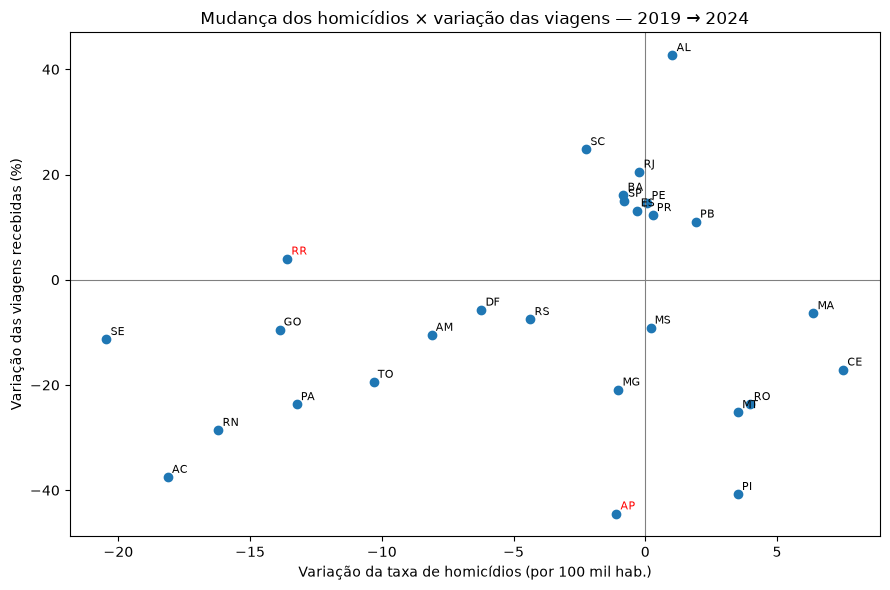

viagens_mov  caiu  subiu  Total
taxa_mov                       
caiu           11      6     17
subiu           6      4     10
Total          17     10     27
               cenario   n  pearson  spearman  inclinacao_pct  r_critico_5pct
0         Todas as UFs  27    0.238     0.180           0.667           0.359
1          Sem Roraima  26    0.271     0.195           0.785           0.365
2  Sem Roraima e Amapá  25    0.314     0.175           0.851           0.371


In [128]:
fig_longo = util.grafico_dispersao(
    var_longo_seguranca,
    "Mudança dos homicídios × variação das viagens — 2019 → 2024",
    destacar=("RR", "AP"),
)
plt.show()
plt.close(fig_longo)


contingencia_longa_seguranca = tabela_contingencia(var_longo_seguranca)
robustez_longa_seguranca = teste_robustez(var_longo_seguranca, CENARIOS)

print(contingencia_longa_seguranca)
print(robustez_longa_seguranca)

Na comparação entre 2019 e 2024, das 17 UFs em que a taxa de homicídios caiu, 11 tiveram queda nas viagens e seis tiveram aumento. Nas dez UFs em que os homicídios subiram, seis tiveram queda nas viagens e quatro tiveram aumento.

As correlações foram positivas e fracas(abaixo de 1.0), mesmo após excluir Roraima e Amapá por serem dados com extaploração alta. Portanto, não foi observada uma associação consistente entre redução dos homicídios e aumento das viagens.

Isso não prova que a violência não influencie as viagens devido a baixa correlação, baixa quantidade e dados e também os dados vindos da tabela de turismo não filtra viagens exclusivamente por entretenimento/cultura e culinária(características de viagem de turismo ).

**Detalhamento 4** —  Impactos da pandemia.

Esta comparação é complementar, não uma confirmação independente.

Ela envolve o período da pandemia e diferenças na apresentação metodológica da fonte de viagens.

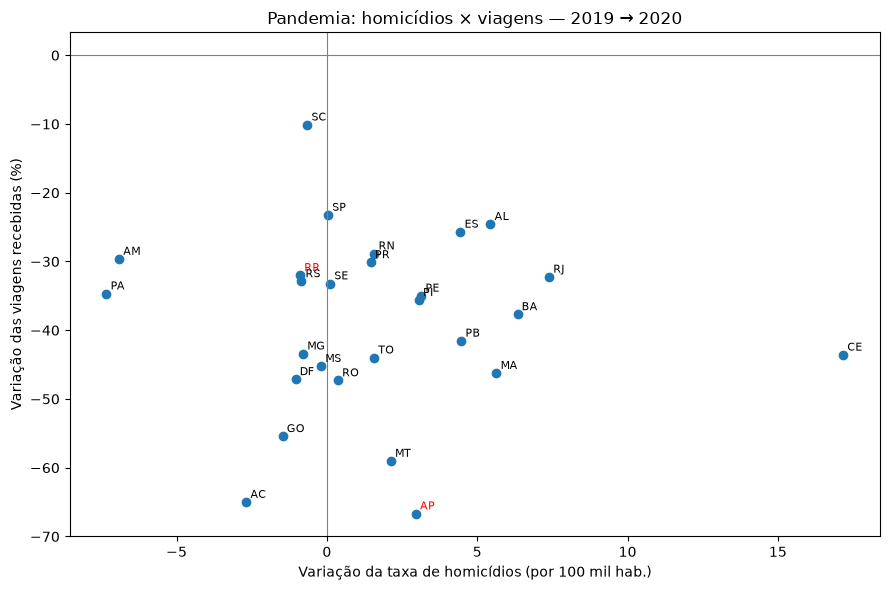

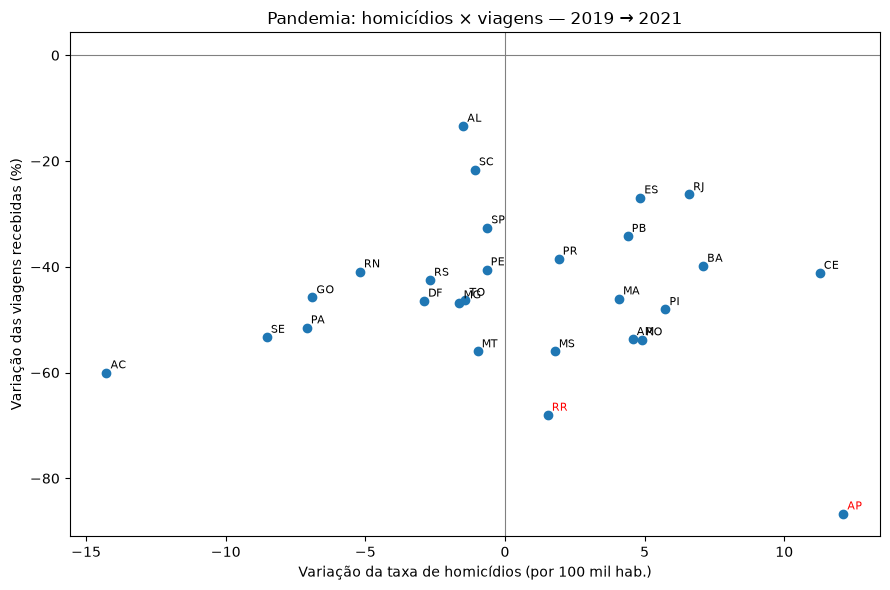

In [129]:
for ano, comparacao in comparacoes_pandemia_seguranca.items():
    fig_pandemia = util.grafico_dispersao(
        comparacao,
        f"Pandemia: homicídios × viagens — 2019 → {ano}",
        destacar=("RR", "AP"),
    )
   
    plt.show()
    plt.close(fig_pandemia)

In [130]:
resumo_pandemia_seguranca = []

for ano, comparacao in comparacoes_pandemia_seguranca.items():
    queda_viagens = comparacao["viagens_mov"].eq("caiu")
    queda_taxa = comparacao["taxa_mov"].eq("caiu")
    quedas_simultaneas = comparacao.loc[queda_viagens & queda_taxa]

    resumo_pandemia_seguranca.append({
        "ano": ano,
        "ufs_com_queda_viagens": int(queda_viagens.sum()),
        "ufs_com_queda_taxa": int(queda_taxa.sum()),
        "ufs_com_ambas_as_quedas": len(quedas_simultaneas),
    })

    print(f"\n{ano}:")
    print(f"Viagens caíram em {int(queda_viagens.sum())} de 27 UFs.")
    print(
        "UFs com queda simultânea da taxa e das viagens:",
        quedas_simultaneas["uf"].tolist(),
    )

resumo_pandemia_seguranca = pd.DataFrame(resumo_pandemia_seguranca)
print("\nResumo:")
print(resumo_pandemia_seguranca)


2020:
Viagens caíram em 27 de 27 UFs.
UFs com queda simultânea da taxa e das viagens: ['AC', 'AM', 'RR', 'PA', 'MG', 'SC', 'RS', 'MS', 'GO', 'DF']

2021:
Viagens caíram em 27 de 27 UFs.
UFs com queda simultânea da taxa e das viagens: ['AC', 'PA', 'TO', 'RN', 'PE', 'AL', 'SE', 'MG', 'SP', 'SC', 'RS', 'MT', 'GO', 'DF']

Resumo:
    ano  ufs_com_queda_viagens  ufs_com_queda_taxa  ufs_com_ambas_as_quedas
0  2020                     27                  10                       10
1  2021                     27                  14                       14



A pandemia não influênciou todos os estados de forma simultânea porém no auge dela(2021), uma parcela grande dos estados sofreram uma queda.


In [131]:
menores_estimativas_seguranca = (
    base_seguranca.loc[base_seguranca["ano"].isin(ANOS_PANDEMIA)]
    .nsmallest(6, "viagens_mil")
    [["ano", "uf", "viagens_mil"]]
)
print(menores_estimativas_seguranca)


     ano  uf  viagens_mil
59  2021  AP          6.0
57  2021  RR          8.0
28  2020  AC         14.0
32  2020  AP         15.0
55  2021  AC         16.0
30  2020  RR         17.0


#### Análise 11 — Variação do volume de viagens nacionais conforme evolução do PIB per capita. (Turismo - Thiago)
**Pergunta:** Variação do volume de viagens nacionais conforme evolução do PIB per capita

#### Detalhamento 1. Viagens × PIB per capita - O aumento do PIB per capita foi acompanhado de aumento das viagens?
Comparação principal: **2019 → 2023** (antes e depois da pandemia).
Cautela: em 2019, a fonte usa só o 3º trimestre; a partir de 2020, usa o acumulado de segundas visitas.



As menores estimativas na pandemia ocorreram em Amapá, Roraima e Acre, entre 6 mil e 17 mil viagens. 

Esses valores, isoladamente, não demonstram influência da violência.

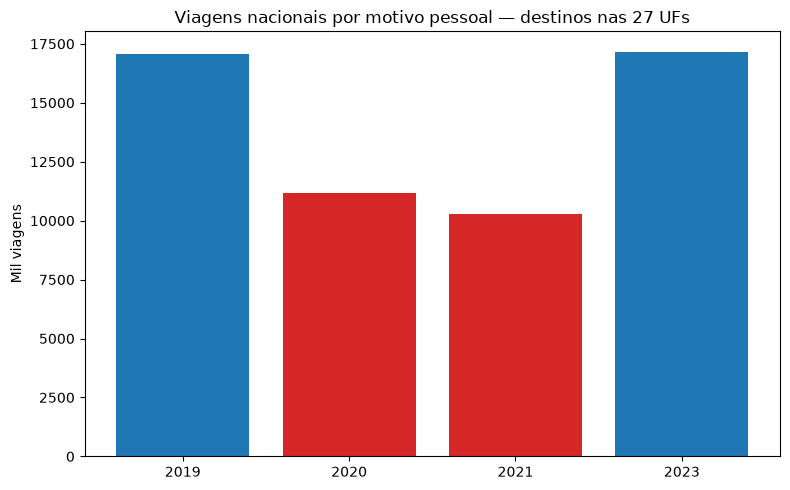

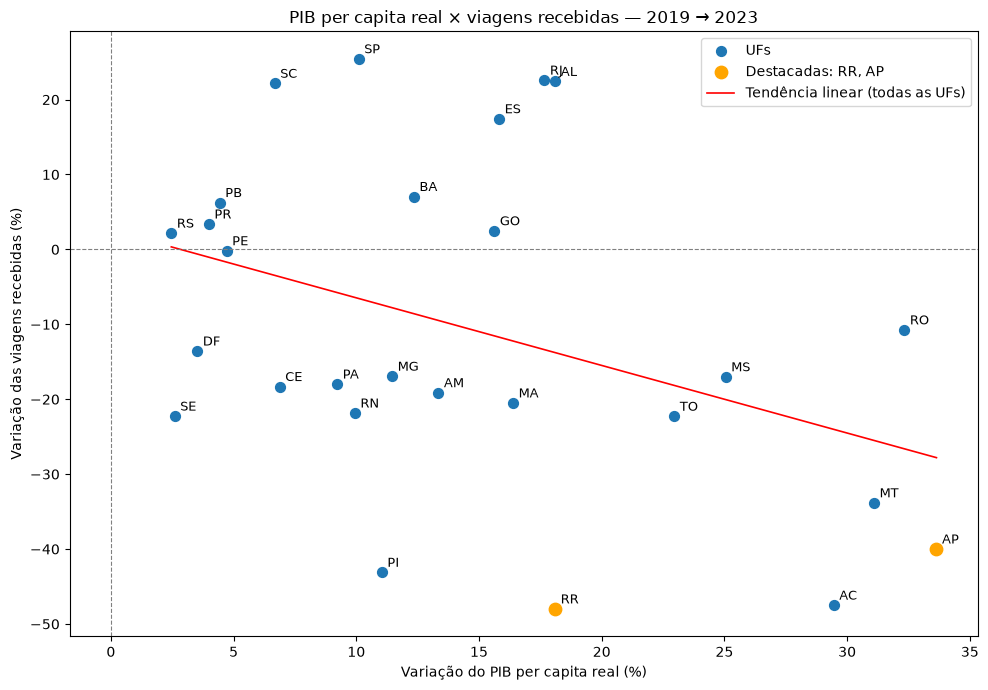

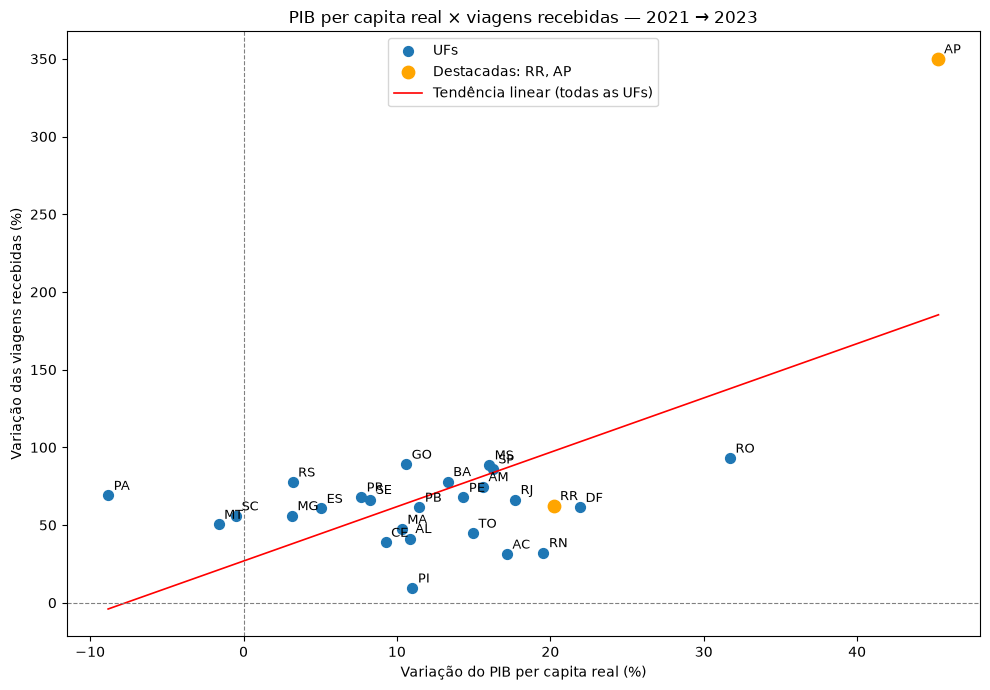

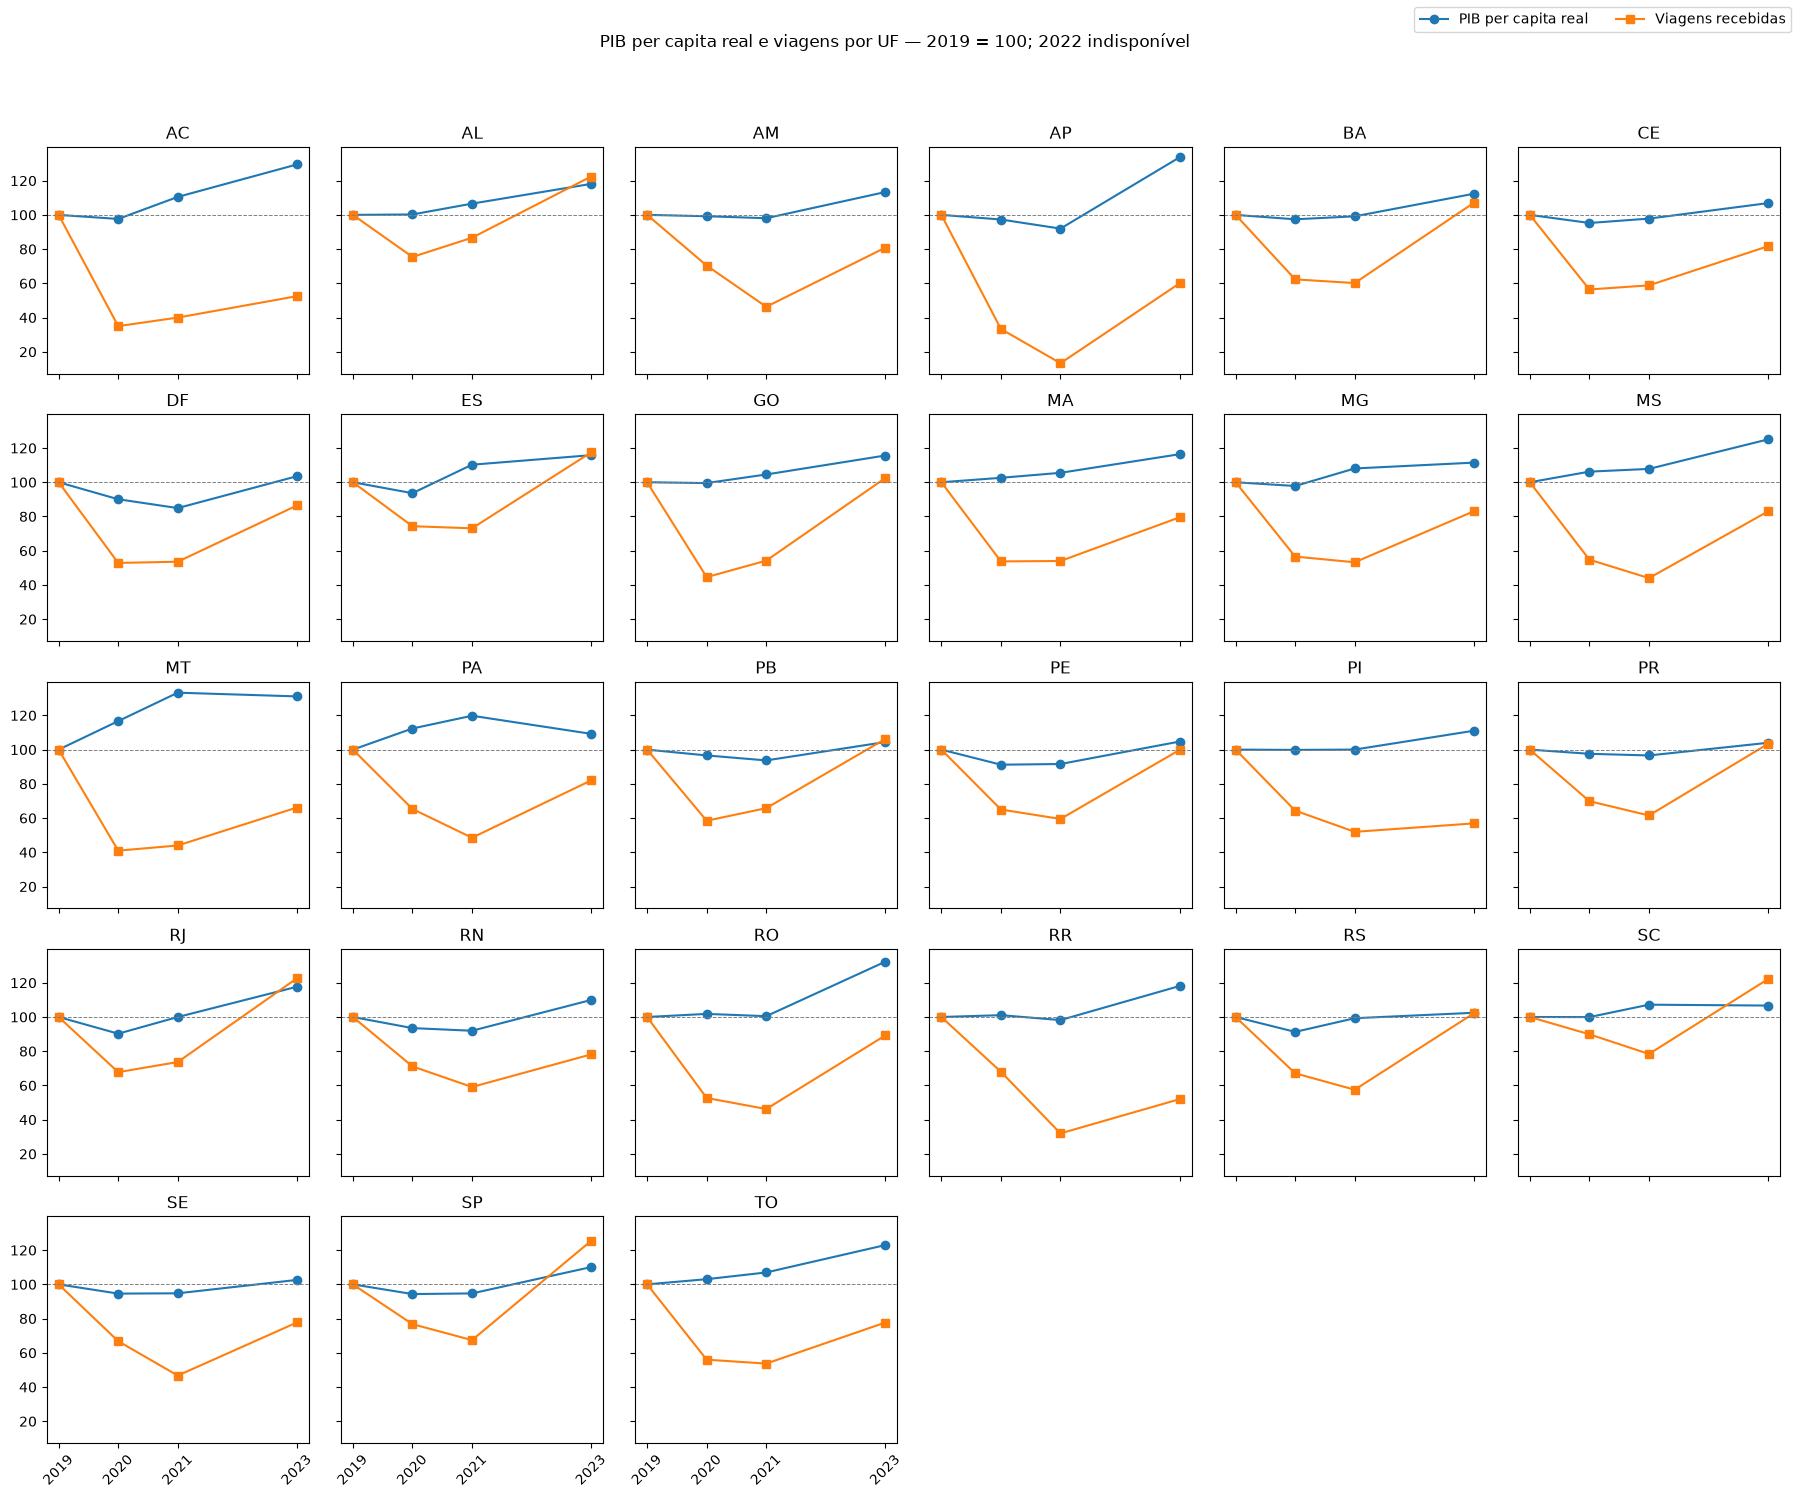

In [132]:
fig_total = grafico_total_por_ano(
    base_pib,
    "viagens_mil",
    destaque=ANOS_PANDEMIA,
    titulo="Viagens nacionais por motivo pessoal — destinos nas 27 UFs",
    rotulo_y="Mil viagens",
)

plt.show()
plt.close(fig_total)

for (ini, fim), var in {PAR_PRINCIPAL_PIB: var_principal_pib,
                        PAR_RECUPERACAO_PIB: var_recuperacao_pib}.items():
    fig = grafico_dispersao_indicador(
        var,
        "pib",
        f"PIB per capita real × viagens recebidas — {ini} → {fim}",
        "Variação do PIB per capita real (%)",
        destacar=("RR", "AP"),
    )
   
    plt.show()
    plt.close(fig)

fig_ind = grafico_indices_duplos(
    base_pib,
    "pib_pc_mil",
    "PIB per capita real",
    titulo="PIB per capita real e viagens por UF — 2019 = 100; 2022 indisponível",
)

plt.show()
plt.close(fig_ind)

In [133]:
contingencia_principal_pib = tabela_contingencia_indicador(var_principal_pib, "pib")
print(contingencia_principal_pib)

viagens_mov  caiu  subiu  Total
pib_mov                        
subiu          17     10     27
Total          17     10     27



#### Analisando o resultado de cima pode-se afirmar que:
O PIB per capita real subiu nas 27 UFs entre 2019 e 2023, por isso a tabela tem uma única linha para cada estado.
Mesmo assim, mostra que as viagens recuaram em 17 UFs e aumentaram em 10.
Como não há UFs com queda do PIB, a tabela não separa grupos(subiram e desceram) a associação será avaliada pela
intensidade das variações (correlação e dispersão).

**Detalhamento 2** —   As variações apresentam associação?

Os cenários sem RR e AP avaliam a sensibilidade do resultado. Eles não justificam excluir essas UFs do resultado principal.

In [134]:
robustez_pib = teste_robustez_indicador(var_principal_pib, "pib", CENARIOS)
print(robustez_pib)


               cenario   n  pearson  p_pearson  spearman  p_spearman  inclinacao  r_critico_5pct  significativo_5pct
0         Todas as UFs  27   -0.389      0.045    -0.297       0.132      -0.902           0.381                True
1          Sem Roraima  26   -0.387      0.051    -0.257       0.205      -0.846           0.388               False
2  Sem Roraima e Amapá  25   -0.303      0.141    -0.177       0.398      -0.694           0.396               False


Ao o que tudo indica as correlações estão bem abaixa de 1 o que indica que não há quase nenhuma correlação.
Não significa que a pib crescimento do pib per capita acompanhou o crescimento das viagens ou sua diminuição.

**Detalhamento 3**  — O que acontece na fase de recuperação (2021 → 2023)?

Esta comparação é complementar, não uma confirmação independente.

Ela envolve o período da pandemia e diferenças na apresentação metodológica da fonte de viagens.

In [135]:
contingencia_recuperacao_pib = tabela_contingencia_indicador(var_recuperacao_pib, "pib")
robustez_recuperacao_pib = teste_robustez_indicador(var_recuperacao_pib, "pib", CENARIOS)
print(contingencia_recuperacao_pib)
print(robustez_recuperacao_pib)

viagens_mov  subiu  Total
pib_mov                  
caiu             3      3
subiu           24     24
Total           27     27
               cenario   n  pearson  p_pearson  spearman  p_spearman  inclinacao  r_critico_5pct  significativo_5pct
0         Todas as UFs  27    0.621      0.001     0.203       0.309       3.497           0.381                True
1          Sem Roraima  26    0.632      0.001     0.200       0.327       3.596           0.388                True
2  Sem Roraima e Amapá  25    0.134      0.522     0.100       0.634       0.329           0.396               False


Entre 2021 e 2023, as viagens recebidas aumentaram nas 27 UFs, e o PIB per capita real aumentou em 24
(caiu em três). Como todas as UFs tiveram aumento das viagens, a tabela de contingência não separa grupos.

A correlação de Pearson com todas as UFs foi positiva e relevante  porem fraca igualmente com a correlação de sperman.

Portanto, o resultado depende de um número pequeno de UFs com variações extremas, em especial o Amapá,
e não é confirmado pela correlação por postos. Nessa fase predomina a retomada pós-pandemia,
comum a todo o país. Não há evidência consistente de associação entre o PIB per capita e a variação
das viagens, e o resultado não permite inferir causalidade.

**Detalhamento 4** —  Impactos da pandemia.

- Como evoluíram as viagens e o PIB per capita em relação a 2019?


In [136]:
print(resumo_anual_pib.round(2))


      viagens_mil  pib_pc_mediana  viagens_vs_2019_pct  pib_mediana_vs_2019_pct
ano                                                                            
2019      17066.0           14.06                  0.0                      0.0
2020      11162.0           14.48                -34.6                      3.0
2021      10274.0           14.38                -39.8                      2.3
2023      17171.0           16.62                  0.6                     18.2


O resultado demonstra que os anos de 2020 e 2021 tiveram uma variação enorme na taxa de viagens, isso indica o impacto da pandemia e o por quê da decisão de exclusão dos dados de 2020 e 2021 na analises.

**Detalhamento 5** — Quais UFs tiveram as maiores e as menores variações do PIB per capita (2019 → 2023)?


In [137]:
print(resumo_choque_indicador(var_choque_pib, "pib", "PIB per capita"))


UFs analisadas                                                            27
PIB per capita caiu                                                       19
Viagens caíram                                                            27
Ambos caíram                                                              19
UFs com ambas as quedas    [AC, AM, AP, PI, CE, RN, PB, PE, SE, BA, MG, E...
dtype: object


A pandemia teve novamente um impacto massivo tanto nas vigens(mostrada da parte 1) quanto agora no pib per capita.

**Detalhamento 6** — Quais UFs tiveram as maiores e as menores variações do PIB per capita (2019 → 2023)?


In [138]:
colunas = ["uf", "pib_var_pct", "viagens_var_pct"]
print("Maiores variações do PIB per capita:")
print(var_principal_pib.nlargest(5, "pib_var_pct")[colunas].round(1))
print("\nMenores variações do PIB per capita:")
print(var_principal_pib.nsmallest(5, "pib_var_pct")[colunas].round(1))

Maiores variações do PIB per capita:
    uf  pib_var_pct  viagens_var_pct
5   AP         33.6            -40.0
0   RO         32.3            -10.8
24  MT         31.1            -33.8
1   AC         29.5            -47.5
23  MS         25.0            -17.0

Menores variações do PIB per capita:
    uf  pib_var_pct  viagens_var_pct
22  RS          2.5              2.2
14  SE          2.6            -22.3
26  DF          3.5            -13.6
20  PR          4.0              3.4
11  PB          4.4              6.2


Os maiores aumentos ocorreram no Amapá (33,6%), em Rondônia (32,3%), no Mato Grosso (31,1%), no Acre (29,5%) e no Mato Grosso do Sul (25,0%).
Os menores aumentos foram os do Rio Grande do Sul (2,5%), de Sergipe (2,6%), do Distrito Federal (3,5%),
do Paraná (4,0%) e da Paraíba (4,4%).

As cinco UFs com maior crescimento do PIB tiveram queda nas viagens recebidas (de −10,8% a −47,5%).
Entre as cinco com menor crescimento, três tiveram aumento nas viagens (RS, PR e PB). O padrão é coerente com a
correlação negativa e frágil encontrada anteriormente, mas descreve apenas os extremos. Além disso, AP, AC e RO têm base
pequena de viagens, o que torna as variações percentuais mais instáveis e volateis demais . Trata-se de associação descritiva, sem
interpretação causal.

#### Análise 12 —  Petróleo × transporte aéreo (Turismo - Thiago)
**Pergunta:** Qual é o impacto do preço do petróleo nos setores de transporte aéreo e rodoviário?



**Detalhamento 1** — Como o preço médio do Brent evoluiu por ano?


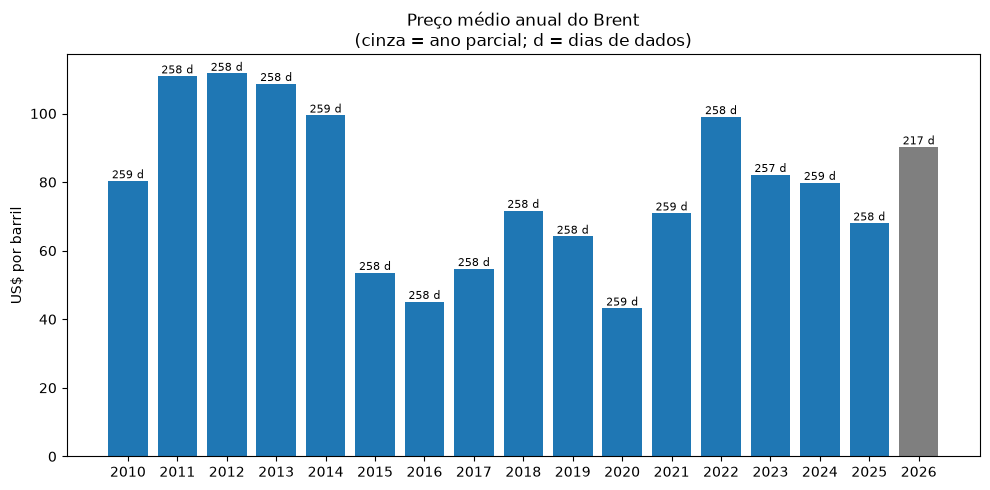

 ano  brent_media  brent_min  brent_max  dias  parcial
2010        80.34      69.55      94.75   259    False
2011       110.91      93.33     126.65   258    False
2012       111.68      89.23     126.22   258    False
2013       108.70      97.69     118.90   258    False
2014        99.49      57.33     115.06   259    False
2015        53.60      36.11      67.77   258    False
2016        45.13      27.88      56.82   258    False
2017        54.74      45.05      67.02   258    False
2018        71.69      50.47      86.29   258    False
2019        64.16      54.91      74.57   258    False
2020        43.21      19.33      68.91   259    False
2021        70.95      51.09      86.40   259    False
2022        99.04      76.10     127.98   258    False
2023        82.17      71.84      96.55   257    False
2024        79.86      69.19      91.17   259    False
2025        68.03      58.92      82.03   258    False
2026        90.22      59.96     118.35   217     True


In [139]:
fig = grafico_brent_anual(brent_ano, "Preço médio anual do Brent")
plt.show(); plt.close(fig)

print(brent_ano[["ano", "brent_media", "brent_min", "brent_max", "dias", "parcial"]].round(2).to_string(index=False))

#### Analisando o resultado de cima pode-se afirmar que:

O Brent cobre todos os anos de 2010 a 2026, com cerca de 258 dias por ano. Só 2026 é parcial (217 dias), e por isso fica fora das comparações.

- As maiores médias foram as de 2012 (US$ 111,68), 2011 (US$ 110,91) e 2013 (US$ 108,70).
- As quedas de 2014 para 2015 a média caiu cerca de 46% (de US$ 99,49 para US$ 53,60). Em 2020 ficou em US$ 43,21, a menor da série, e o mínimo diário foi de US$ 19,33.
- Atlas a média subiu em 2017–2018 e subiu de novo em 2021 (+64%) e em 2022 (US$ 99,04).
- Depois de 2022, a média caiu em 2023, 2024 e 2025 (US$ 68,03).

O período tem ciclos de queda (2014–2016 e 2020) e de alta (2017–2018 e 2021–2022). Isso permite comparar o transporte em cenários diferentes. Os valores são nominais, em dólares.

**Detalhamento 2** — As variações do Brent foram acompanhadas por variações nos voos?



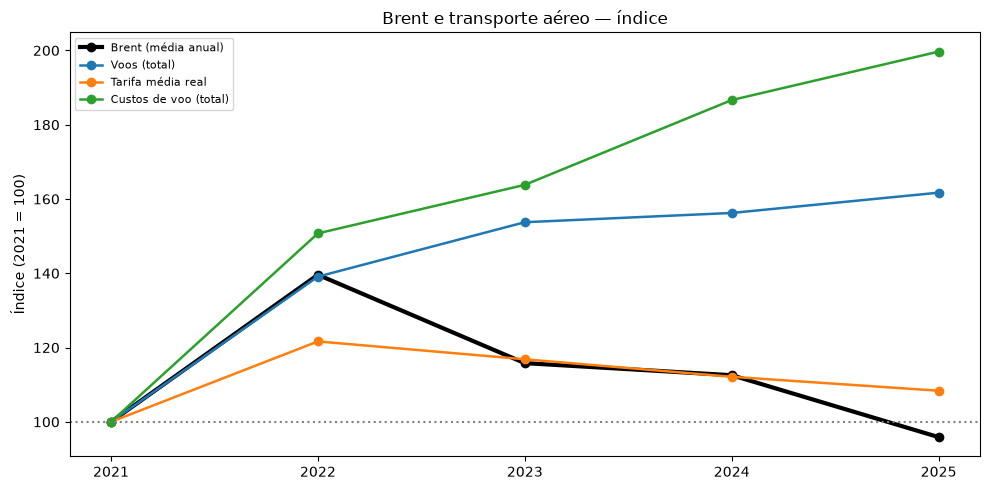

 ano  brent_media_var_pct  voos_dom_var_pct  voos_int_var_pct
2016                  NaN               NaN               NaN
2017                 21.3              -2.8              -0.1
2018                 31.0               1.3              12.5
2019                -10.5              -1.7              -3.7
2020                -32.7             -49.3             -60.5
2021                 64.2              34.1             -12.0
2022                 39.6              34.0              97.8
2023                -17.0               8.0              29.8
2024                 -2.8              -0.6              16.2
2025                -14.8               1.6              14.0

Domésticos:
y_mov      caiu  subiu  Total
brent_mov                    
caiu          3      2      5
subiu         1      3      4
Total         4      5      9

Internacionais:
y_mov      caiu  subiu  Total
brent_mov                    
caiu          2      3      5
subiu         2      2      4
Total         4   

In [140]:
fig = grafico_indices_brent(
    base_aereo,
    {"voos_total": "Voos (total)", "tarifa_real": "Tarifa média real",
     "custo_total": "Custos de voo (total)"},
    ano_base=base_aereo["ano"].min(),
    titulo="Brent e transporte aéreo — índice",
)
plt.show(); plt.close(fig)

colunas = ["ano", "brent_media_var_pct", "voos_dom_var_pct", "voos_int_var_pct"]
print(var_voos[colunas].round(1).to_string(index=False))
print("\nDomésticos:")
print(tabela_contingencia_sinais(var_voos, "brent_media_var_pct", "voos_dom_var_pct"))
print("\nInternacionais:")
print(tabela_contingencia_sinais(var_voos, "brent_media_var_pct", "voos_int_var_pct"))

**Resultado:** com 9 variações anuais (2017–2025), os voos acompanharam o Brent em parte dos anos, sem padrão claro.

- **Domésticos:** em 6 dos 9 anos o Brent e os voos tiveram o mesmo sentido (3 de queda conjunta e 3 de alta conjunta). Nos outros 3 anos, os sentidos foram opostos.
- **Internacionais:** em 4 dos 9 anos houve o mesmo sentido (2 de queda e 2 de alta). Nos outros 5, foram opostos. Isso é o que se esperaria ao acaso.
- **2020:** o Brent caiu 32,7%, mas os voos caíram ainda mais (−49,3% nos domésticos e −60,5% nos internacionais). A causa foi a pandemia, não o preço do petróleo.
- **2021–2022:** o Brent subiu (+64,2% e +39,6%) e os voos também, por causa da retomada pós-pandemia.
- **2023–2025:** o Brent caiu e os voos internacionais subiram todos os anos (+29,8%, +16,2% e +14,0%).

O resultado mostra associação fraca no sentido das variações. A coincidência nos voos domésticos vem em boa parte de 2020–2022, quando a pandemia afetou os dois. O resultado é descritivo e não indica causalidade.

**Detalhamento 3** — As variações do Brent foram acompanhadas por variações na tarifa média real?


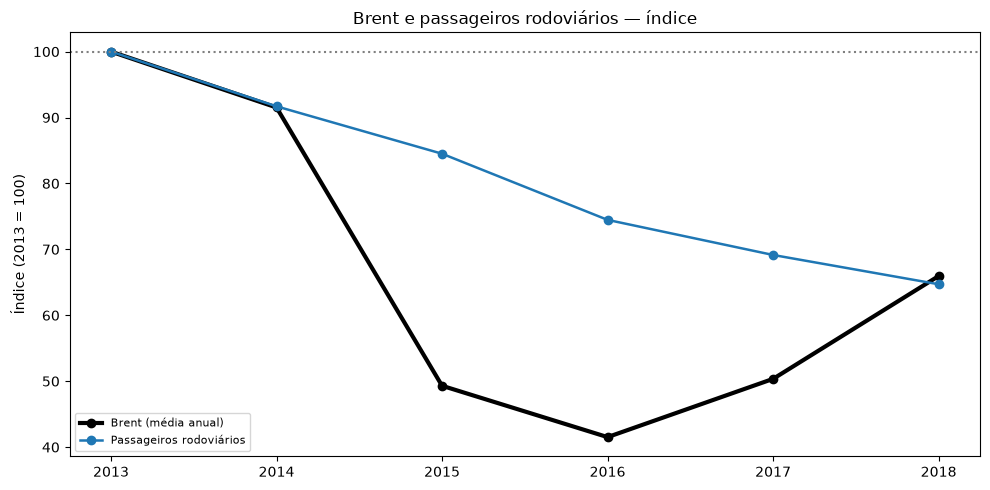

 ano  brent_media_var_pct  tarifa_real_var_pct
2016                  NaN                  NaN
2017                 21.3                 -0.6
2018                 31.0                  2.2
2019                -10.5                  7.0
2020                -32.7                -14.5
2021                 64.2                 19.3
2022                 39.6                 21.7
2023                -17.0                 -3.9
2024                 -2.8                 -4.0
2025                -14.8                 -3.3
y_mov      caiu  subiu  Total
brent_mov                    
caiu          4      1      5
subiu         1      3      4
Total         5      4      9


In [141]:

fig = grafico_indices_brent(
    base_rod, {"passageiros": "Passageiros rodoviários"},
    ano_base=base_rod["ano"].min(), titulo="Brent e passageiros rodoviários — índice",
)
plt.show(); plt.close(fig)

print(var_voos[["ano", "brent_media_var_pct", "tarifa_real_var_pct"]].round(1).to_string(index=False))
print(tabela_contingencia_sinais(var_voos, "brent_media_var_pct", "tarifa_real_var_pct"))

Há 9 variações anuais (2017–2025), a tarifa média real acompanhou o sentido do Brent em 7 dos 9 anos.

- Houve uma queda conjuda de 4 anos , 2020 (Brent −32,7%, tarifa −14,5%) e 2023–2025 (Brent −17,0%, −2,8% e −14,8%; tarifa −3,9%, −4,0% e −3,3%).
- A tarifa variou menos que o Brent na maioria dos anos.

Há associação no sentido das variações, mais clara do que nos voos. Parte dela vem de 2020–2022, quando a pandemia e a retomada afetaram preços e demanda ao mesmo tempo. Com n = 9, o resultado é descritivo e não indica causalidade. O Brent também não é custo direto do combustível, e câmbio e inflação podem influenciar a tarifa.

**Detalhamento 4** — Os custos de voo das empresas acompanharam o Brent?


In [142]:
colunas = ["ano", "brent_media_var_pct", "custo_total_var_pct", "custo_por_voo_var_pct"]
print(var_aereo[colunas].round(1).to_string(index=False))
print(tabela_contingencia_sinais(var_aereo, "brent_media_var_pct", "custo_total_var_pct"))

# Custos por empresa em índice (primeiro ano em comum = 100)
ano0 = base_aereo["ano"].min()
indice_empresas = base_aereo.set_index("ano")[empresas].apply(lambda s: s / s.loc[ano0] * 100)
print(f"\nCustos por empresa (índice, {ano0} = 100):")
print(indice_empresas.round(1))

 ano  brent_media_var_pct  custo_total_var_pct  custo_por_voo_var_pct
2021                  NaN                  NaN                    NaN
2022                 39.6                 50.7                    8.4
2023                -17.0                  8.7                   -1.7
2024                 -2.8                 13.9                   12.1
2025                -14.8                  7.0                    3.4
y_mov      subiu  Total
brent_mov              
caiu           3      3
subiu          1      1
Total          4      4

Custos por empresa (índice, 2021 = 100):
       absa   azul    gol  latam  sideral
ano                                      
2021  100.0  100.0  100.0  100.0    100.0
2022  107.5  146.5  132.8  172.7    130.7
2023   68.1  160.0  142.7  192.8    124.4
2024   82.7  150.6  173.2  236.1      NaN
2025   72.7  151.0  184.0  263.2      NaN


Com apenas 4 variações anuais (2022–2025), o custo total das empresas não acompanhou o Brent de forma consistente.

- No ano de 2022, o Brent subiu 39,6% e o custo total subiu 50,7%. O custo por voo subiu 8,4%.
- Nos anos de 2023 a 2025  o Brent caiu (−17,0%, −2,8% e −14,8%), mas o custo total continuou subindo (+8,7%, +13,9% e +7,0%). O custo por voo oscilou (−1,7%, +12,1% e +3,4%).
- No anos de 2021 a 2025,por empresa, o custo subiu 51,0% na Azul, 84,0% na Gol e 163,2% na Latam. A ABSA ficou 27,3% abaixo de 2021. A Sideral só tem dados até 2023 e não entra no total.

A coincidência de sinais ocorreu em 1 dos 4 anos. Parte do aumento do custo total vem do aumento do número de voos, e por isso o custo por voo é a medida mais adequada. Os valores parecem nominais, então a inflação também pesa. Com n = 4, o resultado é descritivo e não indica causalidade. O Brent também não é custo direto do combustível.


**Detalhamento 5** — As variações do Brent foram acompanhadas por variações nos passageiros rodoviários?

In [143]:
print(var_rod[["ano", "brent_media", "dias", "parcial", "passageiros",
               "brent_media_var_pct", "passageiros_var_pct"]].round(1).to_string(index=False))
print(tabela_contingencia_sinais(var_rod, "brent_media_var_pct", "passageiros_var_pct"))

 ano  brent_media  dias  parcial  passageiros  brent_media_var_pct  passageiros_var_pct
2013        108.7   258    False   57139194.0                  NaN                  NaN
2014         99.5   259    False   52395169.0                 -8.5                 -8.3
2015         53.6   258    False   48287015.0                -46.1                 -7.8
2016         45.1   258    False   42553456.0                -15.8                -11.9
2017         54.7   258    False   39511267.0                 21.3                 -7.1
2018         71.7   258    False   36973241.0                 31.0                 -6.4
y_mov      caiu  Total
brent_mov             
caiu          3      3
subiu         2      2
Total         5      5


Com 5 variações anuais (2014–2018), os passageiros rodoviários caíram em todos os anos, independentemente do Brent.

-Nos anos de 2014 a 2016 o Brent caiu (−8,5%, −46,1% e −15,8%) e os passageiros também (−8,3%, −7,8% e −11,9%).
- No ano de 2017 a 2018  o Brent subiu (+21,3% e +31,0%), mas os passageiros continuaram caindo (−7,1% e −6,4%).
- Os passageiros passaram de 57,1 milhões em 2013 para 37,0 milhões em 2018 (−35,3%).

A coincidência de sinais ocorreu em 3 dos 5 anos, mas só porque os passageiros caíram sempre. A queda parece seguir uma tendência própria do transporte rodoviário, não o preço do petróleo. Os dados de 2018 podem ter quebra de cobertura em alguns estados. Com n = 5, o resultado é descritivo e não indica causalidade.

**Detalhamento 6** — Quais UFs perderam mais passageiros rodoviários entre 2013 e 2018?

Figura salva: C:\Users\Notebook\OneDrive\Documentos\GitHub\Analise-do-Desenvolvimento-Humano-e-Global\data\Turismo\saida\dispersao_tarifa_real_var_pct.png


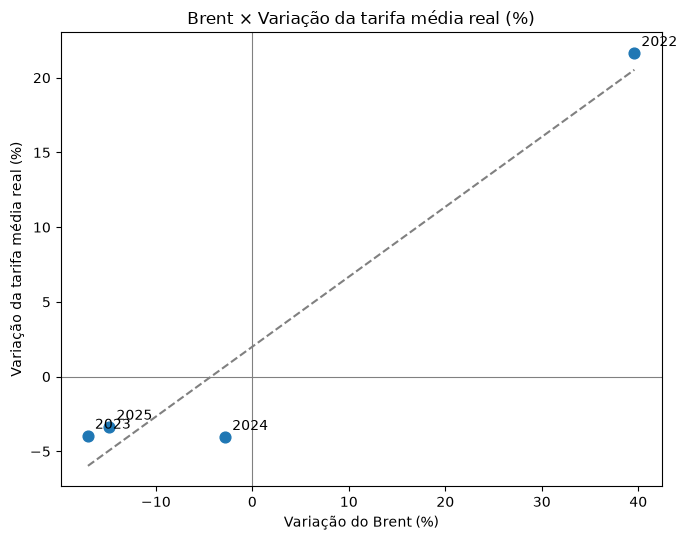

Figura salva: C:\Users\Notebook\OneDrive\Documentos\GitHub\Analise-do-Desenvolvimento-Humano-e-Global\data\Turismo\saida\dispersao_custo_total_var_pct.png


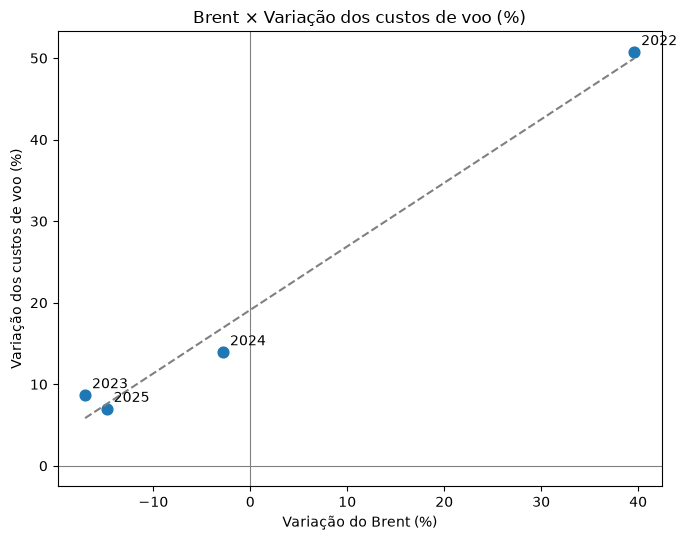

Figura salva: C:\Users\Notebook\OneDrive\Documentos\GitHub\Analise-do-Desenvolvimento-Humano-e-Global\data\Turismo\saida\dispersao_voos_total_var_pct.png


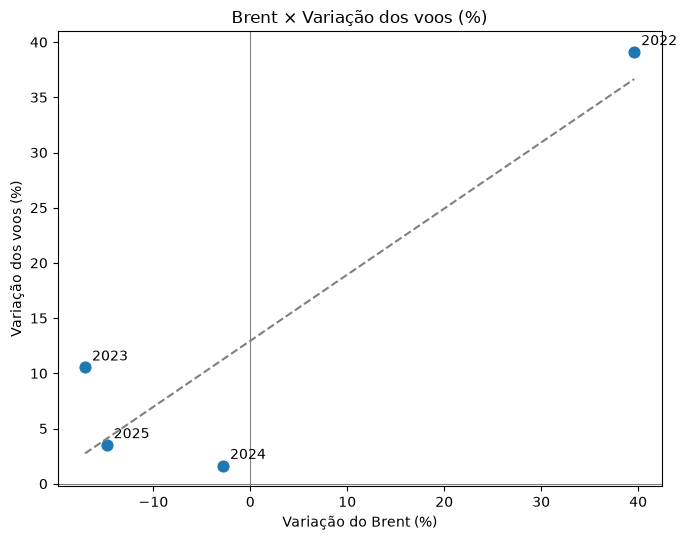

Figura salva: C:\Users\Notebook\OneDrive\Documentos\GitHub\Analise-do-Desenvolvimento-Humano-e-Global\data\Turismo\saida\rodoviario_ufs.png


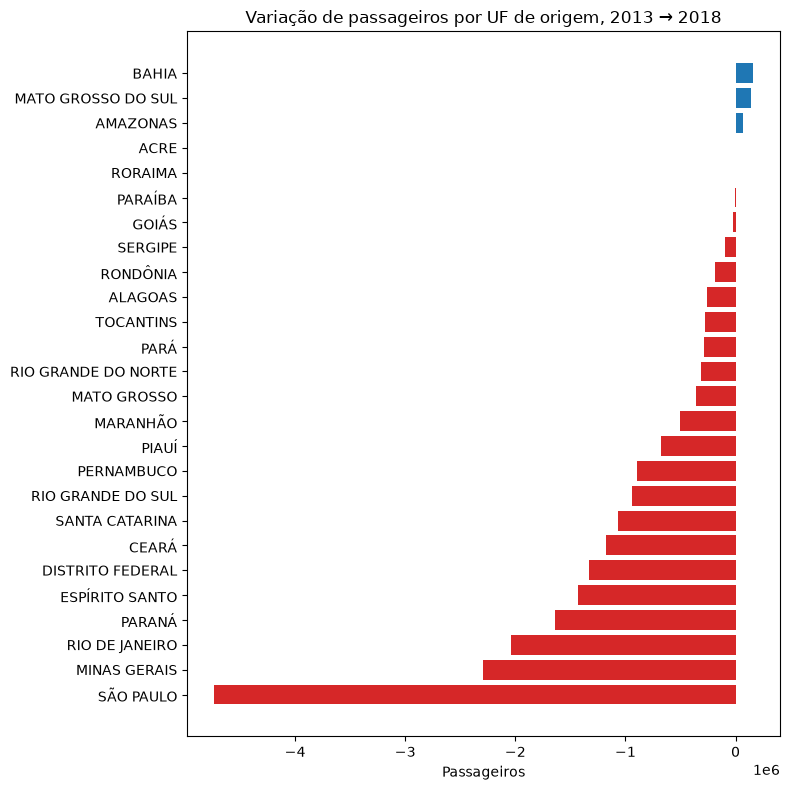

Maiores perdas absolutas:
            uf     inicio       fim    var_abs  var_pct
     SÃO PAULO 12006375.0 7270831.0 -4735544.0    -39.4
  MINAS GERAIS  9232922.0 6935225.0 -2297697.0    -24.9
RIO DE JANEIRO  5050115.0 3013839.0 -2036276.0    -40.3
        PARANÁ  6567229.0 4925317.0 -1641912.0    -25.0
ESPÍRITO SANTO  3173498.0 1743127.0 -1430371.0    -45.1

Maiores ganhos ou menores perdas:
                uf    inicio       fim  var_abs  var_pct
           RORAIMA       0.0    3910.0   3910.0      NaN
              ACRE       0.0    5506.0   5506.0      NaN
          AMAZONAS  124075.0  191648.0  67573.0     54.5
MATO GROSSO DO SUL  620401.0  758033.0 137632.0     22.2
             BAHIA 1722116.0 1881051.0 158935.0      9.2

Total de passageiros 2013 → 2018:
57,139,194 → 36,973,241 (-35.3%)


In [144]:
for y, rotulo in {"tarifa_real_var_pct": "Variação da tarifa média real (%)",
                  "custo_total_var_pct": "Variação dos custos de voo (%)",
                  "voos_total_var_pct": "Variação dos voos (%)"}.items():
    if y not in var_aereo:
        var_aereo = variacoes_anuais(base_aereo.assign(
            voos_total=base_aereo["voos_dom"] + base_aereo["voos_int"]),
            ["brent_media"] + COLS_AEREO + ["voos_total"])
    fig = grafico_dispersao_anos(var_aereo, "brent_media_var_pct", y,
                                 f"Brent × {rotulo}", "Variação do Brent (%)", rotulo)
    salvar_figura(fig, str(SAIDA / f"dispersao_{y}.png"))
    plt.show(); plt.close(fig)

rank = ranking_ufs(rodov_limpo, 2013, 2018)
fig = grafico_barras_uf(rank, "var_abs",
                        "Variação de passageiros por UF de origem, 2013 → 2018",
                        "Passageiros")
salvar_figura(fig, str(SAIDA / "rodoviario_ufs.png"))
plt.show(); plt.close(fig)

print("Maiores perdas absolutas:")
print(rank.head(5).round(1).to_string(index=False))
print("\nMaiores ganhos ou menores perdas:")
print(rank.tail(5).round(1).to_string(index=False))
print("\nTotal de passageiros 2013 → 2018:")
print(f"{rank['inicio'].sum():,.0f} → {rank['fim'].sum():,.0f} "
      f"({(rank['fim'].sum() / rank['inicio'].sum() - 1) * 100:.1f}%)")

A queda foi generalizada, mas mais forte nas UFs com maior volume de passageiros. Os dados de 2018 podem ter quebra de cobertura em alguns estados, então o ranking precisa de cautela. O resultado é descritivo e não indica causalidade.


**Detalhamento 7** — Há associação entre as variações do Brent e as variações das variáveis do transporte?


In [145]:
CENARIOS = {
    "Todos os anos": {},
    "Sem anos parciais do Brent": {"excluir": ANOS_PARCIAIS},
    "Sem pandemia (2020–2021)": {"excluir": ANOS_PANDEMIA},
    "Brent defasado 1 ano": {"defasagem": 1},
}

ys_voos = ["voos_dom_var_pct", "voos_int_var_pct", "voos_total_var_pct", "tarifa_real_var_pct"]
ys_custos = ["custo_total_var_pct", "custo_por_voo_var_pct"]

robustez_voos = teste_robustez_series(var_voos, "brent_media_var_pct", ys_voos, CENARIOS)
robustez_custos = teste_robustez_series(var_aereo, "brent_media_var_pct", ys_custos, CENARIOS)

print(robustez_voos.to_string(index=False))
print(robustez_custos.to_string(index=False))

           variavel                    cenario                                                 anos  n  pearson  p_pearson  spearman  p_spearman  r_critico_5pct  inclinacao  significativo_5pct
   voos_dom_var_pct              Todos os anos 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025  9    0.767      0.016     0.533       0.139           0.666       0.588                True
   voos_dom_var_pct Sem anos parciais do Brent 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025  9    0.767      0.016     0.533       0.139           0.666       0.588                True
   voos_dom_var_pct   Sem pandemia (2020–2021)             2017, 2018, 2019, 2022, 2023, 2024, 2025  7    0.504      0.249     0.000       1.000           0.754       0.279               False
   voos_dom_var_pct       Brent defasado 1 ano       2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025  8    0.263      0.529     0.119       0.779           0.707       0.209               False
   voos_int_var_pct              To

A associação se concentra em 2020–2022, quando a pandemia e a retomada afetaram Brent, voos e tarifas ao mesmo tempo. Fora desse período, não há evidência consistente. Com poucos anos, vários testes e variáveis de confusão (câmbio, inflação edemanda), o resultado é descritivo e não indica causalidade.

**Pergunta 8** — E no transporte rodoviário?


In [146]:
robustez_rod = teste_robustez_series(var_rod, "brent_media_var_pct",
                                     ["passageiros_var_pct"], CENARIOS)
print(robustez_rod.to_string(index=False))

           variavel                    cenario                         anos  n  pearson  p_pearson  spearman  p_spearman  r_critico_5pct  inclinacao  significativo_5pct
passageiros_var_pct              Todos os anos 2014, 2015, 2016, 2017, 2018  5    0.452      0.445       0.7       0.188           0.878       0.031               False
passageiros_var_pct Sem anos parciais do Brent 2014, 2015, 2016, 2017, 2018  5    0.452      0.445       0.7       0.188           0.878       0.031               False
passageiros_var_pct   Sem pandemia (2020–2021) 2014, 2015, 2016, 2017, 2018  5    0.452      0.445       0.7       0.188           0.878       0.031               False
passageiros_var_pct       Brent defasado 1 ano       2015, 2016, 2017, 2018  4    0.897      0.103       0.8       0.200           0.950       0.079               False



Os passageiros rodoviários caíram em todos os anos, o que indica uma tendência própria, independente do Brent. Com apenas 4 ou 5 observações, o teste tem baixo poder e o resultado é descritivo. Ele não indica causalidade e não permite concluir que o Brent não tem efeito.

**Pergunta 9** — Em níveis (e não em variações), o Brent e as variáveis se movem juntos?


In [147]:
niveis_voos = teste_robustez_series(base_voos, "brent_media",
                                    ["voos_dom", "voos_int", "voos_total", "tarifa_real"],
                                    {"Todos os anos (níveis)": {}})
niveis_custos = teste_robustez_series(base_aereo, "brent_media",
                                      ["custo_total", "custo_por_voo"],
                                      {"Todos os anos (níveis)": {}})
print(niveis_voos.to_string(index=False))
print(niveis_custos.to_string(index=False))

   variavel                cenario                                                       anos  n  pearson  p_pearson  spearman  p_spearman  r_critico_5pct  inclinacao  significativo_5pct
   voos_dom Todos os anos (níveis) 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025 10    0.265      0.460    -0.212       0.556           0.632    2166.423               False
   voos_int Todos os anos (níveis) 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025 10    0.116      0.749     0.042       0.907           0.632     259.058               False
 voos_total Todos os anos (níveis) 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025 10    0.237      0.509    -0.103       0.777           0.632    2425.481               False
tarifa_real Todos os anos (níveis) 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025 10    0.902      0.000     0.903       0.000           0.632       4.044                True
     variavel                cenario                         anos

A correlação da tarifa deve ser lida com cautela. Em níveis, as séries têm tendência e dependência temporal, então o valor-p tende a exagerar a evidência. Em variações anuais, a associação da tarifa desapareceu sem os anos de pandemia. Os custos são nominais e a amostra é pequena. O resultado é descritivo e não indica causalidade.

#### Análise 13 — PIB per capita e escolaridade (Educação e Transporte - Gabriel)

**Pergunta:** Como o PIB se relaciona com o nível de escolaridade do país?

**Visualização escolhida:** A análise apresenta a correlação entre PIB per capita e anos médios de escolaridade, uma tabela com as medianas por continente e um gráfico de dispersão com cores por continente. O PIB per capita refere-se a 2007 e a escolaridade a 2005, pois não há dado de escolaridade para 2007.

In [148]:
print("Correlação entre PIB per capita e anos de escolaridade")
correlacoes(df_q6_ok, "gdpPercap", "anos_escolaridade")
print()
print("Medianas por continente")
display(
    df_q6_ok.groupby("continent")[["gdpPercap", "anos_escolaridade"]]
    .median()
    .round(2)
    .sort_values("anos_escolaridade")
)


Correlação entre PIB per capita e anos de escolaridade
Pearson:  0.742
Spearman: 0.858
N:        103

Medianas por continente


,gdpPercap,anos_escolaridade
continent,,
Africa,1463.25,5.11
Asia,4184.55,6.68
Americas,8178.50,8.51
Europe,30470.02,10.89
Oceania,29810.19,11.86


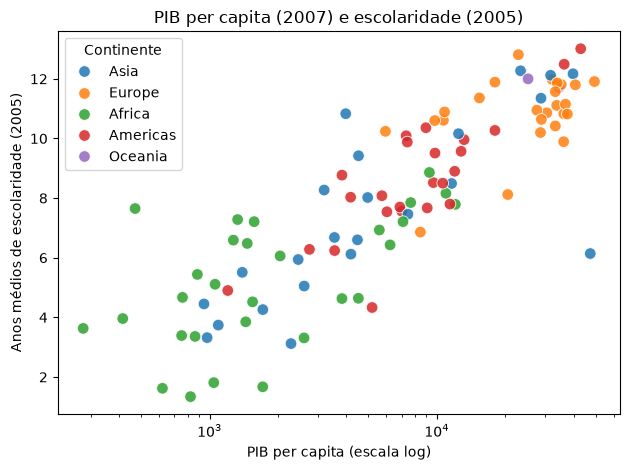

In [149]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=df_q6_ok,
    x="gdpPercap",
    y="anos_escolaridade",
    hue="continent",
    alpha=0.85,
    s=70,
    ax=ax,
)
ax.set_xscale("log")
ax.set_xlabel("PIB per capita (escala log)")
ax.set_ylabel("Anos médios de escolaridade (2005)")
ax.set_title("PIB per capita (2007) e escolaridade (2005)")
ax.legend(title="Continente")
plt.tight_layout()
plt.show()


**Interpretação do grupo:**

Há uma relação positiva e forte entre PIB per capita e anos de escolaridade: Pearson **0,74** e Spearman **0,86**, com **103 países**. A Spearman mais alta indica uma associação monotônica ainda mais clara do que a linear. No gráfico (eixo X em log), África concentra a parte inferior esquerda e Europa/Oceania a parte superior direita. Países mais ricos, neste recorte, também apresentam população adulta com mais anos de estudo.

#### Análise 14 — Gasto público em educação e longevidade (Educação e Transporte - Gabriel)

**Pergunta:** Países com maior gasto público em educação (% do PIB) apresentam maior longevidade?

**Visualização escolhida:** Um gráfico de dispersão relaciona o gasto público em educação (% do PIB) com a expectativa de vida em 2007. As cores identificam os continentes e o tamanho das bolhas representa a população. Também são calculadas as correlações de Pearson e Spearman.

In [150]:
print("Correlação entre gasto em educação (% do PIB) e expectativa de vida")
correlacoes(df_q7_ok, "gasto_educ_pct_pib", "lifeExp")


Correlação entre gasto em educação (% do PIB) e expectativa de vida
Pearson:  0.276
Spearman: 0.397
N:        78


(np.float64(0.275842021284774), np.float64(0.39693218174230843))

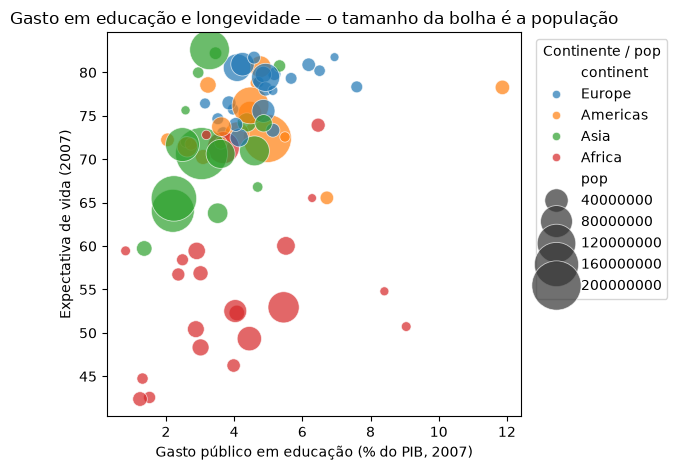

In [151]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=df_q7_ok,
    x="gasto_educ_pct_pib",
    y="lifeExp",
    hue="continent",
    size="pop",
    sizes=(40, 1400),
    alpha=0.7,
    ax=ax,
)
ax.set_xlabel("Gasto público em educação (% do PIB, 2007)")
ax.set_ylabel("Expectativa de vida (2007)")
ax.set_title("Gasto em educação e longevidade — o tamanho da bolha é a população")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Continente / pop")
plt.tight_layout()
plt.show()


**Interpretação do grupo:**

Com **78 países** em 2007, a associação é fraca a moderada: Pearson **0,28** e Spearman **0,40**. A distribuição dos pontos apresenta uma tendência positiva discreta, mas há países com gastos semelhantes e expectativas de vida diferentes. Portanto, os dados indicam uma associação limitada e não permitem concluir que o aumento do gasto em educação, isoladamente, cause maior longevidade.

#### Análise 15 — Infraestrutura de transporte e escolaridade (Educação e Transporte - Gabriel)

**Pergunta:** Como a qualidade da infraestrutura de transporte se relaciona com o nível de escolaridade por país?

**Visualização escolhida:** São utilizados um boxplot para comparar os anos de escolaridade entre faixas de qualidade da infraestrutura e um gráfico de dispersão que relaciona a nota LPI com a escolaridade, identificando os continentes. Os dois indicadores se referem a 2010.

In [152]:
print("Correlação entre nota LPI de infraestrutura e anos de escolaridade")
correlacoes(df_q8_ok, "lpi_infra", "anos_escolaridade")


Correlação entre nota LPI de infraestrutura e anos de escolaridade
Pearson:  0.709
Spearman: 0.716
N:        95


(np.float64(0.7091736901736051), np.float64(0.7164370287279387))

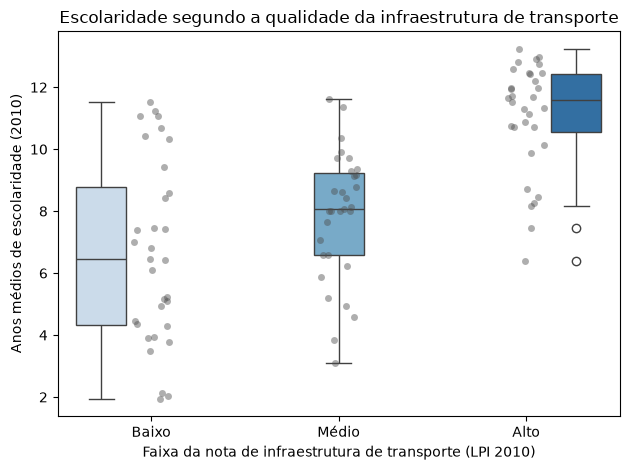

In [153]:
fig, ax = plt.subplots()
sns.boxplot(
    data=df_q8_ok,
    x="faixa_infra",
    y="anos_escolaridade",
    hue="faixa_infra",
    palette="Blues",
    legend=False,
    ax=ax,
)
sns.stripplot(
    data=df_q8_ok,
    x="faixa_infra",
    y="anos_escolaridade",
    color="0.3",
    alpha=0.45,
    size=5,
    ax=ax,
)
ax.set_xlabel("Faixa da nota de infraestrutura de transporte (LPI 2010)")
ax.set_ylabel("Anos médios de escolaridade (2010)")
ax.set_title("Escolaridade segundo a qualidade da infraestrutura de transporte")
plt.tight_layout()
plt.show()


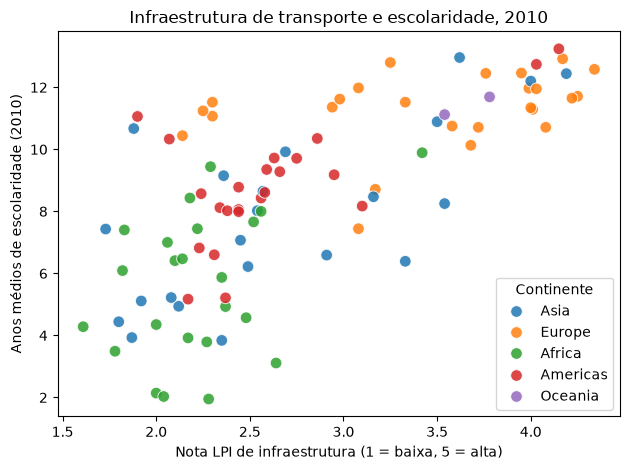

In [154]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=df_q8_ok,
    x="lpi_infra",
    y="anos_escolaridade",
    hue="continent",
    alpha=0.85,
    s=70,
    ax=ax,
)
ax.set_xlabel("Nota LPI de infraestrutura (1 = baixa, 5 = alta)")
ax.set_ylabel("Anos médios de escolaridade (2010)")
ax.set_title("Infraestrutura de transporte e escolaridade, 2010")
ax.legend(title="Continente")
plt.tight_layout()
plt.show()


**Interpretação do grupo:**

Países com melhor nota de infraestrutura de transporte também apresentam mais anos de escolaridade. As correlações foram Pearson **0,71** e Spearman **0,72**, com **95 países**. A mediana de escolaridade sobe da faixa Baixa (**6,44** anos) para a Média (**8,06**) e para a Alta (**11,58**). A variável analisada representa a qualidade da infraestrutura (nota de 1 a 5), e não o valor investido. Os resultados mostram uma associação, mas não demonstram causalidade.

#### Análise 16 — Qualidade das rodovias por região brasileira (Educação e Transporte - Gabriel)

**Pergunta:** Quais regiões brasileiras apresentam pior qualidade de estrada, e qual dimensão da via apresenta maior percentual de trechos em condição ruim ou péssima?

**Visualização escolhida:** Gráficos de barras comparam o percentual da extensão em condição ruim ou péssima por região e por dimensão da via. Um mapa de calor complementa a comparação entre regiões e dimensões (estado geral, pavimento, sinalização e geometria).

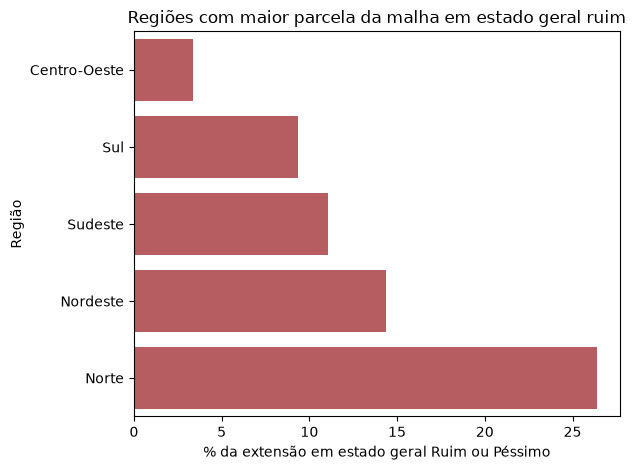

In [155]:
ordem_regioes = tabela_regiao.sort_values("Estado Geral", ascending=True).index.tolist()

fig, ax = plt.subplots()
sns.barplot(
    data=tabela_regiao.reset_index(),
    y="regiao",
    x="Estado Geral",
    order=ordem_regioes,
    color="#c44e52",
    ax=ax,
)
ax.set_xlabel("% da extensão em estado geral Ruim ou Péssimo")
ax.set_ylabel("Região")
ax.set_title("Regiões com maior parcela da malha em estado geral ruim")
plt.tight_layout()
plt.show()


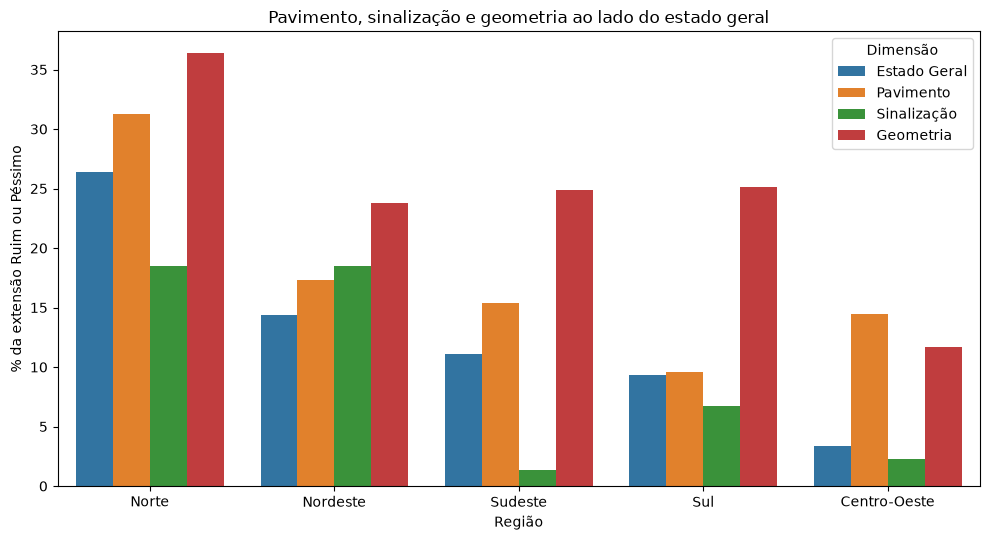

In [156]:
df_dimensoes = (
    tabela_regiao[DIMENSOES]
    .reset_index()
    .melt(id_vars="regiao", var_name="dimensao", value_name="pct_ruim")
)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(
    data=df_dimensoes,
    x="regiao",
    y="pct_ruim",
    hue="dimensao",
    order=["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"],
    ax=ax,
)
ax.set_xlabel("Região")
ax.set_ylabel("% da extensão Ruim ou Péssimo")
ax.set_title("Pavimento, sinalização e geometria ao lado do estado geral")
ax.legend(title="Dimensão")
plt.tight_layout()
plt.show()


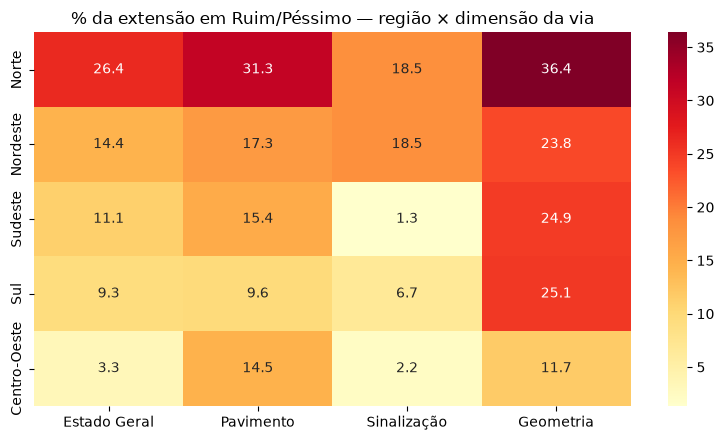

In [157]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(
    tabela_regiao[DIMENSOES].loc[
        ["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"]
    ],
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    ax=ax,
)
ax.set_title("% da extensão em Ruim/Péssimo — região × dimensão da via")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


**Interpretação do grupo:**

A região Norte apresenta a maior parcela da extensão avaliada em condição Ruim ou Péssima no estado geral (**26,39%**), seguida pelo Nordeste (**14,36%**), Sudeste (**11,07%**), Sul (**9,34%**) e Centro-Oeste (**3,35%**). O Norte também apresenta os maiores percentuais em pavimento (**31,31%**) e geometria (**36,39%**). Na sinalização, Norte e Nordeste ficam próximos, em torno de **18,5%**. Considerando o resultado nacional, a geometria é a dimensão mais crítica, com **23,70%** da extensão em condição Ruim ou Péssima. A análise descreve a qualidade da malha, pois não há dados de perda de carga disponíveis.

---

## 5. Síntese dos Principais Insights

### 5.1 Resumo dos achados

**Alguns Padrões**
- Países com maior PIB per capita tendem a ter mais expectativa de vida (0,68), mais anos de escolaridade (0,74) e melhores indicadores de saúde.
- A mortalidade infantil é o fator de saúde mais ligado à expectativa de vida (−0,91), seguida de médicos (0,72) e gasto em saúde (0,63).
- As mulheres vivem mais que os homens, e a vantagem é maior nos países de PIB per capita mais alto (0,59).
- Países com mais comércio internacional tendem a ter PIB per capita maior, mas só de forma moderada (0,35).

**Tendências**
- O preço do Brent teve ciclos de queda (2014–2016 e 2020) e de alta (2017–2018 e 2021–2022). A tarifa aérea real seguiu o sentido do Brent em 7 de 9 anos.
- Os passageiros rodoviários caíram todos os anos de 2014 a 2018 (−35,3% desde 2013), independentemente do Brent.
- Entre 2021 e 2023, as viagens nacionais voltaram a crescer nas 27 UFs, e o PIB per capita real subiu em todas as UFs entre 2019 e 2023.

**Anomalias**
- **Pandemia (2020–2021):** as viagens caíram em todas as 27 UFs, e os voos caíram muito mais que o Brent (−49,3% nos domésticos e −60,5% nos internacionais, contra −32,7%).
- **Inflação:** valores extremos em alguns casos e anos de dados diferentes por país podem influenciar as médias.
- **Obesidade:** há países ricos com obesidade baixa (alguns da Ásia) e países de renda média com obesidade alta. Pode ser relativo devido a cultura dos países.
- **Custo das empresas aéreas:** o custo total subiu de 2023 a 2025 mesmo com o Brent em queda, em parte pelo aumento dos voos e pela inflação.

**Correlações** (2007, salvo indicação)

| Relação | Valor | Leitura |
|---|---|---|
| Mortalidade infantil × expectativa de vida | −0,91 | Muito forte, negativa |
| PIB × escolaridade (PIB 2007, escolaridade 2005) | 0,74 | Forte |
| Médicos × expectativa de vida (83 países) | 0,72 | Forte |
| Infraestrutura de transporte × escolaridade (2010) | 0,71 | Forte |
| PIB × expectativa de vida | 0,68 | Moderada a forte |
| Gasto em saúde × expectativa de vida | 0,63 | Moderada a forte |
| PIB × diferença de expectativa de vida entre mulheres e homens (Spearman, média 1962–2007) | 0,59 | Moderada |
| Gasto em saúde × mortalidade infantil | −0,59 | Moderada a forte, negativa |
| PIB × obesidade | 0,53 | Moderada |
| Comércio × PIB | 0,35 | Moderada |
| Gasto em educação × expectativa de vida | 0,28 | Fraca |
| Desemprego × PIB | −0,15 | Fraca, negativa |
| Homicídios × viagens (2023 → 2024, Pearson) | −0,11 | Próxima de zero |
| Desemprego × crescimento do PIB | 0,04 | Praticamente nula |

### 5.2 Possíveis aplicações práticas

- **Saúde pública:** reduzir a mortalidade infantil (pré-natal, vacinas e atendimento ao recém-nascido) é o caminho mais ligado a uma vida mais longa. Mais médicos e mais gasto em saúde também se associam à longevidade, inclusive entre países de renda parecida, mas no geral o que importa é como o dinheiro é usado.
- **Educação:** a escolaridade acompanha a renda e a infraestrutura de transporte. Como o gasto em educação sozinho tem relação fraca com a longevidade, as políticas devem olhar a qualidade do gasto, e não só o valor.
- **Infraestrutura:** nas rodovias brasileiras, o Norte tem a maior parcela da malha em condição ruim ou péssima (26,39%), e a geometria é a dimensão mais crítica do país (23,70%), o que indica onde priorizar investimentos.
- **Política econômica:** inflação, comércio e desemprego, isoladamente, explicam pouco o crescimento e a renda, apesar de mostrar relações diretas. As decisões precisam considerar o contexto de cada país, e não um único indicador.
- **Turismo e transporte:** a queda da violência ou o crescimento do PIB de um estado não é o sufuciente para prever mais viagens, e o planejamento deve considerar choques como a pandemia. A queda dos passageiros rodoviários parece uma tendência do próprio setor, sem uma relação grande com o petróleo.

### 5.3 Detalhamento por tema

Síntese de cada parte do grupo, com os resultados detalhados.

#### Economia (André)

| Pergunta | Resposta | Resultado |
|---|---|---|
| Países de maior inflação crescem diferente dos de inflação estável? | Sim, moderado | Mediana de crescimento do PIB per capita de 1,80% ao ano (maior inflação) contra 2,48% (menor inflação) |
| Mais comércio internacional → maior PIB per capita? | Sim | Correlação de 0,35 (entre 125 países, 2007) |
| Maior desemprego → menor crescimento ou menor renda? | Não | Correlação de 0,04 com o crescimento e de −0,15 com o PIB per capita (138 países, 2007) |
| A diferença de expectativa de vida entre mulheres e homens possui relação com o PIB? | Sim, moderada | Correlação de Spearman de 0,59 (139 países, média de 1962 a 2007) |

No geral, inflação, comércio e desemprego explicam pouco o crescimento e a renda dos países: só o comércio mostrou relação positiva moderada com o PIB per capita. Já a diferença de expectativa de vida a favor das mulheres cresce junto com a renda.

**Cuidados:** a Venezuela aparece com comércio igual a 0%, o que é impossível, tratado como dado ausente. Na inflação, valores extremos distorcem a média, e por isso a comparação usou a mediana.

#### Saúde (Leandro)

| Pergunta | Resposta | Correlação (2007) |
|---|---|---|
| Gasto em saúde → vida (mesmo PIB) | Sim | 0,63 (positiva nas 3 faixas) |
| Mortalidade infantil explica melhor que o PIB? | Sim | −0,91 vs 0,68 |
| Obesidade cresce com o PIB? | Sim, moderada | 0,53 |
| Médicos → vida (descontando PIB) | Sim | 0,72 (positiva nas 3 faixas) |
| Gasto em saúde → menor mortalidade infantil? | Sim, moderada a forte | −0,59 |

No geral, os indicadores de saúde estão bem ligados à expectativa de vida. A mortalidade infantil
foi o fator mais forte, e tanto o gasto em saúde quanto o número de médicos continuam
importando mesmo quando comparo países de PIB parecido — ou seja, a riqueza ajuda, mas não explica
tudo sozinha. A obesidade foi a única que sobe junto com a riqueza (e mesmo assim de forma só
moderada).

#### Educação e Transporte (Gabriel)

| Pergunta | Recorte | N | Resultado descritivo |
| --- | --- | --- | --- |
| PIB e escolaridade | PIB 2007 × escolaridade 2005 | 103 países | Associação positiva forte (Pearson 0,74; Spearman 0,86) |
| Gasto em educação e longevidade | Ambos em 2007 | 78 países | Associação fraca/moderada (Pearson 0,28; Spearman 0,40) |
| Infraestrutura e escolaridade | LPI 2010 × escolaridade 2010 | 95 países | Mediana de estudo sobe de 6,44 para 11,58 anos da faixa baixa para a alta |
| Rodovias por região | CNT, extensão ponderada | 5 regiões do Brasil | Norte com pior estado geral; geometria é a dimensão nacionalmente mais crítica |



#### Turismo (Thiago)

| Pergunta | Resposta | Resultado |
|---|---|---|
| Existe correlação entre turismo e violência no Brasil? | Não | Os homicídios caíram em 25 das 27 UFs, e as viagens aumentaram em 15 e diminuíram em 10. Correlações próximas de zero (Pearson −0,11 e Spearman −0,04) |
| O volume de viagens acompanha o PIB per capita das UFs? | Não | O PIB per capita real subiu nas 27 UFs entre 2019 e 2023, mas as viagens caíram em 17. A associação foi negativa e fraca |
| O preço do petróleo (Brent) afeta o transporte aéreo? | Em parte | Os sinais coincidiram em 7 de 9 anos na tarifa real, 6 de 9 nos voos domésticos e 4 de 9 nos internacionais. A associação se concentra em 2020–2022 |
| O preço do petróleo (Brent) afeta o transporte rodoviário? | Não | Os passageiros caíram 35,3% de 2013 a 2018, inclusive quando o Brent subiu (2017–2018) |

No geral, a queda da violência e o crescimento do PIB das UFs não acompanharam o turismo, e só a tarifa aérea seguiu o sentido do Brent, mesmo assim concentrada nos anos de pandemia e retomada. O principal choque foi a pandemia: as viagens caíram nas 27 UFs em 2020 e 2021.


#### Conclusões e limitações — Turismo (Thiago)

**Violência e turismo.** A influência da violência sobre o turismo permanece inconclusiva: a comparação 2023 → 2024 não mostra associação linear nem monotônica expressiva. Isso não significa que a violência não influencie as viagens, e sim que esta análise não consegue identificar nem quantificar essa influência. As principais limitações são: poucos anos de dados, uma única variação anual por UF, a violência ser medida apenas pela taxa de homicídios, os dados estaduais esconderem diferenças entre municípios, os erros amostrais das viagens não terem sido considerados e a pandemia dificultar separar outros fatores.

**Petróleo e transporte.** No transporte aéreo, a tarifa real acompanhou o sentido do Brent mais do que os voos, mas essa associação se concentra em 2020–2022 e desaparece sem os anos de pandemia. O custo total das empresas não acompanhou o Brent, e a alta pode vir do crescimento dos voos e da inflação, pois os valores parecem nominais. 

---

## 6. Conclusão e Reflexão


### Quais foram os maiores desafios?

- **Integrar bases de fontes diferentes.** Em vários casos, os nomes dos países mudavam entre o Gapminder e as outras bases (por exemplo, "Czechia' e 'Czech Republic"), e foi preciso criar dicionários de correção ou usar códigos de país para juntar as tabelas.
- **Dados incompletos e de períodos diferentes.** Os dados de referencia do desemprego só existe a partir de 1991, o indicador de médicos tem poucos países (83 em 2007) e algumas comparações precisaram unir anos vizinhos (PIB de 2007 com escolaridade de 2005).
- **Formatos e valores problemáticos.** Os arquivos CSV vinham com codificações e separadores diferentes, a Venezuela aparecia com comércio igual a 0% e valores extremos distorciam médias, como na inflação, tendo que retirar para não atrapalhar a média geral.
- **Efeito da pandemia.** Em 2020 e 2021, a queda das viagens e dos voos escondia outras relações, e foi preciso citar esses anos à parte. Apesar de tudo, faz parte da história e deve ser analisado
- **Trabalhar em grupo.** Cada integrante cuidou de um tema, e foi preciso manter uma estrutura única e organizada em um só notebook. Apesar disso, cada um lida com o tema de uma maneira diferente, o que também torna difícil de unificar para colocar em um único notebook.

### O que foi aprendido?

Aprendemos a importancia de preparar os dados antes de qualquer análise, o que era algo esperado, mas colocar em prática  removendo duplicados, tratar ausentes e padronizar nomes e unidades, e documentar essas decisões nos faz perceber a importancia para fazer a leitura dos dados. Também aprendemos que correlação não é causalidade, olhamos quantos países entravam em cada análise e evitamos tirar conclusões causais, já que as vezes mesmo tendo uma relação entre 2 assuntos, eles podem não ser o suficiente para justificar a análise. Criar funções reutilizáveis, como "grafico_dispersao" e "grafico_barras", evitou repetir código e ajuda na organização do notebook.

### Como essa experiência ajudou no desenvolvimento de habilidades analíticas?

O trabalho nos ajudou a formular perguntas que podem ser respondidas com dados e a escolher os indicadores certos para cada uma. Com isso podemos desenvolver o pensamento crítico ao checar o tamanho da amostra, as limitações e outras explicações possíveis, como a pandemia e a inflação. Também treinamos a comunicação, ao transformar números em interpretações com gráficos e tabelas em aplicações práticas, e o trabalho em equipe, ao dividir os temas, padronizar a estrutura e integrar tudo em um único trabalho.


---

## Referências


- ANAC — Agência Nacional de Aviação Civil. *Anuário do Transporte Aéreo 2025* (Fig 2.1, Fig 6.1 e Fig 7.8). Disponível em: https://www.gov.br/anac/pt-br/assuntos/dados-e-estatisticas/mercado-do-transporte-aereo/panorama-do-mercado/anuario-transporte-aereo.
- BANCO MUNDIAL. *Inflation, consumer prices (annual %)* (FP.CPI.TOTL.ZG). Disponível em: https://data.worldbank.org/indicator/FP.CPI.TOTL.ZG.
- BANCO MUNDIAL. *Logistics Performance Index: Quality of trade and transport-related infrastructure (1=low to 5=high)* (LP.LPI.INFR.XQ; arquivo `API_LP.LPI.INFR.XQ_DS2_en_csv_v2_5744.csv`). Disponível em: https://data.worldbank.org/indicator/LP.LPI.INFR.XQ.
- BANCO MUNDIAL. *GDP per capita growth (annual %)* (NY.GDP.PCAP.KD.ZG). Disponível em: https://data.worldbank.org/indicator/NY.GDP.PCAP.KD.ZG.
- BANCO MUNDIAL. *Trade (% of GDP)* (NE.TRD.GNFS.ZS). Disponível em: https://data.worldbank.org/indicator/NE.TRD.GNFS.ZS.
- BANCO MUNDIAL. *Unemployment, total (% of total labor force) (modeled ILO estimate)* (SL.UEM.TOTL.ZS). Disponível em: https://data.worldbank.org/indicator/SL.UEM.TOTL.ZS.
- BANCO MUNDIAL. *Life expectancy at birth, male (years)* (SP.DYN.LE00.MA.IN). Disponível em: https://data.worldbank.org/indicator/SP.DYN.LE00.MA.IN.
- BANCO MUNDIAL. *Life expectancy at birth, female (years)* (SP.DYN.LE00.FE.IN). Disponível em: https://data.worldbank.org/indicator/SP.DYN.LE00.FE.IN.
- CNT — Confederação Nacional do Transporte. *Anuário CNT do Transporte 2022: Rodoviário — 1.5.4.1 Linhas interestaduais (superiores a 75 km)* (arquivo `ROD_1_5_4_1_1.xlsx`). Disponível em: <https://anuariodotransporte.cnt.org.br/2022/Rodoviario/1-5-4-1-/-Linhas-interestaduais-(superiores-a-75-km)>.
- CNT — Confederação Nacional do Transporte. *Pesquisa CNT de Rodovias* (arquivo `qualidade_rodovias.xlsx`). Disponível em: https://pesquisarodovias.cnt.org.br.
- GAPMINDER FOUNDATION. *Gapminder Data* (arquivo `gapminder_full.csv`). Disponível em: https://www.gapminder.org/data/.
- IBGE — Instituto Brasileiro de Geografia e Estatística. *Pesquisa Nacional por Amostra de Domicílios Contínua*. Tabela 7266: viagens nacionais por motivo pessoal, por principal Unidade da Federação de destino. SIDRA. Disponível em: https://sidra.ibge.gov.br/tabela/7266.
- INVESTING.COM. *Petróleo Brent Futuros: dados históricos*. Disponível em: https://br.investing.com/commodities/
- IPEA; FÓRUM BRASILEIRO DE SEGURANÇA PÚBLICA. *Atlas da Violência*. Taxa de homicídios por UF. Disponível em: https://www.ipea.gov.br/atlasviolencia/.
- IPEADATA. *PIB Estadual per capita — preços de mercado (preços de 2010)*. Disponível em: http://www.ipeadata.gov.br.
- IPEADATA; FIPE. *IPC (FIPE) — taxa de inflação (% a.a.)* (FIPE_FIPE0001). Disponível em: http://www.ipeadata.gov.br.
- OUR WORLD IN DATA. *Total health spending per person* (arquivo `gasto_saude_per_capita.csv`). Disponível em: https://ourworldindata.org/grapher/annual-healthcare-expenditure-per-capita.
- OUR WORLD IN DATA. *Medical doctors per 1,000 people* (arquivo `medicos_por_1000_habitantes.csv`). Disponível em: https://ourworldindata.org/grapher/physicians-per-1000-people.
- OUR WORLD IN DATA. *Child mortality* (arquivo `mortalidade_infantil.csv`). Disponível em: https://ourworldindata.org/child-mortality.
- OUR WORLD IN DATA. *Share of adults who are obese* (arquivo `taxa_obesidade.csv`). Disponível em: https://ourworldindata.org/grapher/share-of-adults-defined-as-obese.
brent-oil-historical-data.
- OUR WORLD IN DATA. *Average years of schooling* (arquivo `mean-years-of-schooling-long-run.csv`). Dados de Barro e Lee (2015) e Lee e Lee (2016). Disponível em: https://ourworldindata.org/grapher/mean-years-of-schooling-long-run.


